<a href="https://colab.research.google.com/github/farahdinaariff/Data-Science-Project/blob/main/TropicalPV_Probabilistic_Solar_Forecasting_v6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# TropicalPV — Probabilistic Solar Irradiance Forecasting Under Tropical Climate Uncertainty
### Notebook v6 — consolidated, self-contained, validated against the Tropical PV Dataset Assessment data

**MSc Data Science 7FTC2001 — Farah Dina Esa Mahmud Ariff**

Deterministic (LSTM, GRU) vs. uncertainty-quantifying (MC-Dropout LSTM, Quantile-Regression GRU)
deep learning for short-horizon solar irradiance forecasting, trained at Darwin and evaluated
zero-shot across a tropical / equatorial climate gradient.

---
## How this notebook is built (read this first)

This is a **single self-contained notebook**. There are no `import` statements from local `.py`
files, no helper scripts, no `%run`, no cloned repos, no ZIP packages. Every function and class used
lives in the cells below. The two data-acquisition notebooks (Open-Meteo, Open Electricity) are
included as an optional appendix, switched off by default.

Three structural properties make it finish where the previous version could not:

1. **Bounded memory.** No raw file is ever fully materialised in RAM. The 1-second DKASC Darwin
   files are aggregated to hourly *while streaming*, in fixed-size chunks, reading only the
   columns actually needed. Peak RAM is a function of `CHUNK_ROWS`, not of file size.
2. **Checkpoint-and-resume.** Every expensive stage writes a small artifact to Drive and reloads
   it if present. A runtime restart costs seconds, not the whole run. No cell depends on a
   variable that only exists because some earlier cell happened to still be in memory.
3. **Degrade, never crash.** A missing or malformed file is recorded in a load ledger and the
   site is skipped. Downstream stages iterate over whatever loaded successfully.

Run order: top to bottom, once. `Runtime > Run all` is expected to work.

---
## v5 → v6 change log (read with Part 15)

The analytical method, phase order, features, thresholds, models, hyper-parameters, splits,
metrics and seeds are **unchanged**. Changes fall into three groups, each marked `v6` in the code.

| # | Change | Type | Why | Effect on results |
|---|---|---|---|---|
| 1 | Folder discovery accepts `Data_*` as well as `Data-*`; manifest matches folders by pattern | Technical | New Drive layout; v5 stopped with "no Data-* folders" | None |
| 2 | Data checkpoints keyed by a fingerprint of the input files | Technical | v5 would silently reload the OLD `hourly_raw` after the data changed | None (prevents stale results) |
| 3 | Solar geometry evaluated at the sample centre of each hourly bin (`CFG.GEOMETRY_TIMING`) | **Correctness** | v5 evaluated the sun at HH:00 for an HH:00–HH:59 mean (≈30 min early); visible as two branches in v5 Figure 8 | kt, QC flags and all metrics change. Set `"interval_start"` to reproduce v5 |
| 4 | NSRDB reader uses the file's own `Time Zone`; missing variables stay NaN | Correctness | Himawari files are UTC; v5 filled absent columns with a sample count | None for the v5 Florida files |
| 5 | Singapore source: NSRDB Himawari PSM v3 (NASA POWER no longer on Drive) | **Data substitution** | Forced by the new dataset | Singapore results not comparable with v5 |
| 6 | EXTENDED sites added as zero-shot evaluation sites only (`CFG.SITE_SET`) | Scope (switchable) | Uses the assessed datasets without changing the training design | More rows in Parts 5, 5A, 12. `"CORE"` restores four roles |
| 7 | New Part 1.0 raw inventory and Part 3A data validation (report-only, plus FAIL exclusion) | Validation | Requirement: validate before analysis | Sites with a wrong time basis or unit are excluded, loudly |
| 8 | Primary site can no longer silently fall back to another site | Correctness | v5 `MODEL_SITE` fell back to the first loaded site | Run stops instead of changing the research question |
| 9 | Part 14 seasonal-conditioning finding restored (`piv` overwritten in 11A) | Bug | Finding was silently missing from v5 output | O3 line now printed |
| 10 | Multi-site figure layouts wrap; colours for new sites; Figure 14 bar offsets generalised | Plotting | 10 sites in one row = 34-inch figures; KeyError on new site colours | Figures only |
| 11 | Leakage diagnostic for short-gap interpolation (report only) | Transparency | Interpolation uses the value after the gap | None (quantified, not changed) |

---
## Research narrative structure

This notebook is organised as a single continuous argument. The table maps the
research structure onto the executable parts, so a reader can follow the story
without reading code.

| # | Research stage | Notebook parts |
|---|---|---|
| 1 | Research objectives and questions | Preamble, Part 1 |
| 2 | Dataset and energy context | Parts 1–3 (1.0 raw inventory) |
| 3 | Data quality and preprocessing | **Part 3A (Figures V1–V2)**, Part 4 |
| 4 | Exploratory data analysis | Part 5 (Figures 1–10) |
| 5 | **Energy-system insights** | **Part 5A (Figure 16)** |
| 6 | Feature engineering and screening | Parts 4.2, 5.1 |
| 7 | **Baseline models** | **Part 8A** |
| 8 | Proposed ML architectures | Parts 6–8 |
| 9 | Deterministic forecasting results | Part 9 (Figures 11–12) |
| 10 | **Probabilistic / uncertainty analysis** | Part 9, **Part 9A (Figure 17)** |
| 11 | **Error and residual analysis** | **Part 9B (Figure 18)** |
| 12 | **Extreme-condition and ramp analysis** | Part 10, **Part 10A (Figure 19)** |
| 13 | Proxy validation | Part 11, **Part 11A (Figure 20)** |
| 14 | **Robustness and sensitivity** | **Part 12A (Figure 21)** |
| 15 | Cross-climate generalisation | Part 12 (Figure 14) |
| 16 | **Grid-integration implications** | Part 13, **Part 13A (Figure 22)** |
| 17 | **Comprehensive comparison and findings** | **Parts 14A–14B (Figure 23)**, Part 14 |
| 18 | Limitations and future research | Part 15 |

Parts in **bold** were added in the extended analysis. They exist to close specific
weaknesses identified in the first executed run, not to add volume: a missing naive
reference set, single-seed results with no significance testing, a ramp definition
contaminated by dawn/dusk geometry, prediction intervals that were not calibrated,
a proxy comparison made on unmatched samples, and results reported only at one
forecast horizon.

**Before re-running:** enable a GPU runtime (*Runtime → Change runtime type → GPU*).
The extended sections retrain models across seeds, horizons and hyperparameters;
the original CPU run took over two hours. All heavy stages are checkpointed, so an
interrupted run resumes rather than restarting.

---

## PART 0 — Runtime setup and configuration

One configuration object. Change things here, nowhere else.

`MODE = "SMOKE"` runs the identical code path end-to-end with capped epochs and capped rows —
use it once to confirm the notebook completes in your environment (~5–8 min). `MODE = "FULL"`
is the real run. **The code path is the same**; only sizes differ. This is not a "test version".

In [ ]:
import os, sys, re, gc, json, math, time, random, hashlib, zipfile, warnings, textwrap
from pathlib import Path
from datetime import datetime, timedelta

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import PercentFormatter

warnings.filterwarnings("ignore")
pd.set_option("display.width", 190)
pd.set_option("display.max_columns", 60)
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160, "font.size": 9,
    "axes.grid": True, "grid.alpha": 0.25, "axes.spines.top": False,
    "axes.spines.right": False, "figure.autolayout": True,
})

IN_COLAB = "google.colab" in sys.modules or os.path.exists("/content")


class CFG:
    # ---- environment -------------------------------------------------------
    # Environment variables exist only so the identical notebook can be executed
    # headless in a test harness; on Colab the defaults below apply.
    MODE = os.environ.get("TROPICALPV_MODE", "FULL")      # "SMOKE" | "FULL"
    SEED = 42

    # Root that CONTAINS the Data_* (or legacy Data-*) folders. If the folders are
    # not found here, Part 1 searches My Drive and reports where they actually are.
    DRIVE_ROOT = os.environ.get("TROPICALPV_ROOT", "/content/drive/MyDrive")
    ARTIFACT_DIRNAME = "_tropicalpv_artifacts"

    # ---- dataset scope (v6) -------------------------------------------------
    # "CORE"     : the four roles of the original design only
    #              (Darwin target, Alice proxy, Singapore equatorial, NSRDB-Florida if present).
    # "EXTENDED" : CORE + the additional tropical/equatorial ground and satellite sites from
    #              the Tropical PV Dataset Assessment, used ONLY as zero-shot cross-climate
    #              evaluation sites (Part 12) and in EDA. Training is still Darwin-only.
    SITE_SET = "EXTENDED"
    PRIMARY_SITE = "DARWIN"       # the run stops if this site fails to load; never silently replaced
    DARWIN_YEARS = (2021, 2022, 2023)   # unchanged from v5

    # ---- timing convention for solar geometry (v6 correctness fix) ------------
    # "sample_centre"  : geometry evaluated at the mean sample time inside each hourly bin
    #                    (the time the hourly mean actually represents).  Default.
    # "interval_start" : v5 behaviour — geometry at HH:00 although GHI is the HH:00-HH:59 mean.
    #                    Kept ONLY so the v5 numbers can be reproduced for comparison.
    GEOMETRY_TIMING = "sample_centre"
    TIMING_WARN_MIN, TIMING_FAIL_MIN = 45, 120   # diurnal-alignment thresholds (minutes)

    # ---- ingestion ---------------------------------------------------------
    CHUNK_ROWS = 400_000          # streaming chunk size; controls peak RAM
    TARGET_FREQ = "h"             # modelling resolution

    # ---- physics / QC ------------------------------------------------------
    GHI_MAX = 1400.0              # W/m^2 physical ceiling
    NEG_TOLERANCE = -10.0         # night-time sensor offset tolerated then zeroed
    KT_MAX = 1.30                 # clear-sky index ceiling (cloud enhancement)
    DAYLIGHT_CS_MIN = 20.0        # W/m^2 clear-sky threshold defining "daylight"
    MAX_INTERP_GAP_H = 3          # gaps <= this are interpolated; longer are left NaN

    # ---- supervised problem -------------------------------------------------
    LOOKBACK = 24                 # hours of history (selected in Part 8B on matched validation data)
    HORIZON = 1                   # hours ahead (t+1)
    RAMP_KT_THRESHOLD = 0.35      # |d(kt)/dt| defining a ramp event
    TRAIN_FRAC, VAL_FRAC = 0.70, 0.15   # chronological, never shuffled

    # ---- models -------------------------------------------------------------
    UNITS = 64
    DROPOUT = 0.20
    EPOCHS = 60
    BATCH = 128
    PATIENCE = 8
    MC_PASSES = 50
    QUANTILES = [0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95]
    PI_LOW, PI_HIGH = 0.10, 0.90  # headline 80% prediction interval

    # ---- housekeeping --------------------------------------------------------
    FORCE_REBUILD = False         # True = ignore existing checkpoints
    MAX_ROWS_PER_FILE = None      # set by SMOKE


if CFG.MODE == "SMOKE":
    CFG.EPOCHS, CFG.PATIENCE, CFG.MC_PASSES = 3, 2, 10
    CFG.MAX_ROWS_PER_FILE = 300_000

# ---- seeds: every stochastic library, set once here --------------------------
os.environ["PYTHONHASHSEED"] = str(CFG.SEED)
random.seed(CFG.SEED)
np.random.seed(CFG.SEED)

# ---- Drive mount (silently skipped when not on Colab) -----------------------
if IN_COLAB:
    try:
        from google.colab import drive
        if not os.path.ismount("/content/drive"):
            drive.mount("/content/drive")
    except Exception as e:                                   # pragma: no cover
        print(f"[warn] Drive mount skipped: {e}")

DATA_PREFIXES = ("data_", "data-")          # v6: new Drive layout uses "Data_", v5 used "Data-"


def is_data_dir(p: Path) -> bool:
    return p.is_dir() and p.name.lower().startswith(DATA_PREFIXES)


def find_data_root(declared: str) -> Path:
    """Locate the folder that CONTAINS the Data_* / Data-* directories.

    A wrong DRIVE_ROOT is the single most common first-run failure, and it
    surfaces later as a confusing 'no site loaded' error. This resolves it up
    front: the declared root is used if it holds any Data folder, otherwise the
    usual Drive locations are searched (shallowly) for one.
    """
    def holds_data(r: Path) -> bool:
        try:
            return r.exists() and any(is_data_dir(c) for c in r.iterdir())
        except (PermissionError, OSError):
            return False

    p = Path(declared)
    if holds_data(p):
        return p
    for r in [Path("/content/drive/MyDrive"), Path("/content/drive/My Drive"),
              Path("/content"), Path.cwd()]:
        if holds_data(r):
            print(f"[warn] data root auto-detected: {r}")
            return r
        try:
            for depth1 in sorted(c for c in r.iterdir() if c.is_dir())[:200]:
                if holds_data(depth1):
                    print(f"[warn] data root auto-detected: {depth1}")
                    return depth1
        except (PermissionError, OSError, FileNotFoundError):
            continue
    return p


ROOT = Path(CFG.DRIVE_ROOT)
ART = ROOT / CFG.ARTIFACT_DIRNAME
FIGDIR = ART / "figures"

# NOTE: directories are deliberately NOT created here. Creating them before the
# data root is verified would write real folders onto the local VM disk at
# /content/drive/... whenever Drive is not mounted, and Colab then refuses to
# mount Drive at all ("Mountpoint must not already contain files"). Creation is
# deferred to Part 1, after the root has been confirmed to hold the data.

DRIVE_MOUNTED = (not IN_COLAB) or os.path.ismount("/content/drive") \
    or Path("/content/drive/MyDrive").exists()
if not DRIVE_MOUNTED:
    print("\n  !! Google Drive is NOT mounted. Run drive.mount('/content/drive'),\n"
          "     complete the authorisation prompt, then re-run this cell.\n"
          "     Nothing has been written to disk.\n")

print(f"Mode        : {CFG.MODE}")
print(f"Site set    : {CFG.SITE_SET}   primary site: {CFG.PRIMARY_SITE}")
print(f"Geometry    : {CFG.GEOMETRY_TIMING}")
print(f"Data root   : {ROOT}   exists={ROOT.exists()}")
print(f"Artifacts   : {ART}")

# ---- environment record (reproducibility) -----------------------------------
import platform
ENV_VERSIONS = {"python": platform.python_version(), "numpy": np.__version__,
                "pandas": pd.__version__, "matplotlib": matplotlib.__version__}
for _m in ("scipy", "pyarrow", "tensorflow"):
    try:
        ENV_VERSIONS[_m] = __import__(_m).__version__
    except Exception:
        ENV_VERSIONS[_m] = "not installed"
print("Versions    :", ", ".join(f"{k} {v}" for k, v in ENV_VERSIONS.items()))

Mounted at /content/drive
Mode        : FULL
Site set    : EXTENDED   primary site: DARWIN
Geometry    : sample_centre
Data root   : /content/drive/MyDrive   exists=True
Artifacts   : /content/drive/MyDrive/_tropicalpv_artifacts
Versions    : python 3.13.15, numpy 2.1.3, pandas 2.2.3, matplotlib 3.10.0, scipy 1.16.3, pyarrow 23.0.1, tensorflow 2.20.0


### 0.1 Utilities — memory reporting, checkpointing, logging

`checkpoint()` is the mechanism that removes the "42 stateful phases" failure mode. Any stage
wrapped in it becomes idempotent and restart-safe.

In [ ]:
def mem_mb() -> float:
    """Resident set size in MB. Works with or without psutil."""
    try:
        import psutil
        return psutil.Process(os.getpid()).memory_info().rss / 1e6
    except Exception:
        try:
            with open("/proc/self/statm") as f:
                return int(f.read().split()[1]) * os.sysconf("SC_PAGE_SIZE") / 1e6
        except Exception:
            return float("nan")


_T0 = time.time()


def log(msg: str, level: str = "info") -> None:
    tag = {"info": "   ", "ok": " ok", "warn": "  !", "err": " XX", "step": "==>"}[level]
    print(f"[{time.time()-_T0:7.1f}s |{mem_mb():7.0f}MB] {tag} {msg}")


def _pq_ok() -> bool:
    try:
        import pyarrow  # noqa: F401
        return True
    except Exception:
        return False


HAS_PARQUET = _pq_ok()


def save_table(df: pd.DataFrame, name: str) -> Path:
    """Persist a dataframe artifact. Parquet when available, else compressed CSV."""
    if HAS_PARQUET:
        p = ART / f"{name}.parquet"
        df.to_parquet(p, index=False)
    else:
        p = ART / f"{name}.csv.gz"
        df.to_csv(p, index=False, compression="gzip")
    return p


def load_table(name: str):
    for p, rd in ((ART / f"{name}.parquet", pd.read_parquet),
                  (ART / f"{name}.csv.gz", pd.read_csv)):
        if p.exists():
            df = rd(p)
            for c in df.columns:
                if c in ("ts",) or c.endswith("_ts"):
                    df[c] = pd.to_datetime(df[c])
            return df
    return None


DATA_FP = "unset"        # data fingerprint; set in Part 1 once the manifest is resolved


def ckd(name: str) -> str:
    """Checkpoint key for DATA-derived artifacts (v6).

    Tagged with a fingerprint of the exact input files (path, size, mtime), the
    site set and the geometry timing convention. In v5 'hourly_raw' and
    'features_hourly' had fixed names, so after the Drive data changed the old
    artifacts were silently reloaded and the new files never read.
    """
    return f"{name}_{DATA_FP}_{CFG.SITE_SET[:3]}_{CFG.GEOMETRY_TIMING[:6]}"


def ck(name: str) -> str:
    """Checkpoint key tagged with the data fingerprint AND the window geometry.

    Without this, artifacts cached at one LOOKBACK/HORIZON (or on different input
    data) would be silently reloaded, corrupting every downstream result.
    """
    return f"{ckd(name)}_L{CFG.LOOKBACK}H{CFG.HORIZON}"


def checkpoint(name: str, builder, force: bool = None):
    """Return artifact `name`, building (and persisting) it only if absent."""
    force = CFG.FORCE_REBUILD if force is None else force
    if not force:
        cached = load_table(name)
        if cached is not None:
            log(f"checkpoint hit  '{name}'  ({len(cached):,} rows)", "ok")
            return cached
    log(f"checkpoint build '{name}' ...", "step")
    df = builder()
    save_table(df, name)
    log(f"checkpoint saved '{name}'  ({len(df):,} rows)", "ok")
    return df


def savefig(fig, name: str):
    fig.savefig(FIGDIR / f"{name}.png", bbox_inches="tight")

## PART 1 — Data audit: what stays in the pipeline, what is removed, and why

The previous pipeline attempted to ingest every file present in the Drive folder. That is the
root cause of most of its instability, so the rebuild starts from an explicit, defensible
manifest rather than from a directory listing.

**v6:** the data now sits in the `Data_*` folders produced by the Tropical PV Dataset Assessment.
The decision rule below is unchanged and is applied to the new folders exactly as to the old.
Part 1.0 first lists every file that exists (so nothing on Drive is invisible to the audit);
Part 1 then assigns each file to one manifest row. v5 rows keep their decisions and reasons;
folder names became patterns so the same files are recognised under the new folder names.

The decision rule applied to every file is a single question drawn from the proposal:

> *Does this file supply either (a) the target variable — solar irradiance, or measured PV power
> at a site where co-located irradiance also exists — or (b) an hourly-resolvable meteorological
> predictor time-aligned to that target?*

A file that answers "no" cannot contribute to the stated research question, no matter how large
or how interesting it is. Every drop below is justified on that rule, not on convenience.

### 1.0 Raw file inventory

**What:** every file under every `Data_*` / `Data-*` folder, with its size, separator, header row
and first columns, read from the first few lines only (no large file is opened in full).
Zipped downloads and Excel workbooks are mirrored to local Colab disk as CSV so the readers can
see them; the originals on Drive are never modified.

**Why:** the audit in Part 1 can only justify decisions about files it can see. Listing
everything first makes it visible when a download landed in the wrong folder, arrived zipped, or
has a layout the loaders have not met before.

In [ ]:
DATA_EXTS = {".csv", ".txt", ".tab", ".tsv", ".dat", ".gz"}
SHEET_EXTS = {".xlsx", ".xls"}
EXTRACT_DIR = Path(os.environ.get(
    "TROPICALPV_EXTRACT",
    "/content/tropicalpv_extracted" if IN_COLAB else str(Path(CFG.DRIVE_ROOT) / "_tropicalpv_extracted")))


def _scan_for_data_dirs(bases, max_depth=4):
    """Shallow search for Data_* / Data-* folders, to tell the user where the data actually is."""
    found = []
    for b in bases:
        b = Path(b)
        if not b.exists():
            continue
        stack = [(b, 0)]
        while stack:
            d, depth = stack.pop()
            if depth > max_depth:
                continue
            try:
                for child in d.iterdir():
                    if not child.is_dir():
                        continue
                    if is_data_dir(child):
                        found.append(child)
                    elif depth < max_depth and not child.name.startswith("."):
                        stack.append((child, depth + 1))
            except (PermissionError, OSError):
                continue
    return sorted(set(found))


def verify_root(root: Path):
    """Stop immediately, with an actionable message, if the data is not where we think."""
    if not DRIVE_MOUNTED:
        raise RuntimeError(
            "Google Drive is not mounted, so no data can be read.\n"
            "  Fix: run  from google.colab import drive; drive.mount('/content/drive')\n"
            "  complete the authorisation prompt, then re-run from Part 0.\n"
            "  If Colab refuses with 'Mountpoint must not already contain files', run\n"
            "  !rm -rf /content/drive  first, then mount again.")

    have = [p.name for p in root.iterdir() if p.is_dir()] if root.exists() else []
    data_dirs = [d for d in have if d.lower().startswith(DATA_PREFIXES)]
    if data_dirs:
        return data_dirs

    found = _scan_for_data_dirs(["/content/drive/MyDrive", "/content"], max_depth=4)
    msg = [f"No Data_* / Data-* folders found under the resolved root: {root}"]
    if root.exists():
        msg.append(f"  That folder does exist and contains: {sorted(have)[:25] or '(no subfolders)'}")
    else:
        msg.append("  That folder does not exist.")
    if found:
        parents = sorted({str(p.parent) for p in found})
        msg.append("\n  Data folders WERE found here:")
        for p in found[:12]:
            msg.append(f"    {p}")
        msg.append("\n  Set CFG.DRIVE_ROOT in Part 0 to one of these PARENT folders:")
        for p in parents[:5]:
            msg.append(f"    CFG.DRIVE_ROOT = \"{p}\"")
    else:
        msg.append("\n  No Data folders were found anywhere under /content/drive/MyDrive.")
        msg.append("  Check that Drive finished syncing and that the folders are in My Drive,")
        msg.append("  not in 'Shared with me' (which is not visible at this path).")
    msg.append("\n  Nothing has been written to disk. Fix CFG.DRIVE_ROOT and re-run from Part 0.")
    raise RuntimeError("\n".join(msg))


ROOT = find_data_root(CFG.DRIVE_ROOT)
_found_dirs = verify_root(ROOT)
ART = ROOT / CFG.ARTIFACT_DIRNAME
FIGDIR = ART / "figures"
ART.mkdir(parents=True, exist_ok=True)
FIGDIR.mkdir(exist_ok=True)
print(f"Resolved data root : {ROOT}")
print(f"Data folders found : {len(_found_dirs)}")
for _d in sorted(_found_dirs):
    print(f"    {_d}")
print(f"Artifacts          : {ART}")


# ---- archives and spreadsheets are mirrored to LOCAL disk, never to Drive -----------------
def expand_archives(data_dirs):
    """Extract .zip members and convert .xlsx sheets to CSV under EXTRACT_DIR (idempotent).

    Downloads from Dryad / PANGAEA / energydata.info often arrive zipped or as workbooks.
    The loaders read plain text only, so this makes those files visible to them without
    touching the originals. Nothing is written to Drive.
    """
    made = []
    for d in data_dirs:
        for p in sorted(Path(ROOT / d).rglob("*")):
            if not p.is_file():
                continue
            ext = p.suffix.lower()
            dest = EXTRACT_DIR / d / p.stem
            if ext == ".zip":
                marker = dest / ".done"
                if not marker.exists():
                    dest.mkdir(parents=True, exist_ok=True)
                    try:
                        with zipfile.ZipFile(p) as z:
                            for m in z.namelist():
                                if Path(m).suffix.lower() in DATA_EXTS | SHEET_EXTS and not m.endswith("/"):
                                    z.extract(m, dest)
                        marker.touch()
                        made.append(f"unzipped  {p.name}")
                    except zipfile.BadZipFile:
                        made.append(f"BAD ZIP   {p.name} (skipped)")
            elif ext in SHEET_EXTS and p.stat().st_size < 150e6:
                marker = dest / ".done"
                if not marker.exists():
                    dest.mkdir(parents=True, exist_ok=True)
                    try:
                        for sh, df in pd.read_excel(p, sheet_name=None, header=None).items():
                            df.to_csv(dest / f"{p.stem}__{re.sub(r'[^A-Za-z0-9]+', '_', sh)}.csv",
                                      index=False, header=False)
                        marker.touch()
                        made.append(f"sheet->csv {p.name}")
                    except Exception as e:
                        made.append(f"SHEET FAIL {p.name}: {type(e).__name__}")
    # second pass: xlsx that came out of a zip
    for p in sorted(EXTRACT_DIR.rglob("*")) if EXTRACT_DIR.exists() else []:
        if p.suffix.lower() in SHEET_EXTS and not (p.parent / f"{p.stem}__done").exists():
            try:
                for sh, df in pd.read_excel(p, sheet_name=None, header=None).items():
                    df.to_csv(p.parent / f"{p.stem}__{re.sub(r'[^A-Za-z0-9]+', '_', sh)}.csv",
                              index=False, header=False)
                (p.parent / f"{p.stem}__done").touch()
                made.append(f"sheet->csv {p.name} (from zip)")
            except Exception as e:
                made.append(f"SHEET FAIL {p.name}: {type(e).__name__}")
    return made


_made = expand_archives(sorted(_found_dirs))
for m in _made:
    log(m, "info")


def peek_lines(path, n=60):
    """First n lines of a (possibly gzipped) text file, decoded leniently."""
    opener = (lambda q: __import__("gzip").open(q, "rt", errors="replace")) \
        if str(path).lower().endswith(".gz") else (lambda q: open(q, "r", errors="replace"))
    out = []
    try:
        with opener(path) as f:
            for _ in range(n):
                line = f.readline()
                if not line:
                    break
                out.append(line.rstrip("\n\r"))
    except Exception:
        pass
    return out


def guess_sep(lines):
    body = [l for l in lines if l and not l.startswith(("#", "/*", "*/"))][-15:]
    score = {sep: sum(l.count(sep) for l in body) for sep in (",", "\t", ";")}
    return max(score, key=score.get) if any(score.values()) else ","


def build_file_index():
    rows = []
    # new "Data_" folders first, so a file copied from a legacy "Data-" folder is used once
    bases = [(d, ROOT / d) for d in sorted(_found_dirs, key=lambda x: (not x.startswith("Data_"), x))]
    bases += [(d.name, d) for d in sorted(EXTRACT_DIR.iterdir())] if EXTRACT_DIR.exists() else []
    for folder, base in bases:
        for p in sorted(base.rglob("*")):
            if not p.is_file() or p.name.startswith("."):
                continue
            ext = "".join(p.suffixes[-2:]).lower() if p.suffix.lower() == ".gz" else p.suffix.lower()
            st = p.stat()
            rows.append({"folder": folder, "path": str(p), "name": p.name,
                         "relpath": str(p.relative_to(base)).replace(os.sep, "/"),
                         "stem": p.name[: -len(ext)] if ext and p.name.lower().endswith(ext) else p.stem,
                         "ext": ext, "size_mb": round(st.st_size / 1e6, 2), "mtime": int(st.st_mtime),
                         "extracted": str(p).startswith(str(EXTRACT_DIR)),
                         "tabular": (p.suffix.lower() in DATA_EXTS)})
    df = pd.DataFrame(rows)
    if len(df):
        # the same file (name + byte size) in two folders is read once; the copy is reported
        key = df["name"].str.lower() + "|" + (df["size_mb"] * 1e6).round().astype(int).astype(str)
        df["duplicate_of"] = np.where(key.duplicated(), key.map(
            dict(zip(key[~key.duplicated()], df.loc[~key.duplicated(), "folder"]))), "")
    return df


FILE_INDEX = build_file_index()
_dups = FILE_INDEX[FILE_INDEX.duplicate_of != ""]
if len(_dups):
    print(f"\n{len(_dups)} file(s) exist in more than one Data folder; each is read once "
          f"(from the first folder listed):")
    for _, r in _dups.head(20).iterrows():
        print(f"    {r['name'][:70]:<70} [{r.folder}] = copy of [{r.duplicate_of}]")

inv = []
for _, r in FILE_INDEX.iterrows():
    row = {"folder": r.folder, "file": r["name"], "size_mb": r.size_mb, "ext": r.ext,
           "tabular": r.tabular, "sep": "", "header_row": "", "n_cols": "", "first_columns": ""}
    if r.tabular:
        lines = peek_lines(r.path)
        sep = guess_sep(lines)
        cand = [(i, l) for i, l in enumerate(lines) if l.count(sep) >= 1
                and not l.startswith(("#", "/*"))]
        if cand:
            # header = first line whose field count matches the modal field count of the body
            counts = pd.Series([l.count(sep) for _, l in cand])
            modal = counts.mode().iloc[0]
            hi, hl = next((i, l) for i, l in cand if l.count(sep) == modal)
            cols = [c.strip().strip('"') for c in hl.split(sep)]
            row.update(sep={",": "comma", "\t": "tab", ";": "semicolon"}[sep], header_row=hi,
                       n_cols=len(cols), first_columns=" | ".join(cols[:7])[:110])
    inv.append(row)
RAW_INVENTORY = pd.DataFrame(inv)

print("\n" + "=" * 118)
print("RAW FILE INVENTORY — every file under every Data folder (archives/sheets mirrored locally)")
print("=" * 118)
for folder, g in RAW_INVENTORY.groupby("folder", sort=True):
    print(f"\n[{folder}]  {len(g)} file(s), {g.size_mb.sum():,.1f} MB, "
          f"types: {dict(g.ext.value_counts())}")
    for _, r in g.head(12).iterrows():
        extra = (f"  sep={r.sep:<9} hdr@{r.header_row:<3} cols={r.n_cols:<3} {r.first_columns}"
                 if r.tabular and r.sep else ("  (non-tabular: not read)" if not r.tabular else ""))
        print(f"   {r.size_mb:>9,.2f} MB  {r.file[:58]:<58}{extra}")
    if len(g) > 12:
        print(f"   ... {len(g) - 12} more file(s)")
save_table(RAW_INVENTORY.astype(str), "raw_inventory")

Resolved data root : /content/drive/MyDrive
Data folders found : 15
    Data-DKASC Darwin
    Data-DataGovSG
    Data-NSRDB US Soutwest
    Data-Nasa Power Singapore
    Data-Solar Power Generation Data
    Data_Australia DKASC Alice Springs
    Data_Australia Tropical Class A irradiance-Darwin-Katherine
    Data_Australia Tropical Class A irradiance-Tennant Creek
    Data_Australia Tropical_Solar_OpenElectricity
    Data_Australia Yulara Solar System
    Data_HKUST Hong Kong
    Data_NSRDB Himawari PSM v3
    Data_Petrolina BSRN via PANGAEA
    Data_Singapore Open-Meteo Satellite Radiation
    Data_World Bank-ESMAP
Artifacts          : /content/drive/MyDrive/_tropicalpv_artifacts
[   48.7s |    936MB]     sheet->csv WaterTemperatureandWeatherDataMarineEnvironmentalSensingNetworkMESN.xlsx
[   48.7s |    936MB]     sheet->csv Rainfall_2021.xlsx
[   48.7s |    936MB]     sheet->csv ghana-navrongo_header_fr_en.xlsx
[   48.7s |    936MB]     sheet->csv ghana-sunyani_header_fr_en.xlsx

24 f

PosixPath('/content/drive/MyDrive/_tropicalpv_artifacts/raw_inventory.parquet')

In [ ]:
# Row = (folder regex, filename-stem regex, decision, role, scope, reason)
#   * v5 rows are unchanged in decision, role and reason; only the folder is now a regex so that
#     the same files are found under either the old "Data-*" or the new "Data_*" folder names.
#   * scope "CORE" = original four-role design; "EXT" = added in v6 from the dataset assessment.
#   * First matching row claims a file. Anything no row claims is listed as UNCLASSIFIED.
_DY = "|".join(str(y) for y in CFG.DARWIN_YEARS)

MANIFEST = [
    # ---------------------------------------------------------------- KEEP (v5, CORE) ---
    (r"DKASC Darwin|Darwin", rf"fsm1m_7127.*darwin.*irradiancedata_1sec_({_DY})|darwin.*irradiance.*({_DY})",
     "KEEP", "DARWIN:irradiance", "CORE",
     "Primary target. Confirmed Darwin-sourced irradiance (reference cells MB0/MB1). "
     "Streamed to hourly; never loaded whole."),

    (r"DKASC Darwin|Darwin", r"darwin.*irradiance",
     "HOLD", "-", "CORE",
     "Darwin irradiance OUTSIDE the study period CFG.DARWIN_YEARS. Not read, so the Darwin record "
     "is identical to v5. Add the year to CFG.DARWIN_YEARS to include it (a methodological change)."),

    (r"DKASC", r"fsm1m_7111.*alice-springs.*irradiancedata",
     "KEEP", "ALICE:irradiance", "CORE",
     "Co-located irradiance at the arid validation site. Required to quantify the "
     "irradiance-as-PV-proxy delta (Objective 1, secondary)."),

    (r"DKASC", r"fsm1m_7111.*alice-springs.*metdata",
     "KEEP", "ALICE:met", "CORE",
     "Air temperature / RH / rainfall for Alice. Only source of met predictors at that site."),

    (r"DKASC", r"fsm1m_7111.*alice-springs.*windvectordata",
     "KEEP", "ALICE:wind", "CORE",
     "Wind speed / direction for Alice. Completes the predictor set to match other sites."),

    (r"DKASC", r"^241-Site_DKA_Totals-PV",
     "KEEP", "ALICE:pv", "CORE",
     "Measured site PV output (Active_Power) with co-located GHI. This single file is the "
     "entire empirical basis for the proxy-validation objective."),

    # Singapore: three possible sources, ONE is used (priority order in Part 3.2).
    (r"Himawari", r".",
     "KEEP", "SINGAPORE:nsrdb_himawari", "CORE",
     "v6 SOURCE SUBSTITUTION. NASA POWER is no longer in the Drive folder. NSRDB Himawari PSM v3 "
     "is the closest like-for-like replacement for the Singapore arm: GHI + supplied clear-sky + "
     "T/RH/wind on one time axis, at 10-min / 2 km instead of hourly / 0.5 deg. Priority 1."),

    (r"Open-?Meteo", r"availability",
     "DROP", "-", "CORE",
     "API availability probe written by the acquisition notebook. Metadata, not a time series."),

    (r"Open-?Meteo", r"singapore",
     "KEEP", "SINGAPORE:openmeteo", "CORE",
     "Himawari-9 satellite GHI for Singapore via Open-Meteo (10-min, no met). Used for the Singapore "
     "arm only if NSRDB Himawari is absent (priority 2); otherwise recorded as available-not-used."),

    (r"Nasa Power Singapore|NASA", r"^POWER_Point_Hourly_.*_LST",
     "KEEP", "SINGAPORE:nasa_power", "CORE",
     "v5 Singapore source (legacy, priority 3). Used only if neither Himawari source is present."),

    (r"NSRDB", r"^2526694_26\.06_-80\.33_20\d\d",
     "KEEP", "NSRDB:all", "CORE",
     "Fourth climate in the v5 gradient (South Florida). GHI + clear-sky GHI + met. Loaded only "
     "if these files are still on Drive."),

    # ---------------------------------------------------------------- KEEP (v6, EXT) ----
    (r"Katherine", r"katherine",
     "KEEP", "KATHERINE:irradiance", "EXT",
     "Second tropical-savanna (Aw) ground station from the same NT Class A network as Darwin. "
     "Zero-shot evaluation only: tests transfer within the Darwin climate class."),

    (r"Tennant", r".",
     "KEEP", "TENNANT:irradiance", "EXT",
     "Tropical semi-arid (BSh) ground station, NT Class A network. Zero-shot evaluation only; "
     "fills the gap between Darwin (Aw) and Alice Springs (BWh) in the aridity gradient."),

    (r"Yulara", r".",
     "KEEP", "YULARA:site", "EXT",
     "DKASC Yulara site pyranometer (arid, BWh). Zero-shot evaluation only. PV channels are not "
     "used: the proxy objective remains Alice-only as in v5."),

    (r"Petrolina|BSRN", r".",
     "KEEP", "PETROLINA:bsrn", "EXT",
     "BSRN reference-grade radiometry, Brazilian semi-arid tropics (~9 S). Zero-shot evaluation "
     "only; the highest-quality ground truth in the set."),

    (r"HKUST|Hong ?Kong", r"path:(meteorological|irradiance)",
     "KEEP", "HONGKONG:weather", "EXT",
     "HKUST co-located weather station (Dryad 'Meteorological dataset'). Humid subtropical Cwa, just "
     "inside the Tropic of Cancer. Only files carrying a GHI column are read."),

    (r"HKUST|Hong ?Kong", r"path:pv generation",
     "HOLD", "-", "EXT",
     "HKUST inverter-level PV output. The Dataset Assessment makes this the PRIMARY dataset for the "
     "architecture comparison (its E1). Entering it changes the prediction target from irradiance to "
     "PV power and the training site from Darwin to Hong Kong; held until that design change is "
     "confirmed (see the change log)."),

    (r"ESMAP", r"path:gan",
     "KEEP", "ESMAP:ground", "EXT",
     "World Bank ESMAP Maldives, Gan station (0.69 S, Köppen Af): the equatorial anchor named in the "
     "Dataset Assessment. Zero-shot evaluation only."),

    (r"ESMAP", r"path:.",
     "HOLD", "-", "EXT",
     "Other ESMAP stations (Male, Hanimaadhoo, Kadhdhoo) and countries (Ghana, Malawi, Zambia). Not "
     "part of the assessed design; one station per site keeps the zero-shot comparison unambiguous."),

    (r"DKASC Alice", r"^Alice_Springs_20\d\d",
     "HOLD", "-", "CORE",
     "DKASC Alice Springs site-level exports 2019-2026 (wide format; includes 241_Active_Power). The "
     "v5 Alice files in Data-DKASC Darwin still supply the proxy pair, so the Alice record is unchanged. "
     "Switching to these would lengthen it (a methodological change)."),

    (r"OpenElectricity", r".",
     "DROP", "-", "EXT",
     "FAILS THE DECISION RULE. Utility-farm AC power with NO co-located irradiance, so it cannot be "
     "a kt target, a kt predictor, or a proxy-validation pair. The acquisition run also covered "
     "only 1-15 Jan 2025. Retained on Drive for context; see Part 15 for how it could enter a "
     "future power-forecasting extension."),

    # ---------------------------------------------------------------- DROP (v5, CORE) ---
    (r"DataGovSG", r"^Historical (Air Temperature|Rainfall|Relative Humidity|Wind Direction|Wind Speed) across Singapore",
     "DROP", "-", "CORE",
     "REDUNDANT + PRIMARY INSTABILITY SOURCE. ~46 GB / 45 files of per-station long-format "
     "readings at ~1-minute cadence, containing no irradiance at all. The equatorial arm needs "
     "GHI plus met on one time axis; a gridded satellite product already supplies exactly that. "
     "Reconstructing an equivalent from these files requires a 45-file spatial average across a "
     "changing station roster — the dominant cause of the RAM exhaustion."),

    (r"DataGovSG", r"^WaterTemperatureandWeatherData",
     "DROP", "-", "CORE",
     "WRONG RESOLUTION. Its 'Solar irradiance / W/m2' column is a MONTHLY mean, and the series "
     "has an Oct–Dec 2024 buoy-refurbishment hole. A t+1-hour forecasting task cannot use a "
     "monthly series."),

    (r"DataGovSG", r"^ElectricityGenerationMonthly",
     "DROP", "-", "CORE",
     "OFF-OBJECTIVE. Monthly national generation. Cite in the report's context section instead."),

    (r"DataGovSG", r"^AnnualFuelMix",
     "DROP", "-", "CORE",
     "OFF-OBJECTIVE. Annual fuel-mix percentages — one row per year. No time-series content."),

    (r"DataGovSG", r"^(InstalledCapacityofGridConnected|SolarPVInstallationsbyURA)",
     "DROP", "-", "CORE",
     "OFF-OBJECTIVE. Annual installed-capacity statistics. Report motivation only."),

    (r"Solar Power Generation Data", r"^Plant_[12]_(Generation|Weather_Sensor)_Data",
     "DROP", "-", "CORE",
     "FALLBACK NOT TRIGGERED. The Kaggle India set is the proposal's contingency 'if DKASC fails'. "
     "DKASC did not fail."),

    (r"DKASC", r"^(239-Site_DKA_Totals-BESS|240-Site_DKA_Totals-Site_Demand|242-Site_DKA_Totals-Grid)",
     "DROP", "-", "CORE",
     "WRONG SIGNAL. Battery, site load and grid import/export — not a solar generation signal. "
     "241 (Totals-PV) is the correct and sufficient PV channel."),

    (r"DKASC", r"^(96-Site_DKA-MasterMeter1|101-Site_DKA-WeatherStation)",
     "DROP", "-", "CORE",
     "REDUNDANT. Revenue meter and a weather station whose columns are already embedded in 241."),

    (r"DKASC", r"^(3050-Site_Total_Site-PV_Generation|3052-Site_Environment-DG_Weather_Station)",
     "DROP", "-", "CORE",
     "PROVENANCE CONFLICT. Site-level PV and pyranometer channels that the August 2026 dataset "
     "verification concluded are not attributable to Darwin. Excluded to keep the written claim "
     "and the code consistent."),
]


def run_audit(index: pd.DataFrame) -> pd.DataFrame:
    """Assign every tabular file to the first manifest row that matches it."""
    claimed = {}
    tab = index[index.tabular & (index.duplicate_of == "")]
    for k, (frx, prx, decision, role, scope, reason) in enumerate(MANIFEST):
        on_path = prx.startswith("path:")
        fre, pre = re.compile(frx, re.I), re.compile(prx[5:] if on_path else prx, re.I)
        for _, f in tab.iterrows():
            if f.path in claimed:
                continue
            if fre.search(f.folder) and pre.search(f.relpath if on_path else f.stem):
                claimed[f.path] = k
    rows = []
    for k, (frx, prx, decision, role, scope, reason) in enumerate(MANIFEST):
        paths = sorted(p for p, kk in claimed.items() if kk == k)
        folders = sorted(set(tab.set_index("path").loc[paths, "folder"])) if paths else []
        eff = decision
        if decision == "KEEP" and scope == "EXT" and CFG.SITE_SET != "EXTENDED":
            eff = "HOLD"
            reason = "[not loaded: CFG.SITE_SET='CORE'] " + reason
        size = float(tab.set_index("path").loc[paths, "size_mb"].sum()) if paths else 0.0
        rows.append({"folder": "; ".join(folders) or f"(no match: {frx})", "pattern": prx,
                     "decision": eff, "role": role, "scope": scope, "n_files": len(paths),
                     "size_mb": round(size, 1), "reason": reason, "_paths": paths})
    unclaimed = tab[~tab.path.isin(claimed)]
    return pd.DataFrame(rows), unclaimed


AUDIT, UNCLASSIFIED = run_audit(FILE_INDEX)

kept = AUDIT[(AUDIT.decision == "KEEP") & (AUDIT.n_files > 0)]
dropped = AUDIT[AUDIT.decision.isin(["DROP", "HOLD"]) & (AUDIT.n_files > 0)]
absent = AUDIT[(AUDIT.decision == "KEEP") & (AUDIT.n_files == 0)]

print("=" * 108)
print("DATA AUDIT — FILES ENTERING THE PIPELINE")
print("=" * 108)
for _, r in kept.iterrows():
    print(f"\n  KEEP  {r.role:<26} {r.n_files:>3} file(s)  {r.size_mb:>9,.1f} MB   [{r.folder}]")
    print(textwrap.fill(r.reason, 100, initial_indent="        ", subsequent_indent="        "))

print("\n" + "=" * 108)
print("DATA AUDIT — FILES REMOVED OR HELD BACK")
print("=" * 108)
for _, r in dropped.iterrows():
    print(f"\n  {r.decision:<4}  {r.n_files:>3} file(s)  {r.size_mb:>9,.1f} MB   [{r.folder}]  {r.pattern}")
    print(textwrap.fill(r.reason, 100, initial_indent="        ", subsequent_indent="        "))

if len(absent):
    print("\n  Roles with no file on Drive (their site/source is simply skipped): "
          f"{list(absent.role)}")
if len(UNCLASSIFIED):
    print(f"\n  UNCLASSIFIED — {len(UNCLASSIFIED)} tabular file(s) matched no manifest row and are NOT used:")
    for _, f in UNCLASSIFIED.head(15).iterrows():
        print(f"      [{f.folder}] {f['name']}")

print("\n" + "-" * 108)
print(f"  RETAINED : {kept.n_files.sum():>4} files   {kept.size_mb.sum():>10,.1f} MB")
print(f"  REMOVED  : {dropped.n_files.sum():>4} files   {dropped.size_mb.sum():>10,.1f} MB")
print("-" * 108)

save_table(AUDIT.drop(columns=["_paths"]), "audit_manifest")

PATHS = {}
for _, r in kept.iterrows():
    PATHS.setdefault(r.role, []).extend(r._paths)

if kept.n_files.sum() == 0:
    raise RuntimeError(
        f"No file under {ROOT} matched any KEEP row in the manifest.\n"
        f"  Folders present: {sorted(_found_dirs)}\n"
        "  Edit the folder/filename regexes in MANIFEST above to match, then re-run.")

# ---- data fingerprint: every data-derived checkpoint is keyed on this ----------------------
_fp_src = "|".join(f"{Path(p).name}:{int(FILE_INDEX.set_index('path').loc[p, 'size_mb']*1e6)}:"
                   f"{FILE_INDEX.set_index('path').loc[p, 'mtime']}"
                   for p in sorted(sum(PATHS.values(), [])))
DATA_FP = hashlib.sha1((_fp_src + CFG.SITE_SET + str(CFG.DARWIN_YEARS)).encode()).hexdigest()[:10]
print(f"\nData fingerprint (keys every data checkpoint): {DATA_FP}")

DATA AUDIT — FILES ENTERING THE PIPELINE

  KEEP  DARWIN:irradiance            3 file(s)    3,439.0 MB   [Data-DKASC Darwin; Data_Australia Tropical Class A irradiance-Darwin-Katherine]
        Primary target. Confirmed Darwin-sourced irradiance (reference cells MB0/MB1). Streamed to
        hourly; never loaded whole.

  KEEP  ALICE:irradiance             1 file(s)       54.2 MB   [Data-DKASC Darwin]
        Co-located irradiance at the arid validation site. Required to quantify the irradiance-as-
        PV-proxy delta (Objective 1, secondary).

  KEEP  ALICE:met                    1 file(s)       36.9 MB   [Data-DKASC Darwin]
        Air temperature / RH / rainfall for Alice. Only source of met predictors at that site.

  KEEP  ALICE:wind                   1 file(s)       33.5 MB   [Data-DKASC Darwin]
        Wind speed / direction for Alice. Completes the predictor set to match other sites.

  KEEP  ALICE:pv                     1 file(s)       29.1 MB   [Data-DKASC Darwin]
        

## PART 2 — Site registry, solar geometry, clear-sky model

Everything downstream is expressed in one canonical schema. Solar position and clear-sky
irradiance are computed in-notebook (NOAA/Spencer geometry + Haurwitz clear-sky) rather than
taken from `pvlib`, so there is no external dependency and every site is treated identically —
NASA POWER and NSRDB *do* ship their own clear-sky columns, and we keep them only to
cross-validate our own, never to mix conventions between sites.

In [ ]:
SITES = {
    "DARWIN": dict(lat=-12.4256, lon=130.8916, tz=9.5, hemi="S",
                   climate="Tropical savanna (Köppen Aw)",
                   wet_months=[11, 12, 1, 2, 3, 4],
                   season_names=("Dry", "Wet"), role="Primary — tropical target"),
    "ALICE": dict(lat=-23.7615, lon=133.8747, tz=9.5, hemi="S",
                  climate="Hot arid (Köppen BWh)",
                  wet_months=[11, 12, 1, 2, 3],
                  season_names=("Dry", "Wet"), role="Proxy validation — measured PV ground truth"),
    "SINGAPORE": dict(lat=1.3521, lon=103.8198, tz=8.0, hemi="N",
                      climate="Equatorial rainforest (Köppen Af)",
                      wet_months=[11, 12, 1, 2, 3],
                      season_names=("Inter/SW monsoon", "NE monsoon"),
                      role="Cross-climate — equatorial"),
    "NSRDB": dict(lat=26.06, lon=-80.33, tz=-5.0, hemi="N",
                  climate="Humid subtropical / tropical monsoon margin",
                  wet_months=[5, 6, 7, 8, 9, 10],
                  season_names=("Dry", "Wet"), role="Cross-climate — subtropical"),
}

# ---- v6 EXTENDED sites: zero-shot evaluation only, never trained on -----------------------
# Coordinates are nominal station locations; the loaders overwrite them with values read from
# file metadata where the source provides it (NSRDB, PANGAEA, ESMAP preambles). Wet-season
# months follow each site's own climatology, by the same rule v5 used for Singapore/NSRDB.
# They are a methodological input: confirm them against the climatology you cite.
EXT_SITES = {
    "KATHERINE": dict(lat=-14.4700, lon=132.2600, tz=9.5, hemi="S",
                      climate="Tropical savanna (Köppen Aw)", wet_months=[11, 12, 1, 2, 3, 4],
                      season_names=("Dry", "Wet"), role="Zero-shot — tropical (same class as Darwin)"),
    "TENNANT": dict(lat=-19.6500, lon=134.1900, tz=9.5, hemi="S",
                    climate="Hot semi-arid (Köppen BSh)", wet_months=[11, 12, 1, 2, 3],
                    season_names=("Dry", "Wet"), role="Zero-shot — tropical semi-arid"),
    "YULARA": dict(lat=-25.2400, lon=130.9900, tz=9.5, hemi="S",
                   climate="Hot arid (Köppen BWh)", wet_months=[11, 12, 1, 2, 3],
                   season_names=("Dry", "Wet"), role="Zero-shot — arid"),
    "PETROLINA": dict(lat=-9.0681, lon=-40.3194, tz=-3.0, hemi="S",
                      climate="Hot semi-arid (Köppen BSh)", wet_months=[12, 1, 2, 3, 4],
                      season_names=("Dry", "Wet"), role="Zero-shot — tropical semi-arid (BSRN)"),
    "HONGKONG": dict(lat=22.3364, lon=114.2654, tz=8.0, hemi="N",
                     climate="Humid subtropical (Köppen Cwa)", wet_months=[5, 6, 7, 8, 9],
                     season_names=("Dry", "Wet"), role="Zero-shot — subtropical monsoon"),
    "ESMAP": dict(lat=-0.6936, lon=73.1566, tz=5.0, hemi="S",
                  climate="Equatorial maritime (Köppen Af)", wet_months=[5, 6, 7, 8, 9, 10, 11],
                  season_names=("NE monsoon", "SW monsoon"), role="Zero-shot — equatorial maritime"),
}
if CFG.SITE_SET == "EXTENDED":
    SITES.update(EXT_SITES)

SOLAR_CONSTANT = 1367.0


def solar_geometry(ts_local: pd.DatetimeIndex, lat: float, lon: float, tz: float):
    """Cosine of solar zenith and extraterrestrial horizontal irradiance.

    ts_local is timezone-naive LOCAL standard time; tz is its UTC offset in hours.
    Spencer (1971) declination + equation of time; standard NOAA hour-angle construction.
    """
    utc = pd.DatetimeIndex(ts_local) - pd.Timedelta(hours=tz)
    doy = np.asarray(utc.dayofyear, dtype=float)
    hod = (np.asarray(utc.hour, float)
           + np.asarray(utc.minute, float) / 60.0
           + np.asarray(utc.second, float) / 3600.0)

    g = 2.0 * np.pi * (doy - 1.0 + (hod - 12.0) / 24.0) / 365.0
    eqtime = 229.18 * (0.000075 + 0.001868 * np.cos(g) - 0.032077 * np.sin(g)
                       - 0.014615 * np.cos(2 * g) - 0.040849 * np.sin(2 * g))
    decl = (0.006918 - 0.399912 * np.cos(g) + 0.070257 * np.sin(g)
            - 0.006758 * np.cos(2 * g) + 0.000907 * np.sin(2 * g)
            - 0.002697 * np.cos(3 * g) + 0.001480 * np.sin(3 * g))

    true_solar_min = hod * 60.0 + eqtime + 4.0 * lon
    ha = np.radians(true_solar_min / 4.0 - 180.0)
    la = np.radians(lat)
    cosz = np.sin(la) * np.sin(decl) + np.cos(la) * np.cos(decl) * np.cos(ha)
    cosz = np.clip(cosz, -1.0, 1.0)

    e0 = 1.0 + 0.033 * np.cos(2.0 * np.pi * doy / 365.0)
    ghi_toa = np.clip(SOLAR_CONSTANT * e0 * cosz, 0.0, None)
    return cosz, ghi_toa


def clearsky_haurwitz(cosz: np.ndarray) -> np.ndarray:
    """Haurwitz (1945) clear-sky GHI. Single-parameter, no aerosol inputs required."""
    c = np.where(cosz > 0.0, cosz, np.nan)
    with np.errstate(divide="ignore", invalid="ignore", over="ignore"):
        ghi = 1098.0 * c * np.exp(-0.059 / c)
    return np.nan_to_num(ghi, nan=0.0, posinf=0.0, neginf=0.0)


def geometry_times(df: pd.DataFrame, site: str) -> pd.DatetimeIndex:
    """The instant each hourly row actually represents (v6).

    Every loader labels an hourly row with the START of its hour (HH:00), but the value is
    the mean of the samples inside that hour, whose centre is ~HH:30 for 1-s/1-min data,
    ~HH:25 for 10-min instantaneous data, and so on. v5 evaluated the sun at HH:00, i.e.
    up to 30 minutes early, which biases kt high in the morning and low in the afternoon
    and pushes early-morning hours over the KT_MAX ceiling (visible in v5 Figure 8 as two
    separate branches). The loaders now record the mean sample offset of every bin in
    `ts_off_min`; this function applies it.
    """
    ts = pd.DatetimeIndex(df["ts"])
    if CFG.GEOMETRY_TIMING != "sample_centre" or "ts_off_min" not in df.columns:
        return ts
    off = pd.to_numeric(df["ts_off_min"], errors="coerce")
    fill = off.median() if off.notna().any() else 0.0
    off = off.fillna(fill).clip(0, 60).to_numpy()
    return ts + pd.to_timedelta(off, unit="m")


def attach_solar(df: pd.DataFrame, site: str) -> pd.DataFrame:
    m = SITES[site]
    cosz, toa = solar_geometry(geometry_times(df, site), m["lat"], m["lon"], m["tz"])
    out = df.copy()
    out["cos_zenith"] = cosz
    out["ghi_toa"] = toa
    out["ghi_cs"] = clearsky_haurwitz(cosz)
    out["is_daylight"] = out["ghi_cs"] > CFG.DAYLIGHT_CS_MIN
    return out

### 2.1 Robust readers — header sniffing and unit-aware column normalisation

Four of the five retained sources are hostile to a naive `pd.read_csv`:

| Source | Hazard |
|---|---|
| NASA POWER | 13 lines of prose before the header; `-999` sentinel for missing |
| NSRDB | 2 lines of metadata before the header; lat/lon/timezone live in that metadata |
| DKASC `fsm1m_*` | units embedded in the column name (`Irradiance_MB0 [W/m-2]`); `DD/MM/YYYY` |
| DKASC `241-*` | different timestamp column name *and* a different format entirely |
| BSRN via PANGAEA (v6) | `/* ... */` description block; **tab**-separated; UTC |
| NSRDB Himawari (v6) | timestamps in UTC (`Time Zone` = 0) while the site is UTC+8 |
| Open-Meteo (v6) | preceding-interval means labelled at the interval **end**; UTC |
| NT Class A / Yulara / HKUST / ESMAP (v6) | layouts not seen before: separator, header, timestamp and GHI column are detected from the file and written to the ledger |

`sniff_header` locates the real header row by scoring candidate lines against expected tokens,
so none of these offsets are hard-coded. `canon_cols` strips bracketed units and normalises
case/separators, which is what makes one downstream schema possible.

In [ ]:
def sniff_header(path, expect_tokens, max_scan=60, sep=",") -> int:
    """Index of the row that is actually the CSV header.

    v6: `sep` is a parameter (PANGAEA/BSRN files are tab-separated), and a PANGAEA
    '/* ... */' description block is skipped explicitly rather than scored.
    """
    lines = peek_lines(path, max_scan)
    if lines and lines[0].lstrip().startswith("/*"):
        for i, l in enumerate(peek_lines(path, 2000)):
            if l.strip().startswith("*/"):
                return i + 1
    exp = [t.lower() for t in expect_tokens]
    best, best_hits = 0, 0
    for i, line in enumerate(lines):
        toks = [t.strip().strip('"').lower() for t in line.split(sep)]
        hits = sum(any(e in t for t in toks) for e in exp)
        if hits > best_hits:
            best, best_hits = i, hits
        if hits >= max(2, len(exp) - 1):
            return i
    return best


def canon_cols(cols):
    """`Irradiance_MB0 [W/m-2]` -> `irradiance_mb0`;  `Clearsky GHI` -> `clearsky_ghi`."""
    out = []
    for c in cols:
        c = re.sub(r"\[[^\]]*\]", " ", str(c))          # drop bracketed units
        c = re.sub(r"[^\w]+", "_", c.strip()).strip("_").lower()
        out.append(c)
    return out


def read_csv_smart(path, expect_tokens, usecols=None, nrows=None, chunksize=None, sep=","):
    """read_csv with the header row detected, columns canonicalised, -999 -> NaN."""
    hdr = sniff_header(path, expect_tokens, sep=sep)
    probe = pd.read_csv(path, skiprows=hdr, nrows=0, sep=sep)
    canon = canon_cols(probe.columns)
    ren = dict(zip(probe.columns, canon))
    keep = None
    if usecols is not None:
        want = set(usecols)
        keep = [orig for orig, cn in ren.items() if cn in want]
        missing = want - {ren[k] for k in keep}
        if missing:
            raise KeyError(f"{Path(path).name}: missing required columns {sorted(missing)}")
    kw = dict(skiprows=hdr, usecols=keep, na_values=[-999, -999.0, "-999", ""],
              low_memory=False, sep=sep)
    if chunksize:
        def gen():
            for ch in pd.read_csv(path, chunksize=chunksize, **kw):
                yield ch.rename(columns=ren)
        return gen()
    return pd.read_csv(path, nrows=nrows, **kw).rename(columns=ren)


def read_nsrdb_metadata(path) -> dict:
    """NSRDB stores its geo and time-zone metadata in a 2-row preamble, not the filename.

    v6 correction: NSRDB has TWO time-zone fields. 'Time Zone' is the offset of the
    timestamps IN THE FILE (0 when downloaded with utc=true, the API default for
    Himawari requests); 'Local Time Zone' is the site's local standard offset. v5 read
    'Local Time Zone' only and assumed the timestamps were local, which is correct only
    when both fields agree (as they did for the South Florida download).
    """
    head = pd.read_csv(path, nrows=1)
    row = head.iloc[0]
    get = lambda k, d: (row[k] if k in head.columns and pd.notna(row[k]) else d)
    local_tz = float(get("Local Time Zone", get("Time Zone", np.nan)))
    file_tz = float(get("Time Zone", local_tz))
    return {"lat": float(get("Latitude", np.nan)), "lon": float(get("Longitude", np.nan)),
            "tz": local_tz, "file_tz": file_tz,
            "state": str(get("State", "?")), "city": str(get("City", "?")),
            "source": str(get("Source", "?"))}


# ---------------------------------------------------------------------------------------
# v6 generic readers — used only for the EXTENDED sources, whose layouts were not seen in v5.
# Each decision (separator, header row, timestamp column and format, GHI column, time basis)
# is made from the file itself and written to the ingestion ledger, so nothing is guessed
# silently.
# ---------------------------------------------------------------------------------------
TS_FORMATS = ["%Y-%m-%dT%H:%M", "%Y-%m-%dT%H:%M:%S", "%Y-%m-%d %H:%M:%S", "%Y-%m-%d %H:%M",
              "%d/%m/%Y %H:%M:%S", "%d/%m/%Y %H:%M", "%m/%d/%Y %H:%M:%S", "%m/%d/%Y %H:%M",
              "%Y/%m/%d %H:%M:%S", "%Y/%m/%d %H:%M", "%d-%m-%Y %H:%M:%S", "%d-%m-%Y %H:%M",
              "%d.%m.%Y %H:%M", "%Y%m%d%H%M", "%Y-%m-%dT%H:%M:%SZ", "%Y-%m-%d %H:%M:%S%z"]

GHI_PATTERNS = [   # priority order: explicit pyranometer GHI first, reference cells last
    r"^(ghi|swd|global_horizontal(_radiation|_irradiance)?|shortwave_radiation|"
    r"global_radiation|globalradiation|gh|global)($|_)",
    r"^irradiance_mb\d",
    r"irradiance|radiation",
]
GHI_EXCLUDE = r"clear|cs_|_cs$|tilt|poa|diffuse|direct|dni|dhi|dif$|dir$|lwd|longwave|reflect|uv|par"
MET_PATTERNS = {
    "temp_c": r"^(t2|t2m|temp|temperature|air_?temp|airtemperature|tair|ta|tamb|weather_temperature)",
    "rh_pct": r"^(rh|rh2m|relative_humidity|relativehumidity|humidity|weather_relative_humidity)",
    "wind_ms": r"^(ws|ws10m|wind_speed|windspeed|wind_spd|ws_avg)(?!.*dir)",
}


def detect_columns(cols):
    """Return (ts_spec, ghi_cols, met_map) from canonical column names."""
    cols = list(cols)
    parts = {k: next((c for c in cols if c == k), None) for k in ("year", "month", "day", "hour")}
    if all(parts.values()):
        ts_spec = {"kind": "parts", "cols": [c for c in ("year", "month", "day", "hour", "minute")
                                             if c in cols]}
    else:
        order = [r"^timestamp", r"^date_?time", r"^datetime", r"^time_?utc", r"^time_local|^local_time",
                 r"^time$", r"^date$", r"time", r"date"]
        tcol = next((c for rx in order for c in cols if re.search(rx, c)), None)
        ts_spec = {"kind": "single", "col": tcol} if tcol else None
    ghi = []
    for rx in GHI_PATTERNS:
        ghi = [c for c in cols if re.search(rx, c) and not re.search(GHI_EXCLUDE, c)]
        if ghi:
            break
    if ghi and not re.match(r"^irradiance_mb", ghi[0]):
        ghi = ghi[:1]                  # one pyranometer channel; reference cells are averaged
    met = {}
    for canon, rx in MET_PATTERNS.items():
        c = next((c for c in cols if re.search(rx, c) and "dir" not in c and c not in ghi), None)
        if c:
            met[canon] = c
    return ts_spec, ghi, met


def detect_ts_format(samples):
    """Pick the explicit format that parses the sample; day-first wins ties (v5 convention).

    Ambiguous DD/MM vs MM/DD strings silently corrupt a series, which is why v5 used
    explicit formats per source. Here the candidate list is tried in order and the first
    format parsing >= 98% of the sample is chosen; day-first formats precede month-first.
    Returns (format or None, parse_rate, tz_aware).
    """
    s = pd.Series([str(x).strip() for x in samples if pd.notna(x)])
    if not len(s):
        return None, 0.0, False
    if s.str.contains(r"(\+|-)\d\d:?\d\d$|Z$").mean() > 0.9:
        ok = pd.to_datetime(s, errors="coerce", utc=True).notna().mean()
        return None, float(ok), True
    for fmt in TS_FORMATS:
        ok = pd.to_datetime(s, format=fmt, errors="coerce").notna().mean()
        if ok >= 0.98:
            return fmt, float(ok), False
    ok = pd.to_datetime(s, errors="coerce", dayfirst=True).notna().mean()
    return None, float(ok), False


def read_preamble_geo(path):
    """Latitude/longitude/UTC-offset hints from a file's free-text preamble, if any."""
    txt = " ".join(peek_lines(path, 40))
    num = r"(-?\d{1,3}(?:\.\d+)?)"
    lat = re.search(r"\blat(?:itude)?[\s:=]{0,3}" + num, txt, re.I)
    lon = re.search(r"\blon(?:gitude)?[\s:=]{0,3}" + num, txt, re.I)
    tz = re.search(r"(?:time ?zone|utc|gmt)\s*[:=]?\s*([+-]\d{1,2}(?:[.:]\d{1,2})?)", txt, re.I)
    out = {}
    if lat and lon:
        out.update(lat=float(lat.group(1)), lon=float(lon.group(1)))
    if tz:
        out["tz_hint"] = float(tz.group(1).replace(":", "."))
    return out


def probe_table(path):
    """Everything needed to stream an unfamiliar file, decided from its own content."""
    lines = peek_lines(path, 400)
    sep = guess_sep(lines)
    tokens = ["time", "date", "ghi", "swd", "irradiance", "radiation", "global"]
    hdr = sniff_header(path, tokens, sep=sep)
    head = pd.read_csv(path, skiprows=hdr, nrows=400, sep=sep, low_memory=False)
    cols = canon_cols(head.columns)
    head.columns = cols
    ts_spec, ghi, met = detect_columns(cols)
    info = {"sep": sep, "header_row": hdr, "columns": cols, "ts_spec": ts_spec,
            "ghi_cols": ghi, "met": met, "fmt": None, "tz_aware": False, "parse_rate": np.nan,
            "geo": read_preamble_geo(path)}
    if ts_spec and ts_spec["kind"] == "single":
        fmt, rate, aware = detect_ts_format(head[ts_spec["col"]].head(400))
        info.update(fmt=fmt, parse_rate=rate, tz_aware=aware)
    elif ts_spec:
        info["parse_rate"] = 1.0
    raw_ts_name = ""
    if ts_spec and ts_spec["kind"] == "single":
        raw_ts_name = ts_spec["col"]
    info["basis_hint"] = ("utc" if re.search(r"utc|gmt|_z$", raw_ts_name) or info["tz_aware"]
                          else "local" if "local" in raw_ts_name else None)
    return info

### 2.2 Streaming hourly aggregation

**This is the fix for the crash.** The Darwin files are ~31.5 M rows/year at 1-second cadence.
Any `pd.read_csv(path)` on them allocates tens of GB and kills a 12.7 GB Colab runtime — which
is why failure began the moment the pipeline stopped inspecting samples and started ingesting
for real.

`stream_to_hourly` never holds more than `CHUNK_ROWS` rows. Each chunk is immediately reduced to
per-hour sums and counts (at most ~112 rows for a 400 k-row chunk of 1 Hz data); only those tiny
reductions accumulate. Peak RAM is constant in file size. Means are formed at the end from
`sum / count`, which is exactly the hourly mean of the raw signal — an average, not a sample,
so no sub-hourly variance is silently discarded through decimation.

**v6 additions (values unchanged):** each hourly bin also records `ts_off_min`, the mean position
of its raw samples inside the hour (≈30 min for 1-s and 1-min data). Part 2 uses it to evaluate
the sun at the time the hourly mean actually represents. Files in UTC are shifted to local
standard time *before* binning, so "hour of day" means the same thing at every site. Raw-level
counters (unparseable, duplicated and out-of-order timestamps, native cadence) are kept for the
Part 3A validation report.

In [ ]:
STREAM_INFO = {}     # per-file raw-level facts, consumed by the Part 3A validation report


def _chunk_reduce(ts, num, shift_h=0.0, label_shift_min=0.0):
    """Reduce one chunk to per-hour sums/counts plus the mean in-hour sample offset.

    `shift_h` converts the file's time basis to LOCAL STANDARD time before flooring
    (e.g. +8 for a UTC Singapore file), so hour-of-day features mean the same thing at
    every site. `label_shift_min` moves end-of-interval labels to the interval centre.
    """
    t = ts + pd.Timedelta(hours=shift_h) + pd.Timedelta(minutes=label_shift_min)
    hour = t.dt.floor(CFG.TARGET_FREQ)
    num = num.copy()
    num["_off"] = (t - hour).dt.total_seconds().to_numpy() / 60.0
    num["ts"] = hour.to_numpy()
    s = num.groupby("ts", sort=False).sum(min_count=1)
    n = num.groupby("ts", sort=False).count()
    s.columns = [f"{c}__sum" for c in s.columns]
    n.columns = [f"{c}__n" for c in n.columns]
    return pd.concat([s, n], axis=1)


def _finalise(parts, value_cols):
    agg = pd.concat(parts).groupby(level=0).sum(min_count=1)
    out = pd.DataFrame(index=agg.index)
    for c in value_cols:
        cnt = agg[f"{c}__n"].replace(0, np.nan)
        out[c] = agg[f"{c}__sum"] / cnt
    out["n_obs"] = agg[[f"{c}__n" for c in value_cols]].max(axis=1)
    out["ts_off_min"] = agg["_off__sum"] / agg["_off__n"].replace(0, np.nan)
    out = out.reset_index().rename(columns={"index": "ts"})
    out["ts"] = pd.to_datetime(out["ts"])
    return out.sort_values("ts").reset_index(drop=True)


def _record_raw(path, ts_all_first, stats):
    d = ts_all_first.dropna()
    step = d.diff().dt.total_seconds()
    STREAM_INFO[str(path)] = {
        "file": Path(path).name,
        "native_step_s": float(step[step > 0].median()) if (step > 0).any() else np.nan,
        **stats}


def stream_to_hourly(path, ts_col, ts_format, value_cols, expect_tokens,
                     chunk_rows=None, max_rows=None, dayfirst=True,
                     sep=",", shift_h=0.0, label="start", utc_aware=False):
    """Reduce an arbitrarily large CSV to hourly means with bounded memory.

    Values are unchanged from v5 (hourly mean = sum / count of the raw samples).
    v6 adds: separator, time-basis shift to local standard time, label convention,
    the mean in-hour sample offset (`ts_off_min`) and raw-level validation counters.
    """
    chunk_rows = chunk_rows or CFG.CHUNK_ROWS
    parts, seen, bad_ts, dup_ts, non_mono = [], 0, 0, 0, 0
    first_ts, ts0, ts1, label_shift = None, None, None, 0.0

    gen = read_csv_smart(path, expect_tokens,
                         usecols=[ts_col] + value_cols, chunksize=chunk_rows, sep=sep)
    for ch in gen:
        raw = ch[ts_col]
        if utc_aware:
            ts = pd.to_datetime(raw, errors="coerce", utc=True).dt.tz_localize(None)
        elif ts_format:
            ts = pd.to_datetime(raw, format=ts_format, errors="coerce")
        else:
            ts = pd.to_datetime(raw, errors="coerce")
        if ts.isna().all():
            # fall back once, explicitly day-first, rather than silently mis-parsing
            ts = pd.to_datetime(raw, dayfirst=dayfirst, errors="coerce")
        bad_ts += int(ts.isna().sum())
        good = ts.notna()
        if first_ts is None:
            first_ts = ts[good].head(5000)
            if label == "end":
                st = first_ts.diff().dt.total_seconds()
                step = float(st[st > 0].median()) if (st > 0).any() else 0.0
                label_shift = -step / 120.0            # minus half a native step, in minutes
        tg = ts[good]
        dup_ts += int(tg.duplicated().sum())
        non_mono += int((tg.diff().dt.total_seconds() < 0).sum())
        if len(tg):
            ts0 = tg.min() if ts0 is None else min(ts0, tg.min())
            ts1 = tg.max() if ts1 is None else max(ts1, tg.max())

        num = ch.loc[good, value_cols].apply(pd.to_numeric, errors="coerce")
        parts.append(_chunk_reduce(tg, num, shift_h, label_shift))
        seen += int(good.sum())
        del ch, num
        if max_rows and seen >= max_rows:
            log(f"    SMOKE cap reached at {seen:,} rows of {Path(path).name}", "warn")
            break

    if not parts:
        raise ValueError(f"{Path(path).name}: no parseable rows")
    out = _finalise(parts, value_cols)
    del parts
    gc.collect()
    _record_raw(path, first_ts if first_ts is not None else pd.Series(dtype="datetime64[ns]"),
                {"rows_read": seen, "bad_ts_n": bad_ts, "dup_ts_within_chunk": dup_ts,
                 "non_monotonic_steps": non_mono, "first": ts0, "last": ts1,
                 "time_shift_h": shift_h, "label": label})
    if bad_ts:
        log(f"    {bad_ts:,} unparseable timestamps dropped from {Path(path).name}", "warn")
    return out


def frame_to_hourly(ts, values: pd.DataFrame, path, shift_h=0.0, label="start"):
    """Same reduction for sources that are small enough to read whole (NSRDB, Open-Meteo)."""
    ts = pd.to_datetime(ts, errors="coerce").reset_index(drop=True)
    values = values.reset_index(drop=True).apply(pd.to_numeric, errors="coerce")
    good = ts.notna()
    tg = ts[good]
    st = tg.diff().dt.total_seconds()
    step = float(st[st > 0].median()) if (st > 0).any() else 0.0
    lsh = -step / 120.0 if label == "end" else 0.0
    out = _finalise([_chunk_reduce(tg, values[good], shift_h, lsh)], list(values.columns))
    _record_raw(path, tg.head(5000),
                {"rows_read": int(good.sum()), "bad_ts_n": int((~good).sum()),
                 "dup_ts_within_chunk": int(tg.duplicated().sum()),
                 "non_monotonic_steps": int((st < 0).sum()),
                 "first": tg.min(), "last": tg.max(), "time_shift_h": shift_h, "label": label})
    return out

## PART 3 — Ingestion into one canonical schema

### 3.1 Unit registry and naming convention

Every retained source uses a different name and, in three cases, a different unit convention for
the same physical quantity. Rather than sprinkling ad-hoc `rename` calls through the pipeline,
the mapping is declared once, printed, and applied mechanically. Anything not in this registry
does not enter the modelling frame.

In [ ]:
CANON_UNITS = {
    "ghi_wm2": "W/m^2", "ghi_cs_src": "W/m^2", "temp_c": "degC",
    "rh_pct": "%", "wind_ms": "m/s", "pv_kw": "kW",
}

UNIT_REGISTRY = pd.DataFrame([
    # source, source column, source unit, canonical, factor, note
    ("DKASC Darwin",  "Irradiance_MB0 [W/m-2]",  "W·m^-2", "ghi_wm2", 1.0,
     "'[W/m-2]' is W·m^-2, NOT W per m^-2. Read as W/m^2 — no conversion."),
    ("DKASC Darwin",  "UnitTemp_MB0 [deg C]",    "degC",   "temp_c", 1.0,
     "Reference-cell body temperature, not air temperature. Used only as a site covariate."),
    ("DKASC Alice",   "AirTemperatureC_M90",     "degC",   "temp_c", 1.0, "Direct."),
    ("DKASC Alice",   "RelativeHumidity_M90",    "%",      "rh_pct", 1.0, "Clipped to [0,100]."),
    ("DKASC Alice",   "WS_Avg_M51",              "m/s",    "wind_ms", 1.0, "Direct."),
    ("DKASC Alice",   "Active_Power (241)",      "kW",     "pv_kw",  1.0,
     "Site PV real power. Negative values are metering artefacts and are clipped to 0."),
    ("NASA POWER SG", "ALLSKY_SFC_SW_DWN",       "Wh/m^2/h", "ghi_wm2", 1.0,
     "CRITICAL: energy over a 1-hour step is numerically identical to mean power in W/m^2. "
     "Dividing by 1000 or by 3600 here is the classic error — factor is exactly 1."),
    ("NASA POWER SG", "CLRSKY_SFC_SW_DWN",       "Wh/m^2/h", "ghi_cs_src", 1.0,
     "Kept only to cross-check the notebook's own Haurwitz clear-sky curve."),
    ("NASA POWER SG", "T2M / RH2M / WS10M",      "degC / % / m/s", "temp_c / rh_pct / wind_ms", 1.0,
     "Already SI. WS10M is at 10 m; DKASC masts differ in height — noted as a limitation."),
    ("NSRDB",         "GHI",                     "W/m^2",  "ghi_wm2", 1.0, "Direct."),
    ("NSRDB",         "Clearsky GHI",            "W/m^2",  "ghi_cs_src", 1.0, "Cross-check only."),
    ("NSRDB",         "Temperature / Relative Humidity / Wind Speed", "degC / % / m/s",
     "temp_c / rh_pct / wind_ms", 1.0, "Direct; 30-min steps averaged to hourly."),
    # ---- v6 sources -------------------------------------------------------------
    ("NSRDB Himawari", "GHI / Clearsky GHI",     "W/m^2",  "ghi_wm2 / ghi_cs_src", 1.0,
     "Direct. Timestamps are shifted from the file's 'Time Zone' to the site's 'Local Time Zone' "
     "(UTC -> SGT = +8 h) before hourly binning."),
    ("Open-Meteo SG", "shortwave_radiation",     "W/m^2",  "ghi_wm2", 1.0,
     "Preceding-interval mean labelled at interval END; moved to interval centre, UTC -> SGT."),
    ("BSRN Petrolina", "SWD [W/m**2]",           "W/m^2",  "ghi_wm2", 1.0,
     "SWD = short-wave downward = GHI. UTC -> local (UTC-3). T2 / RH mapped to temp_c / rh_pct."),
    ("NT Class A / DKASC / HKUST / ESMAP", "GHI-like column (auto-detected)", "W/m^2",
     "ghi_wm2", 1.0,
     "Column chosen by name (pyranometer GHI first, reference cells last) and written to the "
     "ingestion ledger. Unit plausibility is checked in Part 3A; nothing is rescaled silently."),
    ("(all sites)",   "rainfall columns",        "mm (mixed)", "— EXCLUDED —", np.nan,
     "Semantics are irreconcilable: DKASC 'Weather_Daily_Rainfall' and 'RainAccumMM_M90' are "
     "running accumulators, DataGovSG is per-interval, NASA POWER has no precipitation field at "
     "all. A predictor absent at Singapore cannot appear in a zero-shot cross-climate feature "
     "vector, so rainfall is excluded everywhere rather than imputed at one site."),
], columns=["source", "source_column", "source_unit", "canonical", "factor", "note"])

print("UNIT & NAMING REGISTRY")
print("=" * 108)
for _, r in UNIT_REGISTRY.iterrows():
    print(f"\n  {r.source:<15} {str(r.source_column):<42} {r.source_unit:>16}  ->  {r.canonical}")
    print(textwrap.fill(r.note, 100, initial_indent="      ", subsequent_indent="      "))
save_table(UNIT_REGISTRY, "unit_registry")

CANON_COLS = ["ts", "ghi_wm2", "ghi_cs_src", "temp_c", "rh_pct", "wind_ms", "pv_kw", "n_obs",
              "ts_off_min"]
CANON_EVENTS = []     # what to_canonical had to do, per site — reported in Part 3A


def to_canonical(df: pd.DataFrame, site: str = "?") -> pd.DataFrame:
    """Guarantee the canonical column set and ordering; absent variables become NaN.

    v6: +/-inf is converted to NaN explicitly (v5 let an infinite RH be clipped to 100 %),
    and the number of duplicate hourly timestamps removed is recorded instead of being
    dropped silently. The keep-first rule itself is unchanged.
    """
    out = pd.DataFrame({"ts": pd.to_datetime(df["ts"])})
    n_inf = 0
    for c in CANON_COLS[1:]:
        if c in df.columns:
            v = pd.to_numeric(df[c], errors="coerce")
            inf = np.isinf(v.to_numpy(dtype=float))
            n_inf += int(inf.sum())
            out[c] = v.mask(inf)
        else:
            out[c] = np.nan
    out = out.sort_values("ts", kind="stable")
    n_dup = int(out["ts"].duplicated().sum())
    CANON_EVENTS.append({"site": site, "duplicate_hours_removed": n_dup, "inf_to_nan": n_inf})
    return out.drop_duplicates("ts").reset_index(drop=True)


LOAD_LEDGER = []


def _ledger(site, source, path, rows, note=""):
    LOAD_LEDGER.append({"site": site, "source": source, "file": Path(path).name,
                        "hourly_rows": rows, "note": note})

UNIT & NAMING REGISTRY

  DKASC Darwin    Irradiance_MB0 [W/m-2]                               W·m^-2  ->  ghi_wm2
      '[W/m-2]' is W·m^-2, NOT W per m^-2. Read as W/m^2 — no conversion.

  DKASC Darwin    UnitTemp_MB0 [deg C]                                   degC  ->  temp_c
      Reference-cell body temperature, not air temperature. Used only as a site covariate.

  DKASC Alice     AirTemperatureC_M90                                    degC  ->  temp_c
      Direct.

  DKASC Alice     RelativeHumidity_M90                                      %  ->  rh_pct
      Clipped to [0,100].

  DKASC Alice     WS_Avg_M51                                              m/s  ->  wind_ms
      Direct.

  DKASC Alice     Active_Power (241)                                       kW  ->  pv_kw
      Site PV real power. Negative values are metering artefacts and are clipped to 0.

  NASA POWER SG   ALLSKY_SFC_SW_DWN                                  Wh/m^2/h  ->  ghi_wm2
      CRITICAL: energy over a 1-

### 3.2 Site loaders

One loader per site. Each returns the canonical frame or raises; the caller records the outcome
and continues. A site that fails to load is skipped, never fatal.

In [ ]:
SOURCE_USED = {}      # site -> exact source actually used (traceability; printed in Part 14)


DKASC_IRR_TOKENS = ["timestamp_local", "irradiance", "unittemp"]


def load_darwin():
    """3 annual 1-second files -> hourly. Streamed; two reference cells averaged."""
    frames = []
    for p in PATHS.get("DARWIN:irradiance", []):
        probe = read_csv_smart(p, DKASC_IRR_TOKENS, nrows=5)
        irr = [c for c in probe.columns if c.startswith("irradiance_mb")]
        tmp = [c for c in probe.columns if c.startswith("unittemp_mb")]
        h = stream_to_hourly(p, "timestamp_local", "%d/%m/%Y %H:%M:%S",
                             irr + tmp, DKASC_IRR_TOKENS,
                             max_rows=CFG.MAX_ROWS_PER_FILE)
        # Redundant co-located reference cells -> average is the site irradiance estimate.
        h["ghi_wm2"] = h[irr].mean(axis=1)
        h["temp_c"] = h[tmp].mean(axis=1) if tmp else np.nan
        frames.append(h[["ts", "ghi_wm2", "temp_c", "n_obs", "ts_off_min"]])
        _ledger("DARWIN", "irradiance(1s)", p, len(h), f"cells={len(irr)}")
    if not frames:
        raise FileNotFoundError("no Darwin irradiance files")
    d = pd.concat(frames, ignore_index=True)
    SOURCE_USED["DARWIN"] = "DKASC NT Class A 1-s irradiance (reference cells MB0/MB1), local ACST"
    return to_canonical(d, "DARWIN")


def load_alice():
    """Irradiance + met + wind + measured PV, each on its own file and cadence."""
    parts = {}

    for p in PATHS.get("ALICE:irradiance", []):
        probe = read_csv_smart(p, DKASC_IRR_TOKENS, nrows=5)
        irr = [c for c in probe.columns if c.startswith("irradiance_mb")]
        h = stream_to_hourly(p, "timestamp_local", "%d/%m/%Y %H:%M",
                             irr, DKASC_IRR_TOKENS, max_rows=CFG.MAX_ROWS_PER_FILE)
        h["ghi_wm2"] = h[irr].mean(axis=1)
        parts["irr"] = h[["ts", "ghi_wm2", "n_obs", "ts_off_min"]]
        _ledger("ALICE", "irradiance(1m)", p, len(h), f"cells={len(irr)}")

    for p in PATHS.get("ALICE:met", []):
        tok = ["timestamp_local", "airtemperature", "relativehumidity"]
        h = stream_to_hourly(p, "timestamp_local", "%d/%m/%Y %H:%M",
                             ["airtemperaturec_m90", "relativehumidity_m90"], tok,
                             max_rows=CFG.MAX_ROWS_PER_FILE)
        parts["met"] = h.rename(columns={"airtemperaturec_m90": "temp_c",
                                         "relativehumidity_m90": "rh_pct"})[["ts", "temp_c", "rh_pct"]]
        _ledger("ALICE", "met(1m)", p, len(h))

    for p in PATHS.get("ALICE:wind", []):
        tok = ["timestamp_local", "ws_avg", "wd_avg"]
        h = stream_to_hourly(p, "timestamp_local", "%d/%m/%Y %H:%M",
                             ["ws_avg_m51"], tok, max_rows=CFG.MAX_ROWS_PER_FILE)
        parts["wind"] = h.rename(columns={"ws_avg_m51": "wind_ms"})[["ts", "wind_ms"]]
        _ledger("ALICE", "wind(1m)", p, len(h))

    for p in PATHS.get("ALICE:pv", []):
        tok = ["timestamp", "active_power", "global_horizontal_radiation"]
        want = ["active_power", "global_horizontal_radiation",
                "weather_temperature_celsius", "weather_relative_humidity", "wind_speed"]
        probe = read_csv_smart(p, tok, nrows=5)
        want = [c for c in want if c in probe.columns]
        h = stream_to_hourly(p, "timestamp", None, want, tok,
                             max_rows=CFG.MAX_ROWS_PER_FILE)
        h = h.rename(columns={"active_power": "pv_kw",
                              "global_horizontal_radiation": "ghi_site",
                              "weather_temperature_celsius": "temp_site",
                              "weather_relative_humidity": "rh_site",
                              "wind_speed": "wind_site"})
        parts["pv"] = h
        _ledger("ALICE", "site PV (241)", p, len(h))
    # v6: n_obs / ts_off_min are carried by the base frame only. In v5 the PV frame's n_obs
    # collided with the base's in the outer merge (n_obs_x / n_obs_y), so Alice's n_obs was NaN.

    if not parts:
        raise FileNotFoundError("no Alice Springs files")

    base = parts.get("irr")
    if base is None:                       # fall back to the site pyranometer
        base = parts["pv"][["ts", "ghi_site", "n_obs", "ts_off_min"]].rename(
            columns={"ghi_site": "ghi_wm2"})
    if "pv" in parts:
        parts["pv"] = parts["pv"].drop(columns=["n_obs", "ts_off_min"], errors="ignore")
    d = base
    for k in ("met", "wind", "pv"):
        if k in parts:
            d = d.merge(parts[k], on="ts", how="outer")

    # Fill met gaps from the site weather station where the mast is missing.
    for canon, alt in (("temp_c", "temp_site"), ("rh_pct", "rh_site"), ("wind_ms", "wind_site")):
        if alt in d.columns:
            d[canon] = d[canon].fillna(d[alt]) if canon in d.columns else d[alt]
    if "ghi_wm2" in d.columns and "ghi_site" in d.columns:
        d["ghi_wm2"] = d["ghi_wm2"].fillna(d["ghi_site"])
    if "pv_kw" in d.columns:
        d["pv_kw"] = d["pv_kw"].clip(lower=0)
    SOURCE_USED["ALICE"] = "DKASC Alice Springs irradiance + met + wind + site PV (241), local ACST"
    return to_canonical(d, "ALICE")



# ---------------------------------------------------------------------------------------
# NSRDB family (South Florida PSM3 in v5; Himawari PSM v3 for Singapore in v6)
# ---------------------------------------------------------------------------------------
def load_nsrdb_family(paths, site, check_near=None):
    """NSRDB CSVs -> canonical hourly frame at LOCAL standard time.

    v6 fixes two v5 defects in this reader:
      1. Time basis: timestamps are shifted by (Local Time Zone - Time Zone). For the South
         Florida files both were -5, so v5 numbers are unchanged; Himawari downloads are UTC.
      2. Missing variables: v5 filled an absent Clearsky/Temperature/RH/Wind column with the
         GHI sample COUNT (the ("ghi", "size") fallback), creating a fake covariate. Absent
         variables are now simply NaN.
    """
    meta = read_nsrdb_metadata(paths[0])
    if check_near is not None and np.isfinite(meta["lat"]):
        lat0, lon0 = check_near
        if abs(meta["lat"] - lat0) > 1.5 or abs(meta["lon"] - lon0) > 1.5:
            raise ValueError(f"NSRDB file is at ({meta['lat']}, {meta['lon']}), not near {site} "
                             f"{check_near}; not used for this site")
    if np.isfinite(meta.get("lat", np.nan)):
        SITES[site].update(lat=meta["lat"], lon=meta["lon"], tz=meta["tz"])
        SITES[site]["resolved_from_metadata"] = f"{meta['city']}, {meta['state']}"
        log(f"{site} geo resolved from file metadata: ({meta['lat']}, {meta['lon']}), "
            f"local UTC{meta['tz']:+g}, file timestamps UTC{meta['file_tz']:+g}", "ok")
    frames = []
    tok = ["year", "month", "day", "hour", "ghi"]
    for p in paths:
        m = read_nsrdb_metadata(p)
        shift = float(m["tz"] - m["file_tz"]) if np.isfinite(m["tz"]) and np.isfinite(m["file_tz"]) else 0.0
        want = ["year", "month", "day", "hour", "minute", "ghi",
                "clearsky_ghi", "temperature", "relative_humidity", "wind_speed"]
        probe = read_csv_smart(p, tok, nrows=5)
        want = [c for c in want if c in probe.columns]
        df = read_csv_smart(p, tok, usecols=want)
        parts = {k: pd.to_numeric(df[k], errors="coerce").astype("Int64")
                 for k in ("year", "month", "day", "hour")}
        parts["minute"] = (pd.to_numeric(df["minute"], errors="coerce").astype("Int64")
                           if "minute" in df.columns else 0)
        ts = pd.to_datetime(pd.DataFrame(parts).astype(float), errors="coerce")
        vals = df[[c for c in ("ghi", "clearsky_ghi", "temperature", "relative_humidity",
                               "wind_speed") if c in df.columns]]
        h = frame_to_hourly(ts, vals, p, shift_h=shift, label="start")
        h = h.rename(columns={"ghi": "ghi_wm2", "clearsky_ghi": "ghi_cs_src", "temperature": "temp_c",
                              "relative_humidity": "rh_pct", "wind_speed": "wind_ms"})
        frames.append(h)
        _ledger(site, f"NSRDB ({m['source']})", p, len(h),
                f"file UTC{m['file_tz']:+g} -> local UTC{m['tz']:+g} (shift {shift:+g} h)")
    return to_canonical(pd.concat(frames, ignore_index=True), site)


def load_nsrdb():
    ps = PATHS.get("NSRDB:all", [])
    if not ps:
        raise FileNotFoundError("no NSRDB (South Florida) files on Drive")
    SOURCE_USED["NSRDB"] = "NSRDB PSM3 South Florida (v5 source)"
    return load_nsrdb_family(ps, "NSRDB")


def load_openmeteo_sg(paths):
    frames = []
    for p in paths:
        df = pd.read_csv(p, low_memory=False)
        tcol = "time_utc" if "time_utc" in df.columns else "time"
        # The acquisition notebook requests timezone=GMT, so both column names are UTC.
        h = frame_to_hourly(df[tcol], df[["shortwave_radiation"]], p,
                            shift_h=SITES["SINGAPORE"]["tz"], label="end")
        frames.append(h.rename(columns={"shortwave_radiation": "ghi_wm2"}))
        _ledger("SINGAPORE", "Open-Meteo satellite (10-min)", p, len(h),
                "UTC -> SGT; end-of-interval labels moved to interval centre")
    return to_canonical(pd.concat(frames, ignore_index=True), "SINGAPORE")


def load_nasa_power_sg(p):
    tok = ["year", "mo", "dy", "hr", "allsky_sfc_sw_dwn"]
    df = read_csv_smart(p, tok, usecols=["year", "mo", "dy", "hr", "allsky_sfc_sw_dwn",
                                         "t2m", "rh2m", "ws10m", "clrsky_sfc_sw_dwn"])
    for c in ("year", "mo", "dy", "hr"):
        df[c] = pd.to_numeric(df[c], errors="coerce")
    df = df.dropna(subset=["year", "mo", "dy", "hr"])
    df["ts"] = pd.to_datetime(dict(year=df["year"].astype(int), month=df["mo"].astype(int),
                                   day=df["dy"].astype(int), hour=df["hr"].astype(int)),
                              errors="coerce")
    df = df.rename(columns={"allsky_sfc_sw_dwn": "ghi_wm2", "clrsky_sfc_sw_dwn": "ghi_cs_src",
                            "t2m": "temp_c", "rh2m": "rh_pct", "ws10m": "wind_ms"})
    df["n_obs"] = 1
    # ts_off_min left NaN -> geometry at HH:00 exactly as v5. NASA POWER 'LST' is Local SOLAR
    # Time, not local standard time; Part 3A's alignment check reports the resulting offset.
    _ledger("SINGAPORE", "NASA POWER hourly (legacy)", p, len(df))
    return to_canonical(df, "SINGAPORE")


def load_singapore():
    """One Singapore source, chosen by a fixed priority; the others are recorded, not mixed."""
    him, om, nasa = (PATHS.get("SINGAPORE:nsrdb_himawari", []), PATHS.get("SINGAPORE:openmeteo", []),
                     PATHS.get("SINGAPORE:nasa_power", []))
    # The Himawari downloader also fetches Darwin and Alice Springs pixels into the same folder;
    # only files whose own metadata places them at Singapore belong to this site.
    near = []
    for q in him:
        try:
            m = read_nsrdb_metadata(q)
            if abs(m["lat"] - 1.35) <= 1.5 and abs(m["lon"] - 103.82) <= 1.5:
                near.append(q)
            else:
                _ledger("SINGAPORE", "NSRDB Himawari file for another site — not used here", q, 0,
                        f"metadata at ({m['lat']}, {m['lon']})")
        except Exception as e:
            _ledger("SINGAPORE", "NSRDB Himawari — unreadable metadata", q, 0, f"{type(e).__name__}")
    him = near
    errors = []
    for name, paths, fn in (
            ("NSRDB Himawari PSM v3", him,
             lambda ps: load_nsrdb_family(ps, "SINGAPORE", check_near=(1.35, 103.82))),
            ("Open-Meteo Himawari-9 satellite", om, load_openmeteo_sg),
            ("NASA POWER hourly (v5 legacy)", nasa, lambda ps: load_nasa_power_sg(ps[0]))):
        if not paths:
            continue
        try:
            d = fn(paths)
            SOURCE_USED["SINGAPORE"] = name
            for other, ops in (("NSRDB Himawari PSM v3", him), ("Open-Meteo", om), ("NASA POWER", nasa)):
                if ops and other.split()[0] not in name:
                    for q in ops:
                        _ledger("SINGAPORE", f"{other} — available, NOT used", q, 0,
                                f"lower priority than {name}")
            return d
        except Exception as e:
            errors.append(f"{name}: {type(e).__name__}: {e}")
            log(f"SINGAPORE source '{name}' failed ({e}); trying next", "warn")
    raise FileNotFoundError("no usable Singapore source. " + " | ".join(errors))


# ---------------------------------------------------------------------------------------
# Generic loader for the v6 EXTENDED sites
# ---------------------------------------------------------------------------------------
# basis: time basis to ASSUME when the file does not state one; label: sample-label convention.
SOURCE_DEFAULTS = {
    "KATHERINE": dict(role="KATHERINE:irradiance", basis="local", label="start",
                      desc="NT Class A irradiance, Katherine"),
    "TENNANT": dict(role="TENNANT:irradiance", basis="local", label="start",
                    desc="NT Class A irradiance, Tennant Creek"),
    "YULARA": dict(role="YULARA:site", basis="local", label="start", desc="DKASC Yulara pyranometer",
                   basis_doc="DKASC site exports are local standard time (as v5 read the Alice 241 file)"),
    "PETROLINA": dict(role="PETROLINA:bsrn", basis="utc", label="start",
                      desc="BSRN Petrolina (PTR) via PANGAEA",
                      basis_doc="BSRN archives are UTC by network convention"),
    "HONGKONG": dict(role="HONGKONG:weather", basis="local", label="start",
                     desc="HKUST co-located weather station"),
    "ESMAP": dict(role="ESMAP:ground", basis="local", label="start",
                  desc="World Bank ESMAP ground station"),
}
TIME_BASIS_OVERRIDE = {}      # e.g. {"ESMAP": "utc"} once the source documentation is checked


def _load_generic_file(site, p, spec):
    info = probe_table(p)
    if not info["ghi_cols"]:
        raise LookupError("no GHI-like column (e.g. a PV-only file)")
    if not info["ts_spec"]:
        raise LookupError("no timestamp column recognised")
    if info["parse_rate"] < 0.9:
        raise ValueError(f"timestamp parse rate {info['parse_rate']:.0%} — format not recognised")
    basis = TIME_BASIS_OVERRIDE.get(site) or info["basis_hint"] or spec["basis"]
    how = ("override" if site in TIME_BASIS_OVERRIDE else
           "stated in file" if info["basis_hint"] else
           f"source convention: {spec['basis_doc']}" if spec.get("basis_doc") else
           "ASSUMED — verify in Part 3A")
    geo = info["geo"]
    if "lat" in geo and abs(geo["lat"]) <= 90 and abs(geo["lon"]) <= 180:
        if abs(geo["lat"] - SITES[site]["lat"]) > 0.05 or abs(geo["lon"] - SITES[site]["lon"]) > 0.05:
            log(f"{site} coordinates taken from file preamble: ({geo['lat']}, {geo['lon']})", "ok")
        SITES[site].update(lat=geo["lat"], lon=geo["lon"])
        SITES[site]["resolved_from_metadata"] = Path(p).name
    shift = SITES[site]["tz"] if basis == "utc" else 0.0
    vcols = info["ghi_cols"] + list(info["met"].values())
    tokens = ["time", "date", "ghi", "swd", "irradiance", "radiation", "global"]
    if info["ts_spec"]["kind"] == "single":
        h = stream_to_hourly(p, info["ts_spec"]["col"], info["fmt"], vcols, tokens,
                             max_rows=CFG.MAX_ROWS_PER_FILE, sep=info["sep"], shift_h=shift,
                             label=spec["label"], utc_aware=info["tz_aware"])
    else:
        df = read_csv_smart(p, tokens, sep=info["sep"])
        tsp = {k: pd.to_numeric(df[k], errors="coerce") for k in info["ts_spec"]["cols"]}
        ts = pd.to_datetime(pd.DataFrame(tsp), errors="coerce")
        h = frame_to_hourly(ts, df[vcols], p, shift_h=shift, label=spec["label"])
    h["ghi_wm2"] = h[info["ghi_cols"]].mean(axis=1)
    for canon, src in info["met"].items():
        h[canon] = h[src]
    note = (f"GHI={'+'.join(info['ghi_cols'])}; met={info['met'] or '-'}; ts={info['ts_spec'].get('col', 'parts')}"
            f" fmt={info['fmt'] or 'auto'}; basis={basis} ({how}); sep={repr(info['sep'])}")
    return h, note, basis, how


def load_generic(site):
    spec = SOURCE_DEFAULTS[site]
    paths = PATHS.get(spec["role"], [])
    if not paths:
        raise FileNotFoundError(f"no files for role {spec['role']}")
    groups, skipped = {}, 0
    for p in paths:
        try:
            h, note, basis, how = _load_generic_file(site, p, spec)
        except Exception as e:
            _ledger(site, "skipped", p, 0, f"{type(e).__name__}: {e}")
            skipped += 1
            continue
        key = re.sub(r"\d+", "#", Path(p).stem.lower())      # per-year/month files form one stream
        groups.setdefault(key, []).append((p, h, note, basis, how))
    if not groups:
        raise FileNotFoundError(f"none of {len(paths)} file(s) carried usable GHI + timestamps")
    scored = {k: sum(int(h["ghi_wm2"].notna().sum()) for _, h, *_ in v) for k, v in groups.items()}
    best = max(scored, key=scored.get)
    for k, v in groups.items():
        for p, h, note, basis, how in v:
            used = k == best
            _ledger(site, spec["desc"] if used else f"{spec['desc']} — redundant stream, NOT used",
                    p, len(h) if used else 0, note)
    d = pd.concat([h for _, h, *_ in groups[best]], ignore_index=True)
    b = groups[best][0]
    SOURCE_USED[site] = f"{spec['desc']} ({len(groups[best])} file(s); time basis {b[3]}, {b[4]})"
    SITES[site]["time_basis_assumed"] = b[4].startswith("ASSUMED")
    return to_canonical(d, site)


LOADERS = {"DARWIN": load_darwin, "ALICE": load_alice,
           "SINGAPORE": load_singapore, "NSRDB": load_nsrdb}
for _s in EXT_SITES:
    if _s in SITES:
        LOADERS[_s] = (lambda s=_s: load_generic(s))


def build_raw_hourly() -> pd.DataFrame:
    out = []
    for site, fn in LOADERS.items():
        try:
            d = fn()
            d.insert(0, "site", site)
            out.append(d)
            log(f"{site:<10} -> {len(d):>8,} hourly rows  "
                f"[{d.ts.min():%Y-%m-%d} .. {d.ts.max():%Y-%m-%d}]", "ok")
        except Exception as e:
            log(f"{site:<10} -> SKIPPED ({type(e).__name__}: {e})", "err")
            _ledger(site, "SITE SKIPPED", "-", 0, f"{type(e).__name__}: {e}")
        gc.collect()
    if not out:
        raise RuntimeError("No site loaded. Check CFG.DRIVE_ROOT points at the folder "
                           "CONTAINING the Data folders.")
    return pd.concat(out, ignore_index=True)


def _build_raw_with_meta():
    raw = build_raw_hourly()
    # site geometry / provenance resolved during loading must survive a checkpoint reload
    meta = [{"site": s, "lat": SITES[s]["lat"], "lon": SITES[s]["lon"], "tz": SITES[s]["tz"],
             "source_used": SOURCE_USED.get(s, ""),
             "time_basis_assumed": bool(SITES[s].get("time_basis_assumed", False))}
            for s in SITES if s in set(raw["site"])]
    save_table(pd.DataFrame(meta), ckd("site_meta"))
    save_table(pd.DataFrame(LOAD_LEDGER), ckd("ingestion_ledger"))
    si = pd.DataFrame([{"path": k, **v} for k, v in STREAM_INFO.items()])
    for c in ("first", "last"):
        if c in si.columns:
            si[c] = pd.to_datetime(si[c], errors="coerce")
    save_table(si, ckd("raw_stream_info"))
    save_table(pd.DataFrame(CANON_EVENTS), ckd("canonical_events"))
    return raw


RAW = checkpoint(ckd("hourly_raw"), _build_raw_with_meta)

# restore what loading resolved (coordinates from metadata, source provenance) on a reload
_meta = load_table(ckd("site_meta"))
if _meta is not None:
    for _, r in _meta.iterrows():
        if r.site in SITES:
            SITES[r.site].update(lat=float(r.lat), lon=float(r.lon), tz=float(r.tz),
                                 time_basis_assumed=bool(r.time_basis_assumed))
            SOURCE_USED[r.site] = r.source_used
LEDGER = load_table(ckd("ingestion_ledger"))
LEDGER = LEDGER if LEDGER is not None else pd.DataFrame(LOAD_LEDGER)
RAW_STREAM = load_table(ckd("raw_stream_info"))
CANON_EV = load_table(ckd("canonical_events"))

SITES_OK = [s for s in SITES if s in set(RAW["site"])]
if len(LEDGER):
    print("\nINGESTION LEDGER")
    with pd.option_context("display.max_colwidth", 90):
        print(LEDGER.to_string(index=False))
print("\nSOURCE ACTUALLY USED PER SITE")
for s in SITES_OK:
    print(f"  {s:<10} {SOURCE_USED.get(s, '?')}")
print(f"\nSites available downstream: {SITES_OK}")

if CFG.PRIMARY_SITE not in SITES_OK:
    raise RuntimeError(
        f"The primary modelling site {CFG.PRIMARY_SITE} did not load, so the experiment cannot "
        f"run as designed. v5 would silently have trained on '{SITES_OK[0]}' instead, which "
        f"changes the research question. Check the {CFG.PRIMARY_SITE} rows of the ledger above "
        f"and the DARWIN rows of the Part 1 audit.")

[ 5247.1s |    942MB] ==> checkpoint build 'hourly_raw_439c0db529_EXT_sample' ...
[ 5507.8s |   1229MB]   !     52 unparseable timestamps dropped from fsm1m_7127_ekistica-darwin-ekistica-darwin_irradiancedata_1sec_2023.csv
[ 5507.9s |   1137MB]  ok DARWIN     ->   12,488 hourly rows  [2021-11-23 .. 2024-11-03]
[ 5528.2s |   1136MB]  ok ALICE      ->   44,127 hourly rows  [2021-06-02 .. 2026-06-14]
[ 5528.4s |   1136MB]  ok SINGAPORE  ->      745 hourly rows  [2024-01-01 .. 2024-02-01]
[ 5528.6s |   1136MB]  ok NSRDB geo resolved from file metadata: (26.06, -80.33), local UTC-5, file timestamps UTC-5
[ 5557.0s |   1133MB]  ok NSRDB      ->   61,368 hourly rows  [2018-01-01 .. 2024-12-31]
[ 5558.5s |   1133MB]  XX KATHERINE  -> SKIPPED (FileNotFoundError: none of 1 file(s) carried usable GHI + timestamps)
[ 5752.2s |   1139MB]  ok TENNANT    ->    9,697 hourly rows  [2021-11-23 .. 2023-01-01]
[ 5806.3s |   1137MB]  ok YULARA     ->   82,485 hourly rows  [2016-04-01 .. 2026-02-19]
[ 6341.

## PART 3A — Data validation before analysis

**What is checked, per site, on the raw hourly frames (before any cleaning):** shape and period,
coverage and temporal gaps, native sampling cadence, chronological order, unparseable /
duplicated / out-of-order raw timestamps, duplicate hours, infinite values, missing values and
out-of-range counts for every variable, GHI distribution (negative night-time offsets, physical
ceiling), unit plausibility, and **timing alignment** between observed irradiance and the
notebook's clear-sky model.

**Nothing is removed or altered here.** Cleaning remains exactly the Part 4 policy. The only
action this section takes is to exclude a site whose data cannot be interpreted — a unit error or
a time-basis error of hours — because such a site would enter the zero-shot comparison as noise
presented as signal. The primary site is never excluded silently: if Darwin failed, the run stops.

**The timing check.** The circular centroid of the mean diurnal GHI profile is compared with that
of the clear-sky profile computed on the same rows. A correctly timed site shows a lag of a few
minutes. A file in UTC read as local time shows a lag of several *hours*. The check is reported
twice: with v5's HH:00 geometry and with the geometry used in this run, which is the empirical
basis for change #3 in the change log.

DATA VALIDATION — raw hourly frames, BEFORE any cleaning (nothing is removed here)
     site  hourly_rows               first                last  coverage_%  n_gaps>1h  longest_gap_h  native_step_min  bad_timestamps  raw_dup_timestamps  dup_hours_removed  ghi_min  ghi_p99  ghi_max  ghi_negative_n  ghi_wm2_out_of_range  lag_min_interval_start  lag_min_active status
   DARWIN        12488 2021-11-23 09:00:00 2024-11-03 08:00:00       37.08         61        10437.0             0.02              52                   0                  0     0.00   976.00  1163.67               0                     0                  -61.35          -30.98   WARN
    ALICE        44127 2021-06-02 09:00:00 2026-06-14 23:00:00       99.03          0            0.0             5.00               0                   0                  0     0.00  1041.01  1107.72               0                     0                  -65.58          -38.18   PASS
SINGAPORE          745 2024-01-01 07:00:00 2024-02-01 07:00:00

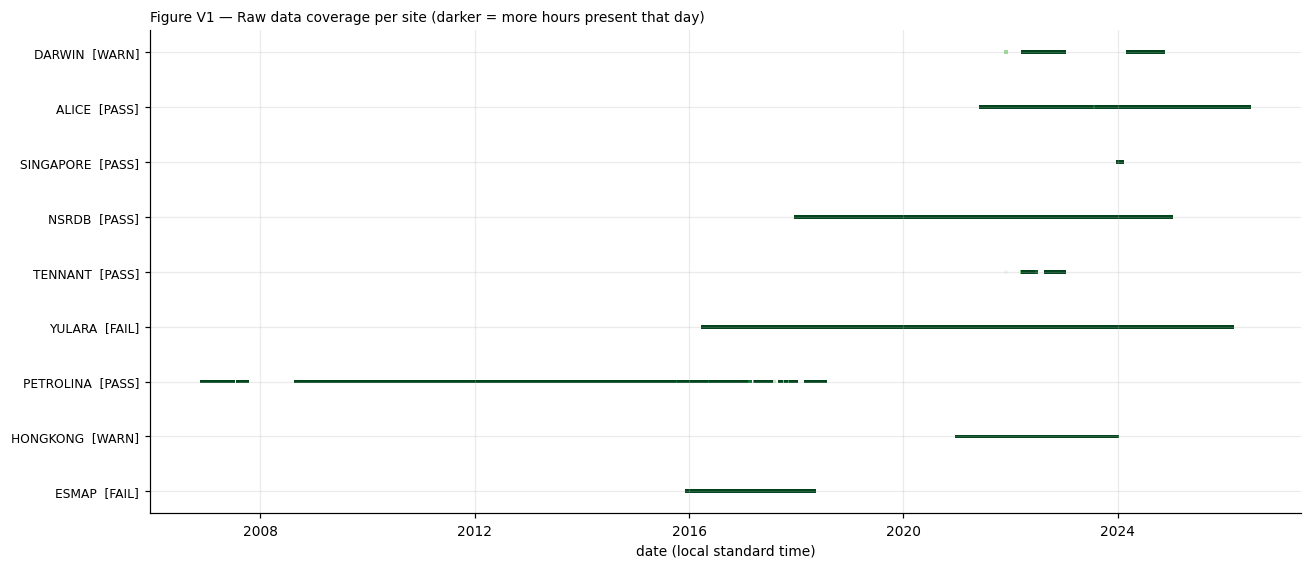

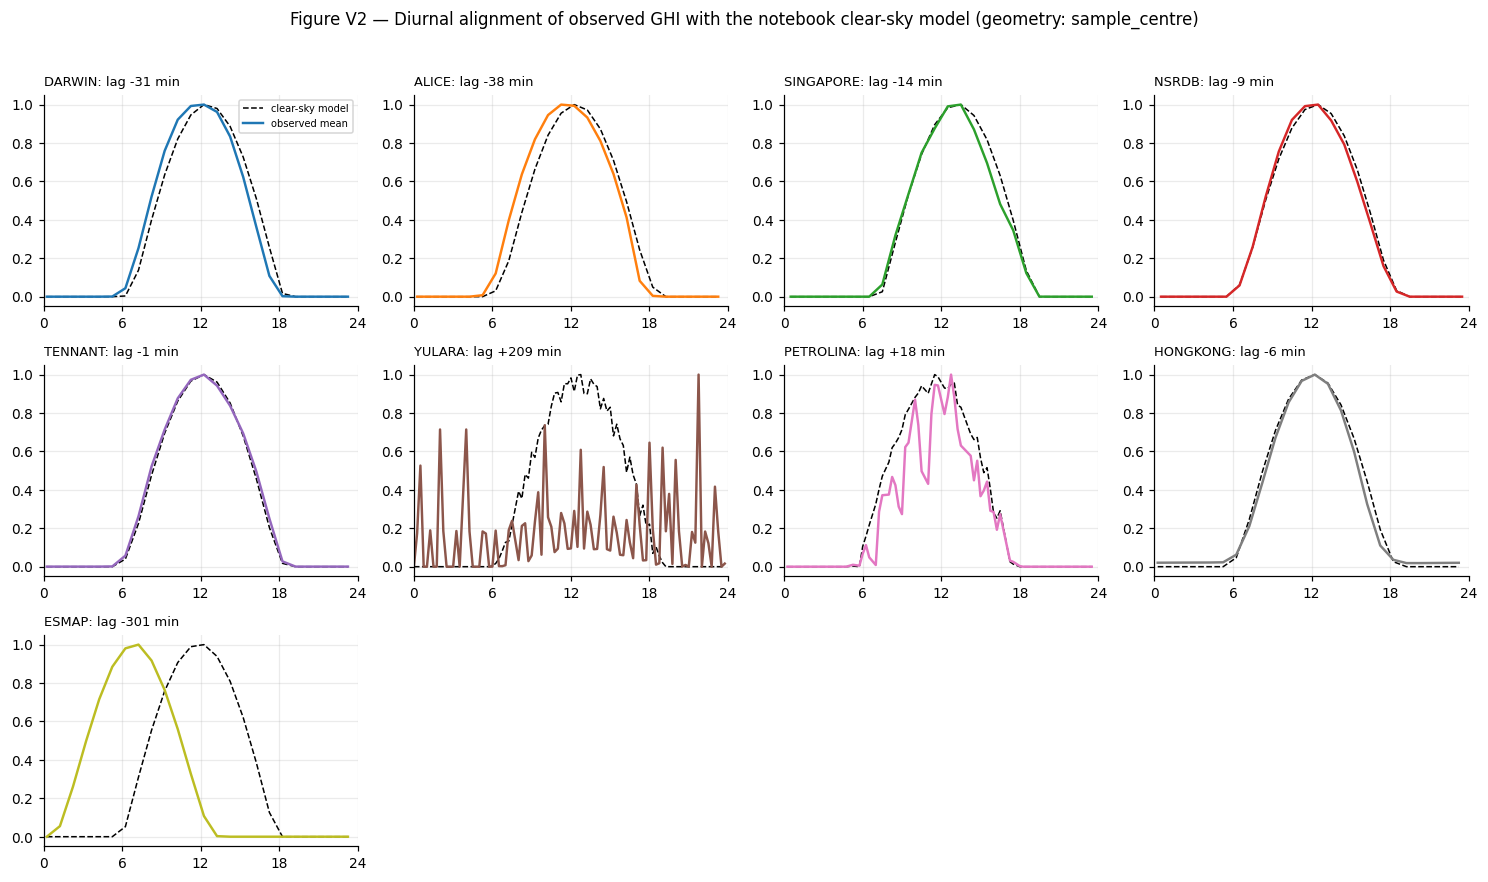

In [ ]:
VAR_RANGES = {"ghi_wm2": (CFG.NEG_TOLERANCE, CFG.GHI_MAX), "temp_c": (-30, 60),
              "rh_pct": (0, 100), "wind_ms": (0, 60), "pv_kw": (0, np.inf)}


def _circ_centroid_h(t_h, w):
    th = 2 * np.pi * np.asarray(t_h) / 24.0
    w = np.clip(np.nan_to_num(np.asarray(w, float)), 0, None)
    if w.sum() <= 0:
        return np.nan
    return (np.degrees(np.arctan2((w * np.sin(th)).sum(), (w * np.cos(th)).sum())) / 15.0) % 24


def diurnal_alignment(d, site, timing):
    """Minutes by which the observed diurnal GHI centroid lags the clear-sky centroid.

    Both profiles are built on the same rows and the same clock, so a correctly timed
    source gives |lag| of a few minutes (cloud asymmetry, e.g. afternoon convection, adds a
    little). A UTC file read as local time gives a lag of ~tz hours; NASA POWER local SOLAR
    time read as standard time gives tens of minutes. Circular statistics make the test
    valid even when a large error pushes daylight across midnight.
    """
    m = SITES[site]
    old = CFG.GEOMETRY_TIMING
    try:
        CFG.GEOMETRY_TIMING = timing
        gt = geometry_times(d, site)
    finally:
        CFG.GEOMETRY_TIMING = old
    cosz, _ = solar_geometry(gt, m["lat"], m["lon"], m["tz"])
    cs = clearsky_haurwitz(cosz)
    g = d["ghi_wm2"].clip(lower=0).to_numpy()
    ok = np.isfinite(g)
    t_h = (gt.hour + gt.minute / 60.0 + gt.second / 3600.0).to_numpy()[ok]
    grp = pd.DataFrame({"h": np.floor(t_h * 4) / 4, "g": g[ok], "cs": cs[ok]}).groupby("h")
    prof, cnt = grp.mean(), grp.size()
    prof = prof[cnt >= 0.2 * cnt.median()]          # drop sparsely populated quarter-hour bins
    c_obs = _circ_centroid_h(prof.index, prof["g"])
    c_cs = _circ_centroid_h(prof.index, prof["cs"])
    lag = ((c_obs - c_cs + 12) % 24 - 12) * 60 if np.isfinite(c_obs) and np.isfinite(c_cs) else np.nan
    night = (cs[ok] <= 0) & (g[ok] > 50)
    return float(lag), float(100 * night.sum() / max((g[ok] > 50).sum(), 1)), prof


VALID_ROWS, PROFILES = [], {}
for site in SITES_OK:
    d = RAW[RAW.site == site].sort_values("ts").reset_index(drop=True)
    ts = d["ts"]
    span_h = (ts.max() - ts.min()) / pd.Timedelta(hours=1) + 1
    step_h = ts.diff().dt.total_seconds().div(3600)
    gaps = step_h[step_h > 1]
    daymask = d["ghi_wm2"] > 20
    r = {"site": site, "source": SOURCE_USED.get(site, "?")[:48], "hourly_rows": len(d),
         "first": ts.min(), "last": ts.max(), "coverage_%": 100 * d["ghi_wm2"].notna().sum() / span_h,
         "n_gaps>1h": int(len(gaps)), "longest_gap_h": float(gaps.max()) if len(gaps) else 0.0,
         "chronological": bool(ts.is_monotonic_increasing)}
    if RAW_STREAM is not None and len(RAW_STREAM):
        used = set(LEDGER[(LEDGER.site == site) & (LEDGER.hourly_rows > 0)].file)
        rs = RAW_STREAM[RAW_STREAM.file.isin(used)]
        r.update({"native_step_min": float(rs.native_step_s.median() / 60) if len(rs) else np.nan,
                  "raw_rows": int(rs.rows_read.sum()) if len(rs) else np.nan,
                  "bad_timestamps": int(rs.bad_ts_n.sum()) if len(rs) else 0,
                  "raw_dup_timestamps": int(rs.dup_ts_within_chunk.sum()) if len(rs) else 0,
                  "raw_non_monotonic": int(rs.non_monotonic_steps.sum()) if len(rs) else 0})
    if CANON_EV is not None and len(CANON_EV):
        ce = CANON_EV[CANON_EV.site == site]
        r.update({"dup_hours_removed": int(ce.duplicate_hours_removed.sum()),
                  "inf_to_nan": int(ce.inf_to_nan.sum())})
    for v, (lo, hi) in VAR_RANGES.items():
        x = d[v]
        r[f"{v}_missing_%"] = 100 * x.isna().mean()
        r[f"{v}_out_of_range"] = int(((x < lo) | (x > hi)).sum())
    g = d["ghi_wm2"]
    r.update({"ghi_min": g.min(), "ghi_p50_day": g[daymask].median(), "ghi_p99": g.quantile(.99),
              "ghi_max": g.max(), "ghi_negative_n": int((g < 0).sum()),
              "dtypes_numeric": bool(all(pd.api.types.is_numeric_dtype(d[c]) for c in VAR_RANGES))})
    lag_v5, _, _ = diurnal_alignment(d, site, "interval_start")
    lag_v6, night_pct, prof = diurnal_alignment(d, site, CFG.GEOMETRY_TIMING)
    PROFILES[site] = (prof, lag_v6)
    r.update({"lag_min_interval_start": lag_v5, "lag_min_active": lag_v6,
              "daylight_ghi_at_night_%": night_pct})

    status, why = "PASS", []
    p999 = g.quantile(.999)
    if not np.isfinite(p999) or p999 < 5:
        status, why = "FAIL", why + [f"GHI 99.9th pct {p999:.2f}: units look like kW/m2 or no daylight"]
    elif p999 > 2000:
        status, why = "FAIL", why + [f"GHI 99.9th pct {p999:.0f} W/m2: scaling/units error"]
    if np.isfinite(lag_v6) and abs(lag_v6) > CFG.TIMING_FAIL_MIN:
        status = "FAIL"
        why.append(f"diurnal lag {lag_v6:+.0f} min: time basis wrong "
                   f"(UTC read as local would give ~{-SITES[site]['tz']*60:+.0f} min)")
    elif np.isfinite(lag_v6) and abs(lag_v6) > CFG.TIMING_WARN_MIN:
        status = "WARN" if status == "PASS" else status
        why.append(f"diurnal lag {lag_v6:+.0f} min")
    if SITES[site].get("time_basis_assumed"):
        status = "WARN" if status == "PASS" else status
        why.append("time basis assumed, not stated in file")
    if r["coverage_%"] < 50:
        status = "WARN" if status == "PASS" else status
        why.append(f"coverage {r['coverage_%']:.0f}%")
    if r.get("bad_timestamps", 0) or r.get("raw_non_monotonic", 0):
        status = "WARN" if status == "PASS" else status
        why.append("unparseable or out-of-order raw timestamps")
    r["status"], r["issues"] = status, "; ".join(why)
    VALID_ROWS.append(r)

VALIDATION = pd.DataFrame(VALID_ROWS)
save_table(VALIDATION.assign(first=VALIDATION["first"].astype(str), last=VALIDATION["last"].astype(str)),
           ckd("data_validation"))

show_cols = ["site", "hourly_rows", "first", "last", "coverage_%", "n_gaps>1h", "longest_gap_h",
             "native_step_min", "bad_timestamps", "raw_dup_timestamps", "dup_hours_removed",
             "ghi_min", "ghi_p99", "ghi_max", "ghi_negative_n", "ghi_wm2_out_of_range",
             "lag_min_interval_start", "lag_min_active", "status"]
show_cols = [c for c in show_cols if c in VALIDATION.columns]
print("DATA VALIDATION — raw hourly frames, BEFORE any cleaning (nothing is removed here)")
print("=" * 118)
print(VALIDATION[show_cols].round(2).to_string(index=False))
print("\nMissing % by variable (absent variable = 100%):")
print(VALIDATION[["site"] + [f"{v}_missing_%" for v in VAR_RANGES]].round(1).to_string(index=False))
print("\nOut-of-range counts by variable (flagged here, treated in Part 4 QC):")
print(VALIDATION[["site"] + [f"{v}_out_of_range" for v in VAR_RANGES]].to_string(index=False))
for _, r in VALIDATION.iterrows():
    if r.status != "PASS":
        print(f"  {r.status:<4} {r.site:<10} {r.issues}")
print(textwrap.fill(
    "Reading the two lag columns: 'interval_start' is where v5 evaluated the sun (HH:00) for an "
    "hourly mean centred near HH:30, so a correctly timed 1-s or 1-min source shows a lag of about "
    "-30 min there (the observed curve appears early against the model); 'active' is the "
    "convention used in this run. A lag of whole hours means the "
    "file's time basis (UTC vs local) was read wrongly and that site is excluded below.", 100))

# ---- exclusion: FAIL sites leave the pipeline; the primary site may not fail silently --------
FAILED = VALIDATION[VALIDATION.status == "FAIL"]
if CFG.PRIMARY_SITE in set(FAILED.site):
    raise RuntimeError(f"Primary site {CFG.PRIMARY_SITE} failed validation: "
                       f"{FAILED.set_index('site').loc[CFG.PRIMARY_SITE, 'issues']}")
for _, r in FAILED.iterrows():
    log(f"{r.site} EXCLUDED from all analysis: {r.issues}. If the file is UTC, set "
        f"TIME_BASIS_OVERRIDE['{r.site}'] = 'utc' in Part 3.2 and re-run.", "err")
SITES_OK = [s for s in SITES_OK if s not in set(FAILED.site)]
print(f"\nSites passing validation and continuing: {SITES_OK}")

# ---- Figure V1: coverage timeline -------------------------------------------------------------
_pal = plt.get_cmap("tab10")
fig, ax = plt.subplots(figsize=(12, 0.45 * len(VALIDATION) + 1.2))
for i, site in enumerate(VALIDATION.site):
    d = RAW[RAW.site == site]
    daily = d.set_index("ts")["ghi_wm2"].notna().resample("D").mean()
    ok = daily[daily > 0]
    ax.scatter(ok.index, np.full(len(ok), i), c=ok.values, cmap="Greens", vmin=0, vmax=1,
               s=6, marker="s", linewidths=0)
ax.set_yticks(range(len(VALIDATION)))
ax.set_yticklabels([f"{s}  [{st}]" for s, st in zip(VALIDATION.site, VALIDATION.status)], fontsize=8)
ax.invert_yaxis(); ax.set_xlabel("date (local standard time)")
ax.set_title("Figure V1 — Raw data coverage per site (darker = more hours present that day)",
             loc="left", fontsize=9)
savefig(fig, "figV1_coverage"); plt.show()

# ---- Figure V2: diurnal timing alignment --------------------------------------------------------
n = len(PROFILES)
ncol = min(n, 4); nrow = int(np.ceil(n / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(3.4 * ncol, 2.6 * nrow), squeeze=False)
for ax, (site, (prof, lag)) in zip(axes.ravel(), PROFILES.items()):
    ax.plot(prof.index, prof["cs"] / max(prof["cs"].max(), 1e-9), "k--", lw=1, label="clear-sky model")
    ax.plot(prof.index, prof["g"] / max(prof["g"].max(), 1e-9), color=_pal(list(PROFILES).index(site) % 10),
            lw=1.6, label="observed mean")
    ax.set_title(f"{site}: lag {lag:+.0f} min", fontsize=8.5, loc="left")
    ax.set_xticks([0, 6, 12, 18, 24]); ax.set_xlim(0, 24)
for ax in axes.ravel()[n:]:
    ax.set_visible(False)
axes[0, 0].legend(fontsize=6.5)
fig.suptitle("Figure V2 — Diurnal alignment of observed GHI with the notebook clear-sky model "
             f"(geometry: {CFG.GEOMETRY_TIMING})", y=1.02)
savefig(fig, "figV2_timing"); plt.show()

## PART 4 — Quality control, missing-data strategy, feature engineering

### 4.1 The missing-data problem in irradiance data, and why naive imputation is wrong

Solar irradiance has a property that breaks generic imputation: **most of its zeros are not
missing data, they are night.** A pipeline that treats the series as a generic numeric column
and calls `fillna(mean)` or `interpolate()` produces:

* daylight values injected into the middle of the night (mean-fill), and
* straight lines drawn across multi-day sensor outages (unbounded interpolation), which the
  ramp detector then reads as a real meteorological event.

The strategy used here is explicitly gap-length-aware and physics-aware:

| Situation | Treatment | Justification |
|---|---|---|
| `ghi_cs <= 20 W/m²` (night) | GHI forced to 0, **not** imputed | Structural zero, not missing |
| Sentinel `-999` | → NaN at read time | NASA POWER missing code |
| `-10 < ghi < 0` | clipped to 0 | Pyranometer night-time thermal offset |
| `ghi < -10` | → NaN | Genuine sensor fault |
| `ghi > 1.3 × ghi_cs` | → NaN | Non-physical; exceeds cloud-enhancement ceiling |
| Daylight gap ≤ 3 h | interpolate **in clear-sky-index space** | Removes the deterministic diurnal cycle first, so interpolation restores cloud state, not sun angle |
| Daylight gap > 3 h | left NaN, window discarded | Better to lose samples than to fabricate the variance the study measures |
| Met covariates (T, RH, wind) | interpolate ≤ 6 h, then site-hour climatology | Slowly varying; and they are covariates, never the target |

Interpolating `kt` rather than `ghi` is the single most important choice here. `ghi` at 09:00 and
`ghi` at 12:00 differ mostly because the sun moved; linear interpolation between them is wrong by
construction. `kt` is dimensionless and roughly stationary through the day, so the interpolated
value carries the intended meaning — "cloud conditions persisted".

In [ ]:
def qc_and_kt(df: pd.DataFrame, site: str) -> pd.DataFrame:
    d = attach_solar(df.copy(), site)

    # ---- reindex onto a complete hourly grid: this is what EXPOSES the gaps -----
    full = pd.date_range(d["ts"].min(), d["ts"].max(), freq=CFG.TARGET_FREQ)
    d = (d.set_index("ts").reindex(full).rename_axis("ts").reset_index())
    d = attach_solar(d.drop(columns=["cos_zenith", "ghi_toa", "ghi_cs", "is_daylight"]), site)
    d.insert(0, "site", site)

    g = d["ghi_wm2"]
    d["qc_raw_missing"] = g.isna()

    g = g.where(g >= CFG.NEG_TOLERANCE)              # hard negatives -> NaN
    g = g.clip(lower=0.0)                            # small offsets -> 0
    g = g.where(g <= CFG.GHI_MAX)                    # absurd values -> NaN
    over = (g > CFG.KT_MAX * d["ghi_cs"]) & (d["ghi_cs"] > CFG.DAYLIGHT_CS_MIN)
    d["qc_nonphysical"] = over.fillna(False)
    g = g.where(~d["qc_nonphysical"])
    g = g.where(d["is_daylight"], 0.0)               # night is a structural zero
    d["ghi_wm2"] = g

    # ---- clear-sky index --------------------------------------------------------
    with np.errstate(divide="ignore", invalid="ignore"):
        kt = np.where(d["is_daylight"], d["ghi_wm2"] / d["ghi_cs"].replace(0, np.nan), 0.0)
    d["kt"] = np.clip(kt, 0.0, CFG.KT_MAX)
    d.loc[d["ghi_wm2"].isna(), "kt"] = np.nan

    # ---- covariate QC -----------------------------------------------------------
    d["temp_c"] = d["temp_c"].where(d["temp_c"].between(-30, 60))
    d["rh_pct"] = d["rh_pct"].clip(0, 100)
    d["wind_ms"] = d["wind_ms"].where(d["wind_ms"].between(0, 60))
    if "pv_kw" in d:
        d["pv_kw"] = d["pv_kw"].clip(lower=0)
    return d


def _gap_lengths(mask: pd.Series) -> pd.Series:
    """For each NaN position, the length of the contiguous NaN run containing it."""
    grp = (mask != mask.shift()).cumsum()
    return mask.groupby(grp).transform("size").where(mask, 0)


def impute(d: pd.DataFrame) -> pd.DataFrame:
    d = d.copy()
    day = d["is_daylight"].to_numpy()

    # --- target: gap-aware interpolation in kt space -----------------------------
    kt = d["kt"]
    miss = kt.isna() & day
    runs = _gap_lengths(miss)
    short = miss & (runs <= CFG.MAX_INTERP_GAP_H)

    kt_i = kt.interpolate(method="linear", limit=CFG.MAX_INTERP_GAP_H,
                          limit_area="inside")
    d["kt"] = np.where(short, kt_i, kt)
    d["kt_imputed"] = short
    d["kt_unrecoverable"] = miss & ~short

    d["ghi_wm2"] = np.where(d["kt"].notna(), d["kt"] * d["ghi_cs"], np.nan)
    d.loc[~day, "ghi_wm2"] = 0.0

    # --- covariates: interpolate then fall back to site-hour climatology ---------
    for c in ("temp_c", "rh_pct", "wind_ms"):
        s = d[c]
        d[f"{c}_imputed"] = s.isna()
        s = s.interpolate(method="linear", limit=6, limit_area="inside")
        clim = s.groupby([d["ts"].dt.month, d["ts"].dt.hour]).transform("median")
        s = s.fillna(clim).fillna(s.median())
        d[c] = s
    return d

### 4.2 Derived features

Every feature below exists to serve a stated objective, not because it is conventional:

* **Cyclical calendar encodings** — sine/cosine of hour and day-of-year. Raw integers would tell
  the network that hour 23 and hour 0 are 23 units apart.
* **`is_wet` seasonal flag** — Objective 3 (seasonal conditioning) *is* this variable. It is
  defined per site from that site's own climatology, not copied from Darwin: Darwin/Alice use
  the austral wet season, Singapore the NE monsoon, NSRDB the boreal wet season.
* **`kt` lags 1–3 and 24** — short persistence plus the previous-day-same-hour anchor.
* **`kt` rolling mean/σ (3 h, 24 h)** — recent cloud level and recent volatility. The σ terms are
  what let the probabilistic heads widen intervals during unstable conditions.
* **`is_ramp`** — |Δkt| > 0.35 in one hour, the ramp-event definition used for the subgroup
  analysis in Objective 3.
* **`ghi_cs`, `cos_zenith`** — deterministic geometry, given to the model so it does not have to
  relearn the solar path.

All lags are strictly backward-looking. Nothing at time *t* is built from information after *t*.

In [ ]:
BASE_FEATURES = [
    "kt", "kt_lag1", "kt_lag2", "kt_lag3", "kt_lag24",
    "kt_roll3_mean", "kt_roll3_std", "kt_roll24_mean", "kt_roll24_std",
    "cos_zenith", "ghi_cs_norm",
    "temp_c", "rh_pct", "wind_ms",
    "hour_sin", "hour_cos", "doy_sin", "doy_cos",
]
SEASON_FEATURE = "is_wet"
ALL_FEATURES = BASE_FEATURES + [SEASON_FEATURE]


def engineer(d: pd.DataFrame, site: str) -> pd.DataFrame:
    d = d.copy()
    ts = d["ts"]

    d["hour_sin"] = np.sin(2 * np.pi * ts.dt.hour / 24)
    d["hour_cos"] = np.cos(2 * np.pi * ts.dt.hour / 24)
    d["doy_sin"] = np.sin(2 * np.pi * ts.dt.dayofyear / 365.25)
    d["doy_cos"] = np.cos(2 * np.pi * ts.dt.dayofyear / 365.25)

    d["is_wet"] = ts.dt.month.isin(SITES[site]["wet_months"]).astype(float)
    d["season"] = np.where(d["is_wet"] > 0, SITES[site]["season_names"][1],
                           SITES[site]["season_names"][0])

    for L in (1, 2, 3, 24):
        d[f"kt_lag{L}"] = d["kt"].shift(L)
    for W in (3, 24):
        r = d["kt"].rolling(W, min_periods=max(2, W // 3))
        d[f"kt_roll{W}_mean"] = r.mean().shift(1)
        d[f"kt_roll{W}_std"] = r.std().shift(1)

    d["ghi_cs_norm"] = d["ghi_cs"] / 1100.0
    d["dkt"] = d["kt"].diff()
    d["is_ramp"] = (d["dkt"].abs() > CFG.RAMP_KT_THRESHOLD) & d["is_daylight"]
    return d


def build_features() -> pd.DataFrame:
    out = []
    for site in SITES_OK:
        d = RAW[RAW.site == site].drop(columns=["site"]).reset_index(drop=True)
        d = qc_and_kt(d, site)
        d = impute(d)
        d = engineer(d, site)
        out.append(d)
        log(f"{site:<10} features built: {len(d):,} rows, "
            f"{d['is_daylight'].sum():,} daylight hours", "ok")
    return pd.concat(out, ignore_index=True)


FEAT = checkpoint(ckd("features_hourly"), build_features)
FEAT = FEAT[FEAT.site.isin(SITES_OK)].reset_index(drop=True)


# ---- imputation ledger: report exactly what was filled and what was surrendered ----
rows = []
for site in SITES_OK:
    d = FEAT[FEAT.site == site]
    day = d[d.is_daylight]
    rows.append({
        "site": site,
        "hours_total": len(d),
        "daylight_hours": len(day),
        "raw_missing_%": 100 * d.qc_raw_missing.mean(),
        "nonphysical_%": 100 * d.qc_nonphysical.mean(),
        "kt_interpolated_%": 100 * d.kt_imputed.mean(),
        "kt_unrecoverable_%": 100 * d.kt_unrecoverable.mean(),
        "temp_imputed_%": 100 * d.temp_c_imputed.mean(),
        "rh_imputed_%": 100 * d.rh_pct_imputed.mean(),
        "wind_imputed_%": 100 * d.wind_ms_imputed.mean(),
        "ramp_hours_%": 100 * d.is_ramp.sum() / max(len(day), 1),
    })
IMPUTE_LEDGER = pd.DataFrame(rows).round(2)
print("\nIMPUTATION & QC LEDGER  (all figures are % of hours unless stated)")
print(IMPUTE_LEDGER.to_string(index=False))
save_table(IMPUTE_LEDGER, "impute_ledger")

[ 8398.4s |   1212MB] ==> checkpoint build 'features_hourly_439c0db529_EXT_sample' ...
[ 8398.5s |   1213MB]  ok DARWIN     features built: 25,824 rows, 12,359 daylight hours
[ 8398.7s |   1213MB]  ok ALICE      features built: 44,127 rows, 21,197 daylight hours
[ 8398.8s |   1213MB]  ok SINGAPORE  features built: 745 rows, 360 daylight hours
[ 8399.0s |   1213MB]  ok NSRDB      features built: 61,368 rows, 29,686 daylight hours
[ 8399.1s |   1213MB]  ok TENNANT    features built: 9,697 rows, 4,762 daylight hours
[ 8399.5s |   1213MB]  ok PETROLINA  features built: 101,945 rows, 48,611 daylight hours
[ 8399.6s |   1213MB]  ok HONGKONG   features built: 26,280 rows, 12,744 daylight hours
[ 8400.2s |   1201MB]  ok checkpoint saved 'features_hourly_439c0db529_EXT_sample'  (269,986 rows)

IMPUTATION & QC LEDGER  (all figures are % of hours unless stated)
     site  hours_total  daylight_hours  raw_missing_%  nonphysical_%  kt_interpolated_%  kt_unrecoverable_%  temp_imputed_%  rh_imputed_%

PosixPath('/content/drive/MyDrive/_tropicalpv_artifacts/impute_ledger.parquet')

## PART 5 — Exploratory Data Analysis

Each figure below answers a question the proposal actually asks. Nothing here is decoration.

| Figure | Objective it serves |
|---|---|
| 1 Missingness / data availability | Data-management claim; justifies the imputation policy |
| 2 Diurnal cycle by season | Objective 3 — is there a seasonal signal to condition on? |
| 3 kt distribution by site | Objectives 1–2 — is tropical variance really higher? |
| 4 Seasonal kt split per site | Objective 3 — magnitude of the wet/dry effect |
| 5 Ramp-event frequency & magnitude | Objective 3 — ramp subgroup; motivates uncertainty |
| 6 Feature correlation | Objective 1 — predictor screening |
| 7 Cross-site GHI comparison | Objective 8 — climate gradient is real and ordered |
| 8 Clear-sky model validation | Methodological — our Haurwitz curve vs. supplied clear-sky |
| 9 Irradiance ↔ measured PV (Alice) | Objective 1 secondary — the proxy assumption itself |
| 10 Autocorrelation of kt | Justifies LOOKBACK = 24 h |

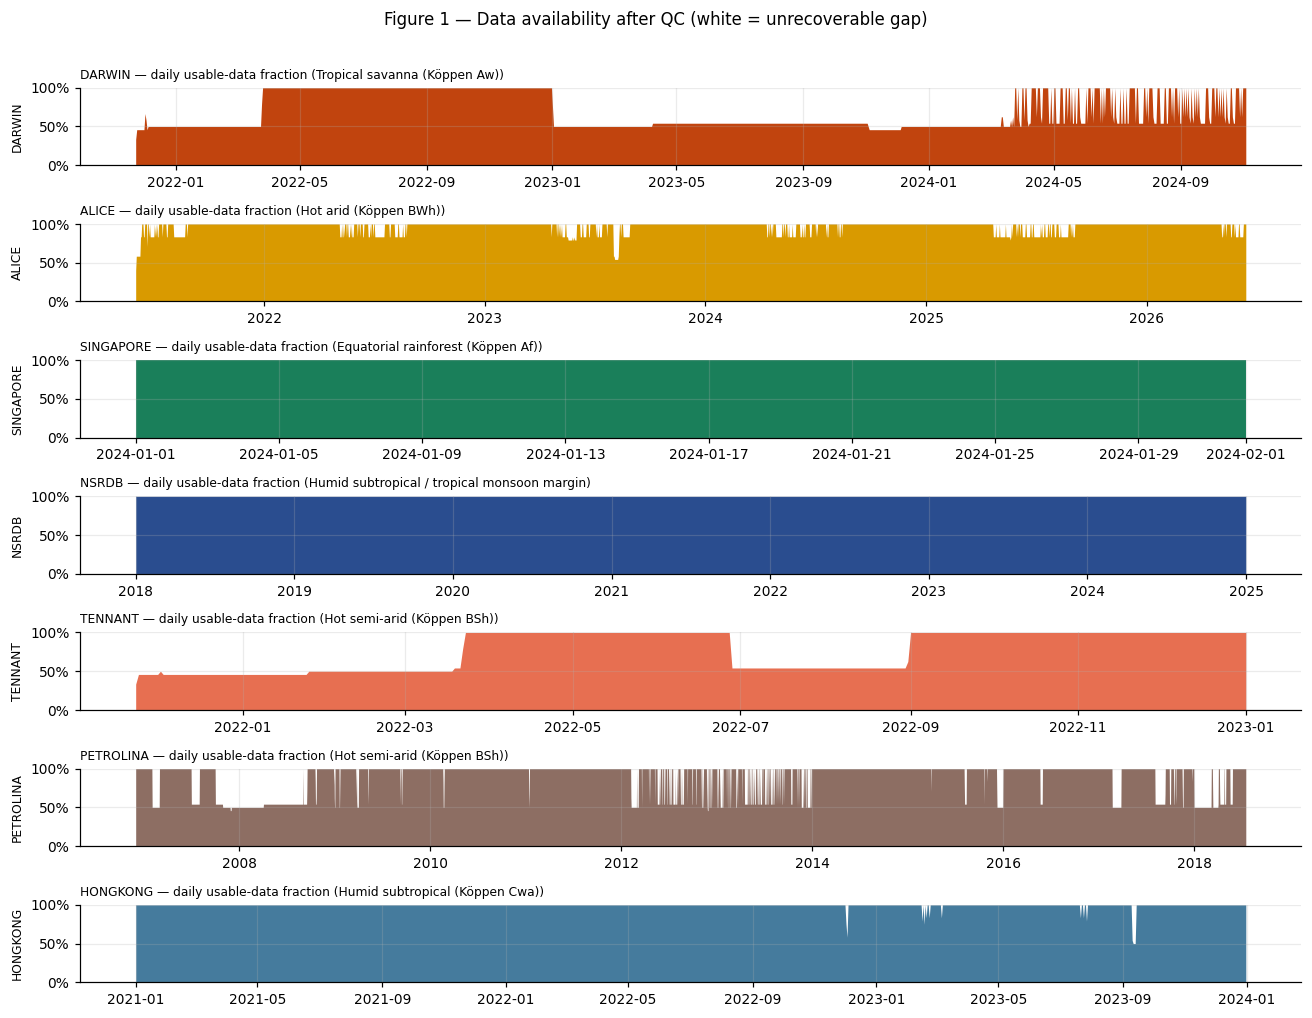

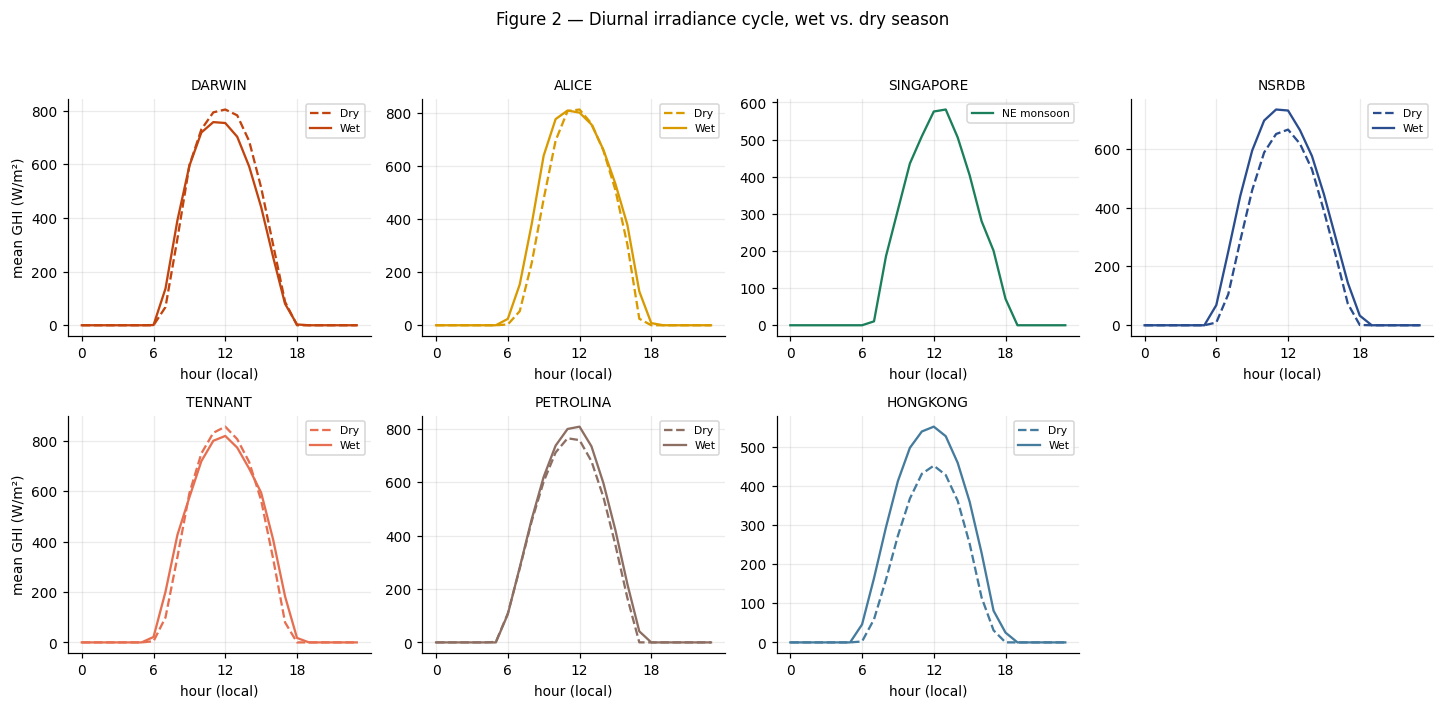

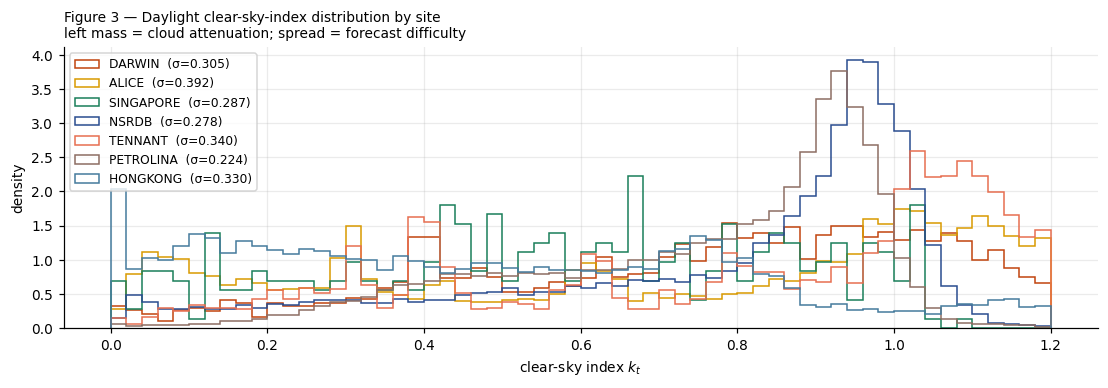

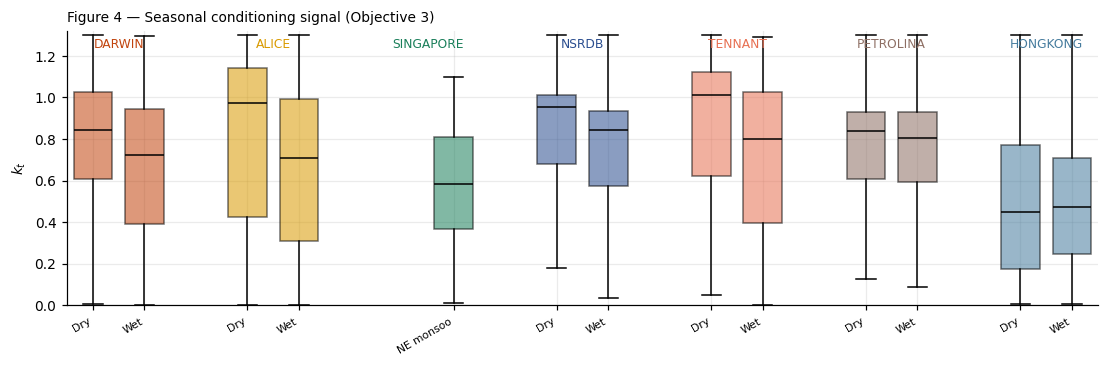

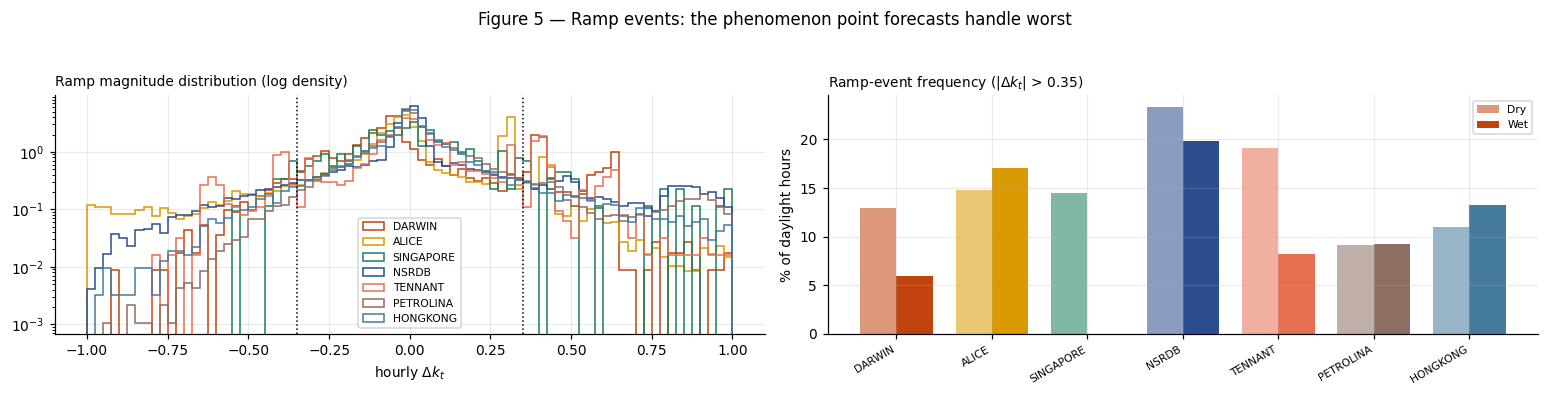

     site     season  ramp_rate
   DARWIN        Dry      12.93
   DARWIN        Wet       5.95
    ALICE        Dry      14.75
    ALICE        Wet      17.08
SINGAPORE NE monsoon      14.44
    NSRDB        Dry      23.39
    NSRDB        Wet      19.86
  TENNANT        Dry      19.10
  TENNANT        Wet       8.19
PETROLINA        Dry       9.14
PETROLINA        Wet       9.19
 HONGKONG        Dry      10.95
 HONGKONG        Wet      13.25


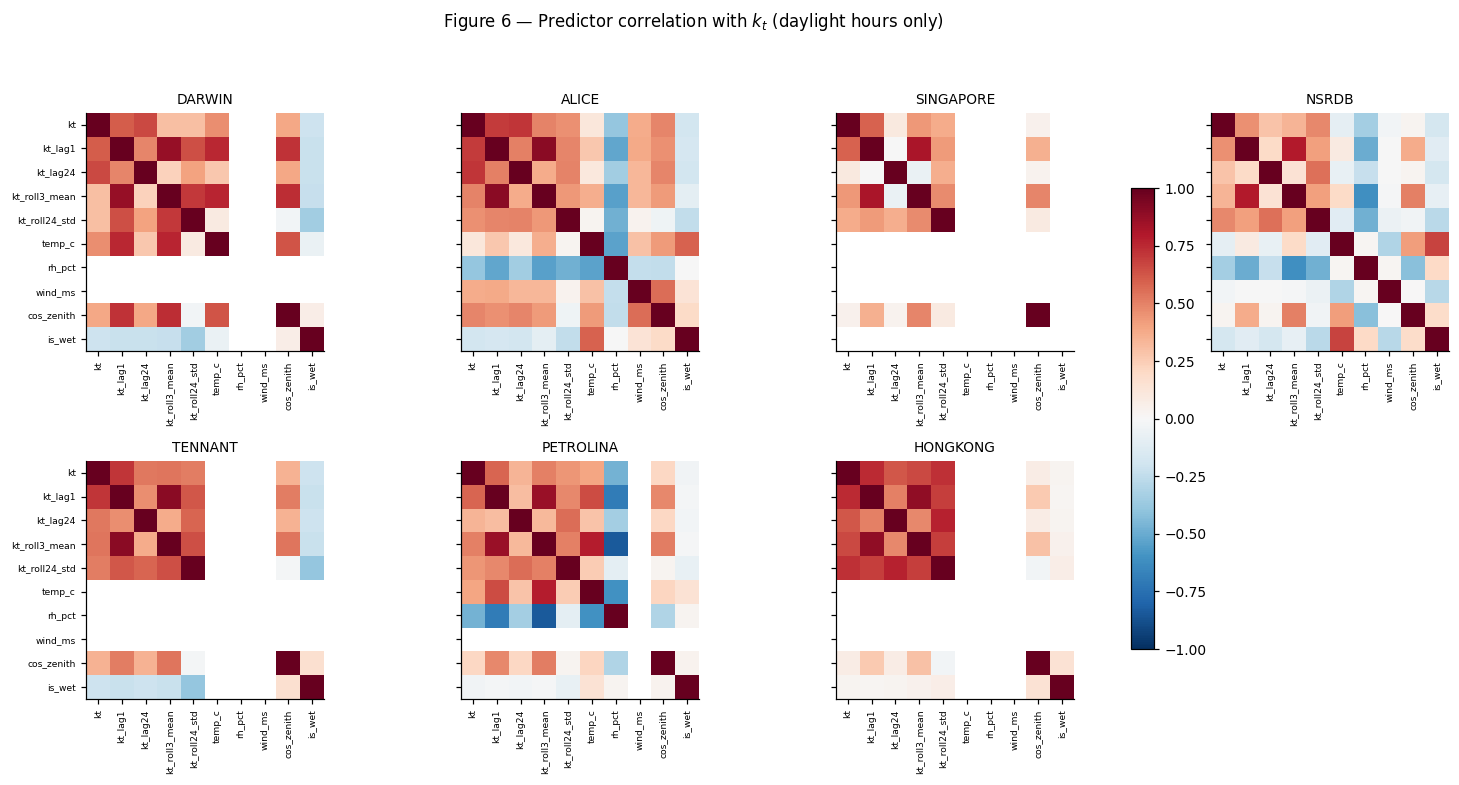

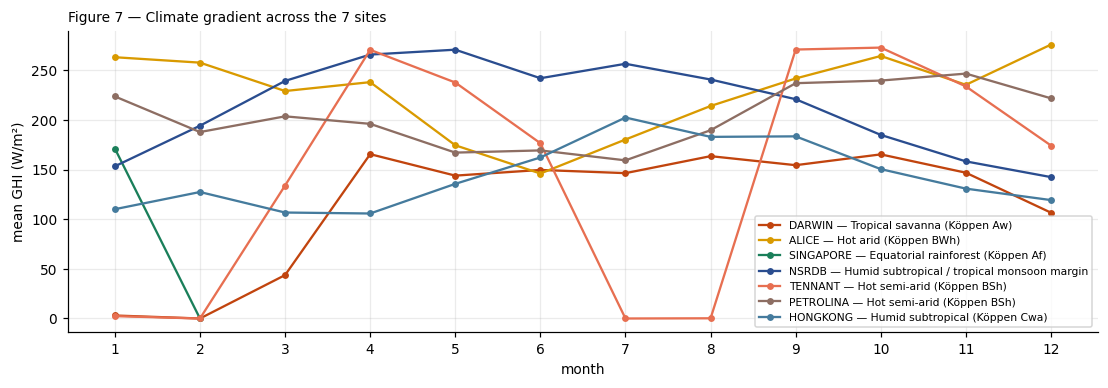

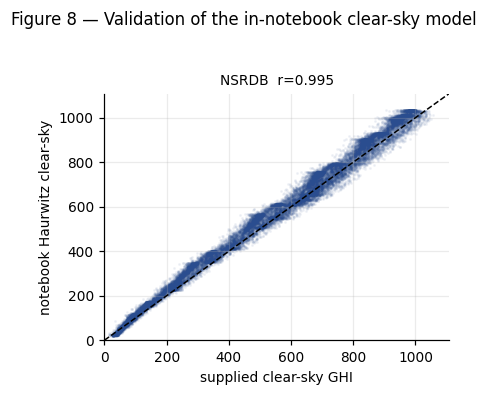

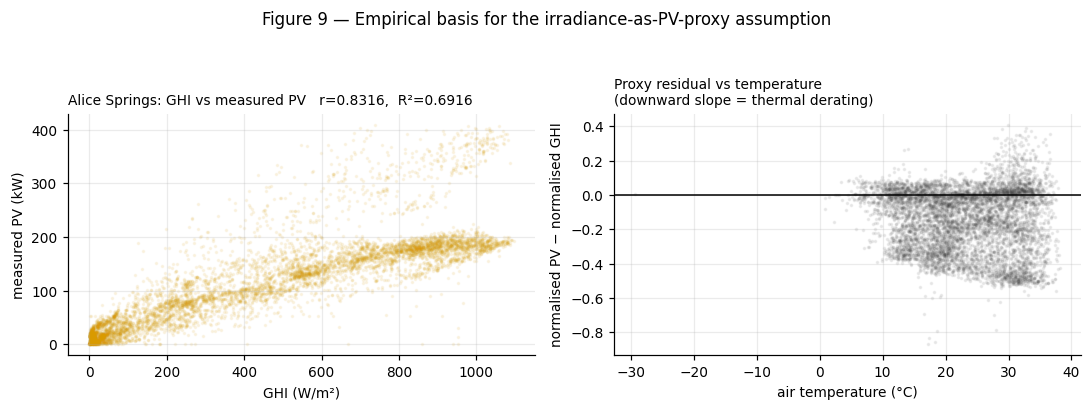

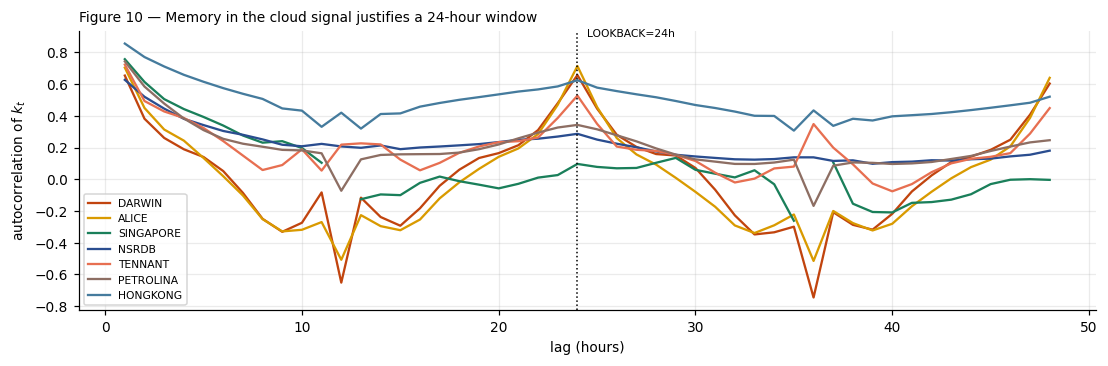

In [ ]:
SITE_COLOR = {"DARWIN": "#c1440e", "ALICE": "#d99a00",
              "SINGAPORE": "#1a7f5a", "NSRDB": "#2a4d8f"}
# v6: colours for the EXTENDED sites (v5 raised KeyError for any site outside the four)
_extra = ["#7b2cbf", "#e76f51", "#2a9d8f", "#8d6e63", "#457b9d", "#6d597a", "#588157", "#bc4749"]
for _i, _s in enumerate([s for s in SITES if s not in SITE_COLOR]):
    SITE_COLOR[_s] = _extra[_i % len(_extra)]


def site_grid(n, w=3.4, h=3.1, ncol_max=4):
    """Subplot grid that wraps after ncol_max panels (v5 used one row: 10 sites = 34 in wide)."""
    ncol = max(1, min(n, ncol_max))
    nrow = int(np.ceil(n / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(w * ncol, h * nrow), squeeze=False)
    for ax in axes.ravel()[n:]:
        ax.set_visible(False)
    return fig, axes


WIDE = max(7.5, 0.95 * len(SITES_OK) + 3.5)     # width for single-panel cross-site figures


def _daylight(site):
    return FEAT[(FEAT.site == site) & FEAT.is_daylight]


# ---------------- Figure 1: data availability ---------------------------------
fig, axes = plt.subplots(len(SITES_OK), 1, figsize=(12, (1.9 if len(SITES_OK) <= 4 else 1.3) * len(SITES_OK)),
                         squeeze=False)
for ax, site in zip(axes[:, 0], SITES_OK):
    d = FEAT[FEAT.site == site]
    daily = (d.assign(day=d.ts.dt.floor("D"))
              .groupby("day")
              .agg(avail=("kt_unrecoverable", lambda s: 1 - s.mean())))
    ax.fill_between(daily.index, 0, daily.avail, color=SITE_COLOR[site], lw=0)
    ax.set_ylim(0, 1); ax.set_ylabel(site, fontsize=8)
    ax.yaxis.set_major_formatter(PercentFormatter(1.0))
    ax.set_title(f"{site} — daily usable-data fraction "
                 f"({SITES[site]['climate']})", fontsize=8, loc="left")
fig.suptitle("Figure 1 — Data availability after QC (white = unrecoverable gap)", y=1.01)
savefig(fig, "fig01_availability"); plt.show()

# ---------------- Figure 2: diurnal cycle by season ----------------------------
fig, axes = site_grid(len(SITES_OK), 3.3, 3.1)
for ax, site in zip(axes.ravel(), SITES_OK):
    d = FEAT[FEAT.site == site]
    for wet, style in ((0.0, "--"), (1.0, "-")):
        sub = d[d.is_wet == wet]
        if not len(sub):
            continue
        prof = sub.groupby(sub.ts.dt.hour)["ghi_wm2"].mean()
        ax.plot(prof.index, prof.values, style, color=SITE_COLOR[site],
                label=SITES[site]["season_names"][int(wet)])
    ax.set_title(site, fontsize=9); ax.set_xlabel("hour (local)")
    ax.set_xticks([0, 6, 12, 18]); ax.legend(fontsize=7)
for row in axes:
    row[0].set_ylabel("mean GHI (W/m²)")
fig.suptitle("Figure 2 — Diurnal irradiance cycle, wet vs. dry season", y=1.03)
savefig(fig, "fig02_diurnal"); plt.show()

# ---------------- Figure 3: kt distribution ------------------------------------
fig, ax = plt.subplots(figsize=(WIDE, 3.6))
for site in SITES_OK:
    ax.hist(_daylight(site)["kt"].dropna(), bins=60, range=(0, 1.2), density=True,
            histtype="step", lw=1.8, color=SITE_COLOR[site],
            label=f"{site}  (σ={_daylight(site)['kt'].std():.3f})")
ax.set_xlabel("clear-sky index $k_t$"); ax.set_ylabel("density"); ax.legend(fontsize=8)
ax.set_title("Figure 3 — Daylight clear-sky-index distribution by site\n"
             "left mass = cloud attenuation; spread = forecast difficulty", loc="left", fontsize=9)
savefig(fig, "fig03_kt_dist"); plt.show()

# ---------------- Figure 4: seasonal split -------------------------------------
fig, ax = plt.subplots(figsize=(WIDE, 3.4))
pos, ticks = [], []
for i, site in enumerate(SITES_OK):
    d = _daylight(site)
    cand = [(0, d[d.is_wet == 0]["kt"].dropna()), (1, d[d.is_wet == 1]["kt"].dropna())]
    cand = [(k, x) for k, x in cand if len(x) > 10]
    if not cand:
        continue
    data = [x for _, x in cand]
    ppos = [i * 3 + k for k, _ in cand]
    bp = ax.boxplot(data, positions=ppos, widths=.75,
                    patch_artist=True, showfliers=False)
    for b in bp["boxes"]:
        b.set_facecolor(SITE_COLOR[site]); b.set_alpha(.55)
    for m in bp["medians"]:
        m.set_color("k")
    pos += ppos
    ticks += [SITES[site]["season_names"][k][:9] for k, _ in cand]
ax.set_xticks(pos); ax.set_xticklabels(ticks, rotation=30, ha="right", fontsize=7)
for i, site in enumerate(SITES_OK):
    ax.text(i * 3 + .5, 1.24, site, ha="center", fontsize=8, color=SITE_COLOR[site])
ax.set_ylabel("$k_t$"); ax.set_ylim(0, 1.32)
ax.set_title("Figure 4 — Seasonal conditioning signal (Objective 3)", loc="left", fontsize=9)
savefig(fig, "fig04_seasonal"); plt.show()

# ---------------- Figure 5: ramp events ----------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(max(11, WIDE + 4), 3.4))
rr = []
for site in SITES_OK:
    d = _daylight(site)
    axes[0].hist(d["dkt"].dropna(), bins=80, range=(-1, 1), density=True,
                 histtype="step", lw=1.6, color=SITE_COLOR[site], label=site)
    for wet in (0.0, 1.0):
        sub = d[d.is_wet == wet]
        if len(sub):
            rr.append({"site": site, "season": SITES[site]["season_names"][int(wet)],
                       "ramp_rate": 100 * sub["is_ramp"].mean()})
axes[0].axvline(-CFG.RAMP_KT_THRESHOLD, color="k", ls=":", lw=1)
axes[0].axvline(CFG.RAMP_KT_THRESHOLD, color="k", ls=":", lw=1)
axes[0].set_yscale("log"); axes[0].set_xlabel("hourly Δ$k_t$"); axes[0].legend(fontsize=7)
axes[0].set_title("Ramp magnitude distribution (log density)", fontsize=9, loc="left")

RAMP = pd.DataFrame(rr)
w = 0.38
for j, site in enumerate(SITES_OK):
    sub = RAMP[RAMP.site == site]
    for k, (_, r) in enumerate(sub.iterrows()):
        axes[1].bar(j + (k - .5) * w, r.ramp_rate, w, color=SITE_COLOR[site],
                    alpha=.55 if k == 0 else 1.0,
                    label=r.season if j == 0 else None)
axes[1].set_xticks(range(len(SITES_OK))); axes[1].set_xticklabels(SITES_OK, fontsize=7, rotation=30, ha="right")
axes[1].set_ylabel("% of daylight hours"); axes[1].legend(fontsize=7)
axes[1].set_title(f"Ramp-event frequency (|Δ$k_t$| > {CFG.RAMP_KT_THRESHOLD})",
                  fontsize=9, loc="left")
fig.suptitle("Figure 5 — Ramp events: the phenomenon point forecasts handle worst", y=1.04)
savefig(fig, "fig05_ramps"); plt.show()
print(RAMP.round(2).to_string(index=False))

# ---------------- Figure 6: correlation ----------------------------------------
corr_cols = ["kt", "kt_lag1", "kt_lag24", "kt_roll3_mean", "kt_roll24_std",
             "temp_c", "rh_pct", "wind_ms", "cos_zenith", "is_wet"]
fig, axes = site_grid(len(SITES_OK), 3.5, 3.4)
for ax, site in zip(axes.ravel(), SITES_OK):
    c = _daylight(site)[corr_cols].corr()
    im = ax.imshow(c, vmin=-1, vmax=1, cmap="RdBu_r")
    ax.set_xticks(range(len(corr_cols)))
    ax.set_xticklabels(corr_cols, rotation=90, fontsize=6)
    ax.set_yticks(range(len(corr_cols)))
    ax.set_yticklabels(corr_cols if ax in axes[:, 0] else [], fontsize=6)
    ax.set_title(site, fontsize=9); ax.grid(False)
fig.colorbar(im, ax=axes.ravel().tolist(), shrink=.8)
fig.suptitle("Figure 6 — Predictor correlation with $k_t$ (daylight hours only)", y=1.04)
savefig(fig, "fig06_corr"); plt.show()

# ---------------- Figure 7: cross-site monthly GHI ------------------------------
fig, ax = plt.subplots(figsize=(WIDE, 3.6))
for site in SITES_OK:
    d = FEAT[FEAT.site == site]
    m = d.groupby(d.ts.dt.month)["ghi_wm2"].mean()
    ax.plot(m.index, m.values, "-o", ms=3.5, color=SITE_COLOR[site],
            label=f"{site} — {SITES[site]['climate']}")
ax.set_xticks(range(1, 13)); ax.set_xlabel("month"); ax.set_ylabel("mean GHI (W/m²)")
ax.legend(fontsize=7)
ax.set_title(f"Figure 7 — Climate gradient across the {len(SITES_OK)} sites", loc="left", fontsize=9)
savefig(fig, "fig07_crosssite"); plt.show()

# ---------------- Figure 8: clear-sky validation --------------------------------
val_sites = [s for s in SITES_OK if FEAT[(FEAT.site == s)]["ghi_cs_src"].notna().any()]
if val_sites:
    fig, axes = site_grid(len(val_sites), 4, 3.4)
    for ax, site in zip(axes.ravel(), val_sites):
        d = _daylight(site).dropna(subset=["ghi_cs_src"])
        ax.scatter(d["ghi_cs_src"], d["ghi_cs"], s=1, alpha=.05, color=SITE_COLOR[site])
        lim = [0, max(d["ghi_cs_src"].max(), d["ghi_cs"].max()) * 1.05]
        ax.plot(lim, lim, "k--", lw=1)
        r = np.corrcoef(d["ghi_cs_src"], d["ghi_cs"])[0, 1]
        ax.set_title(f"{site}  r={r:.3f}", fontsize=9)
        ax.set_xlabel("supplied clear-sky GHI"); ax.set_xlim(lim); ax.set_ylim(lim)
    for row in axes:
        row[0].set_ylabel("notebook Haurwitz clear-sky")
    fig.suptitle("Figure 8 — Validation of the in-notebook clear-sky model", y=1.04)
    savefig(fig, "fig08_clearsky"); plt.show()

# ---------------- Figure 9: irradiance vs measured PV (the proxy assumption) -----
if "ALICE" in SITES_OK and FEAT[FEAT.site == "ALICE"]["pv_kw"].notna().any():
    d = _daylight("ALICE").dropna(subset=["pv_kw", "ghi_wm2"])
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
    axes[0].scatter(d["ghi_wm2"], d["pv_kw"], s=2, alpha=.08, color=SITE_COLOR["ALICE"])
    r = np.corrcoef(d["ghi_wm2"], d["pv_kw"])[0, 1]
    axes[0].set_xlabel("GHI (W/m²)"); axes[0].set_ylabel("measured PV (kW)")
    axes[0].set_title(f"Alice Springs: GHI vs measured PV   r={r:.4f},  R²={r**2:.4f}",
                      fontsize=9, loc="left")
    resid = (d["pv_kw"] / d["pv_kw"].max()) - (d["ghi_wm2"] / d["ghi_wm2"].max())
    axes[1].scatter(d["temp_c"], resid, s=2, alpha=.08, color="#444")
    axes[1].axhline(0, color="k", lw=1)
    axes[1].set_xlabel("air temperature (°C)")
    axes[1].set_ylabel("normalised PV − normalised GHI")
    axes[1].set_title("Proxy residual vs temperature\n(downward slope = thermal derating)",
                      fontsize=9, loc="left")
    fig.suptitle("Figure 9 — Empirical basis for the irradiance-as-PV-proxy assumption", y=1.05)
    savefig(fig, "fig09_proxy"); plt.show()
    PROXY_R2 = r ** 2
else:
    PROXY_R2 = np.nan

# ---------------- Figure 10: kt autocorrelation --------------------------------
fig, ax = plt.subplots(figsize=(WIDE, 3.4))
for site in SITES_OK:
    s = FEAT[FEAT.site == site].set_index("ts")["kt"]
    s = s.where(FEAT[FEAT.site == site].set_index("ts")["is_daylight"])
    ac = [s.autocorr(lag) for lag in range(1, 49)]
    ax.plot(range(1, 49), ac, color=SITE_COLOR[site], label=site)
ax.axvline(CFG.LOOKBACK, color="k", ls=":", lw=1)
ax.text(CFG.LOOKBACK + .5, .9, f"LOOKBACK={CFG.LOOKBACK}h", fontsize=7)
ax.set_xlabel("lag (hours)"); ax.set_ylabel("autocorrelation of $k_t$"); ax.legend(fontsize=7)
ax.set_title("Figure 10 — Memory in the cloud signal justifies a 24-hour window",
             loc="left", fontsize=9)
savefig(fig, "fig10_acf"); plt.show()

---
# PART 5A — Energy-system insights: sky-condition regimes, variability, and a corrected ramp definition

**What we are analysing.** Before any model is fitted, the *physical* forecasting problem is
characterised: how often is each site clear, broken-cloud, or overcast; how variable is a typical
day; and how frequently does irradiance ramp. These are the quantities a system operator actually
reserves against.

**Why it matters.** RMSE averaged over all daylight hours hides the structure that determines
operational risk. A site can have a respectable mean error and still be unmanageable, because
almost all of the error is concentrated in broken-cloud hours. Separating the regimes first means
every later model comparison can be read *per regime* rather than only in aggregate.

**A correction made here.** Part 5 defined a ramp as |Δk_t| > 0.35 in any daylight hour. That
definition is unsafe at low sun angles: k_t = GHI / GHI_cs, and near sunrise/sunset GHI_cs is
small, so ordinary sensor noise divided by a near-zero denominator produces a large spurious Δk_t.
The executed run shows the fingerprint of exactly this artefact — Darwin's ramp rate was *higher*
in the dry season (10.56%) than the wet season (6.07%), which is backwards for convective,
storm-driven ramps.

This section therefore recomputes ramps with a solar-elevation floor of 15°, and additionally
reports a physical-units definition (|ΔGHI| > 100 W/m²/h) that has no denominator at all. Both are
retained so the sensitivity of every downstream ramp conclusion to the definition is visible
rather than assumed.

SKY-CONDITION REGIMES, VARIABILITY AND RAMP FREQUENCY
     site  daylight_h  Overcast_%  Broken cloud_%  Clear_%  ramp_kt_%  ramp_ghi_%  ramp_raw_%  median_VI  highly_variable_days_%
   DARWIN       12359        3.97           11.81    21.29       6.50       22.91        9.38       1.15                     0.0
    ALICE       21197       23.10           18.49    51.66       8.06       46.52       15.79       1.16                     0.0
SINGAPORE         360       24.17           44.44    31.39      10.00       48.06       14.44       0.86                     0.0
    NSRDB       29686       11.84           22.15    66.01      12.13       58.30       21.49       1.09                     0.0
  TENNANT        4762        7.14           12.07    34.54       7.77       26.92       13.65       1.13                     0.0
PETROLINA       48611        4.99           26.00    47.08       3.63       45.16        9.16       0.98                     0.0
 HONGKONG       12744       39.56          

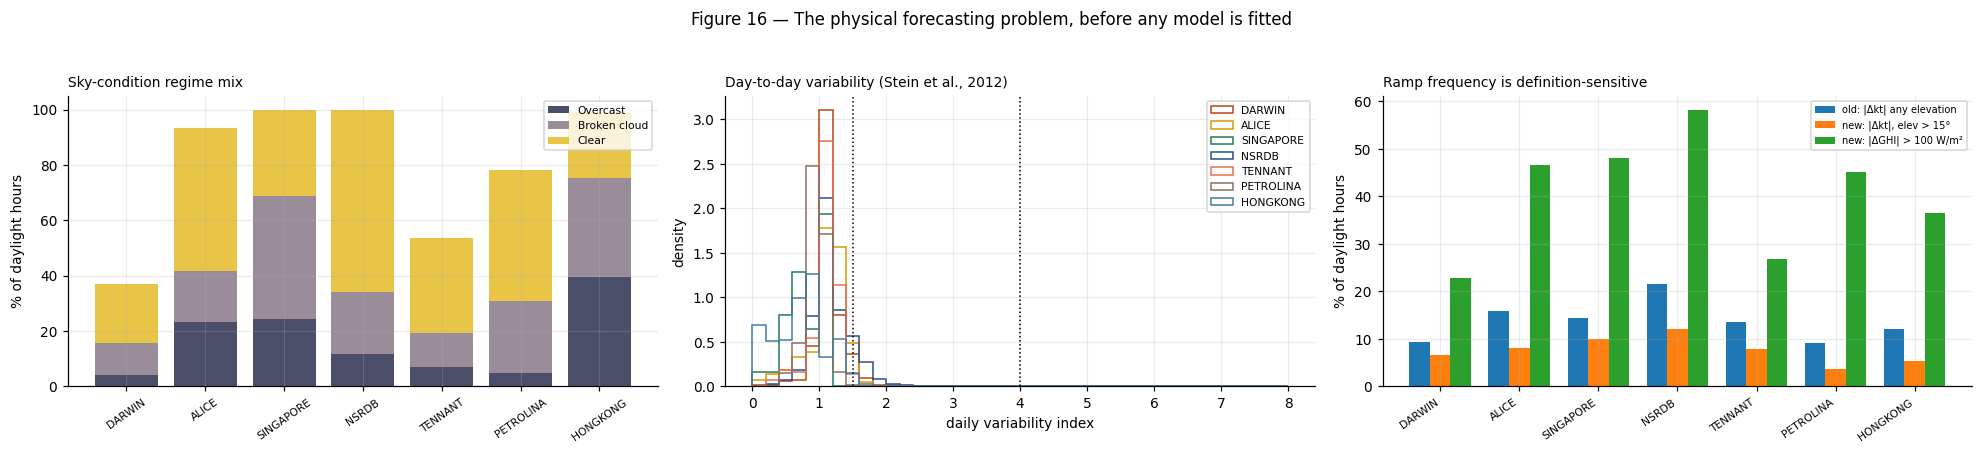


INTERPRETATION
The elevation floor removes ramp events that were geometric rather than meteorological. Where the
wet/dry ordering of ramp frequency reverses between the old and new columns above, the original
ordering was an artefact of dividing by a near-zero clear-sky denominator at dawn and dusk, not a
physical property of the season. All ramp-conditioned results from this point use the elevation-
floored definition, and the |dGHI| column provides an independent check that carries no denominator
at all.


In [ ]:
SKY_BINS = [(0.00, 0.35, "Overcast"), (0.35, 0.75, "Broken cloud"), (0.75, 9.99, "Clear")]
SKY_ORDER = ["Overcast", "Broken cloud", "Clear"]
SKY_COLOR = {"Overcast": "#4a4e69", "Broken cloud": "#9a8c98", "Clear": "#e8c547"}

ELEV_FLOOR_DEG = 15.0          # solar elevation floor for ramp detection
RAMP_GHI_WM2 = 100.0           # physical-units ramp threshold (W/m^2 per hour)


def classify_sky(kt):
    out = pd.Series(pd.NA, index=kt.index, dtype="object")
    for lo, hi, name in SKY_BINS:
        out[(kt >= lo) & (kt < hi)] = name
    return out


def add_energy_features(F: pd.DataFrame) -> pd.DataFrame:
    """Solar elevation, sky regime, and two independent ramp definitions."""
    F = F.copy()
    # elevation from the zenith cosine already stored in Part 2
    F["solar_elev_deg"] = np.degrees(np.arcsin(np.clip(F["cos_zenith"], -1, 1)))
    F["sky_regime"] = np.where(F["is_daylight"], classify_sky(F["kt"]), pd.NA)

    F["dghi"] = F.groupby("site")["ghi_wm2"].diff()

    ok_elev = F["solar_elev_deg"] > ELEV_FLOOR_DEG
    F["is_ramp_raw"] = F["is_ramp"]                       # keep Part 5 definition for comparison
    F["is_ramp_kt"] = (F["dkt"].abs() > CFG.RAMP_KT_THRESHOLD) & F["is_daylight"] & ok_elev
    F["is_ramp_ghi"] = (F["dghi"].abs() > RAMP_GHI_WM2) & F["is_daylight"] & ok_elev
    F["is_ramp"] = F["is_ramp_kt"]                        # corrected definition used downstream
    F["ramp_dir"] = np.where(F["is_ramp_kt"] & (F["dkt"] < 0), "Down",
                             np.where(F["is_ramp_kt"], "Up", "None"))
    return F


FEAT = add_energy_features(FEAT)

# ---- variability index (Stein, Hansen & Reno 2012): path length of GHI vs clear-sky ----
def variability_index(g: pd.Series, gcs: pd.Series, dt_h: float = 1.0) -> float:
    num = np.sqrt(np.diff(g.to_numpy()) ** 2 + dt_h ** 2).sum()
    den = np.sqrt(np.diff(gcs.to_numpy()) ** 2 + dt_h ** 2).sum()
    return float(num / den) if den > 0 else np.nan


rows = []
for site in SITES_OK:
    d = FEAT[(FEAT.site == site) & FEAT.is_daylight]
    for day, g in d.groupby(d.ts.dt.floor("D")):
        if len(g) < 6 or g["ghi_wm2"].isna().any():
            continue
        rows.append({"site": site, "day": day,
                     "VI": variability_index(g["ghi_wm2"], g["ghi_cs"]),
                     "mean_kt": g["kt"].mean(),
                     "is_wet": g["is_wet"].max(),
                     "ramp_hours": int(g["is_ramp_kt"].sum())})
DAILY_VI = pd.DataFrame(rows, columns=["site", "day", "VI", "mean_kt", "is_wet", "ramp_hours"])
DAILY_VI["day_type"] = pd.cut(DAILY_VI["VI"], [0, 1.5, 4.0, np.inf],
                              labels=["Stable", "Moderate", "Highly variable"])
save_table(DAILY_VI.assign(day=DAILY_VI.day.astype(str)), "daily_variability_index")

# ---- regime and ramp summary -------------------------------------------------
reg = []
for site in SITES_OK:
    d = FEAT[(FEAT.site == site) & FEAT.is_daylight]
    n = len(d)
    r = {"site": site, "daylight_h": n}
    for s in SKY_ORDER:
        r[f"{s}_%"] = 100 * (d.sky_regime == s).mean()
    r["ramp_kt_%"] = 100 * d.is_ramp_kt.mean()
    r["ramp_ghi_%"] = 100 * d.is_ramp_ghi.mean()
    r["ramp_raw_%"] = 100 * d.is_ramp_raw.mean()
    v = DAILY_VI[DAILY_VI.site == site]
    r["median_VI"] = v.VI.median()
    r["highly_variable_days_%"] = 100 * (v.day_type == "Highly variable").mean()
    reg.append(r)
REGIME = pd.DataFrame(reg).round(2)
print("SKY-CONDITION REGIMES, VARIABILITY AND RAMP FREQUENCY")
print("=" * 118)
print(REGIME.to_string(index=False))
save_table(REGIME, "energy_regime_summary")

# ---- did the elevation floor actually change the seasonal ramp story? --------
season_ramp = []
for site in SITES_OK:
    d = FEAT[(FEAT.site == site) & FEAT.is_daylight]
    for wet in (0.0, 1.0):
        s = d[d.is_wet == wet]
        if len(s) < 50:
            continue
        season_ramp.append({
            "site": site, "season": SITES[site]["season_names"][int(wet)],
            "old_|dkt|_%": 100 * s.is_ramp_raw.mean(),
            "new_|dkt|_elev>15_%": 100 * s.is_ramp_kt.mean(),
            "new_|dGHI|>100_%": 100 * s.is_ramp_ghi.mean()})
SEASON_RAMP = pd.DataFrame(season_ramp).round(2)
print("\nEFFECT OF THE ELEVATION FLOOR ON SEASONAL RAMP FREQUENCY")
print(SEASON_RAMP.to_string(index=False))
save_table(SEASON_RAMP, "ramp_definition_sensitivity")

# ---- Figure 16: the energy-system picture -----------------------------------
fig, axes = plt.subplots(1, 3, figsize=(max(13.5, 1.3 * len(SITES_OK) + 9), 3.9))
bottom = np.zeros(len(SITES_OK))
for s in SKY_ORDER:
    vals = REGIME.set_index("site").loc[SITES_OK, f"{s}_%"].to_numpy()
    axes[0].bar(SITES_OK, vals, bottom=bottom, color=SKY_COLOR[s], label=s)
    bottom += vals
axes[0].set_ylabel("% of daylight hours"); axes[0].legend(fontsize=7)
axes[0].tick_params(axis="x", labelsize=7, rotation=35)
axes[0].set_title("Sky-condition regime mix", fontsize=9, loc="left")

for site in SITES_OK:
    v = DAILY_VI[DAILY_VI.site == site]["VI"].dropna()
    if len(v):
        axes[1].hist(v, bins=40, range=(0, 8), density=True, histtype="step",
                     lw=1.7, color=SITE_COLOR[site], label=site)
axes[1].axvline(1.5, color="k", ls=":", lw=1); axes[1].axvline(4.0, color="k", ls=":", lw=1)
axes[1].set_xlabel("daily variability index"); axes[1].set_ylabel("density")
axes[1].legend(fontsize=7)
axes[1].set_title("Day-to-day variability (Stein et al., 2012)", fontsize=9, loc="left")

w = 0.26
xs = np.arange(len(SITES_OK))
for i, (col, lab) in enumerate([("ramp_raw_%", "old: |Δkt| any elevation"),
                                ("ramp_kt_%", "new: |Δkt|, elev > 15°"),
                                ("ramp_ghi_%", "new: |ΔGHI| > 100 W/m²")]):
    axes[2].bar(xs + (i - 1) * w, REGIME.set_index("site").loc[SITES_OK, col], w, label=lab)
axes[2].set_xticks(xs); axes[2].set_xticklabels(SITES_OK, fontsize=7, rotation=35, ha="right")
axes[2].set_ylabel("% of daylight hours"); axes[2].legend(fontsize=6.5)
axes[2].set_title("Ramp frequency is definition-sensitive", fontsize=9, loc="left")
fig.suptitle("Figure 16 — The physical forecasting problem, before any model is fitted", y=1.04)
savefig(fig, "fig16_energy_regimes"); plt.show()

print("\nINTERPRETATION")
print(textwrap.fill(
    "The elevation floor removes ramp events that were geometric rather than meteorological. Where "
    "the wet/dry ordering of ramp frequency reverses between the old and new columns above, the "
    "original ordering was an artefact of dividing by a near-zero clear-sky denominator at dawn and "
    "dusk, not a physical property of the season. All ramp-conditioned results from this point use "
    "the elevation-floored definition, and the |dGHI| column provides an independent check that "
    "carries no denominator at all.", 100))

### 5.1 Automated feature screening — a correctness check, not a convenience

Darwin's confirmed data is irradiance-only. It has **no relative-humidity and no wind
measurement at all**, so at the primary modelling site those two columns are 100% synthetic —
filled from a climatology that is itself derived from nothing.

Leaving them in would silently corrupt Objective 8. The Darwin-trained model would learn that
`rh_pct` and `wind_ms` are constants, and then be asked to predict at Singapore and NSRDB where
those same columns carry real, varying signal. That is a covariate shift introduced by the
pipeline rather than by the climate — it would make the cross-climate transfer numbers wrong in
a way that no amount of debugging downstream would reveal.

The screen below is therefore mandatory, not cosmetic: any feature that is more than 50%
imputed or effectively constant at the primary site is removed from the feature set **at every
site**, so all four sites are modelled on an identical, honestly-populated feature vector.

In [ ]:
def screen_features(site, candidates):
    d = FEAT[FEAT.site == site]
    rows, keep = [], []
    for f in candidates:
        icol = f"{f}_imputed"
        imp = float(d[icol].mean()) if icol in d.columns else 0.0
        sd = float(pd.to_numeric(d[f], errors="coerce").std(skipna=True) or 0.0)
        drop = (imp > 0.50) or (sd < 1e-6) or not np.isfinite(sd)
        rows.append({"feature": f, "imputed_frac": round(imp, 4), "std_at_primary": round(sd, 6),
                     "decision": "DROP" if drop else "keep",
                     "reason": ("not measured at primary site — would be a constant at train "
                                "time and a live variable at transfer time" if imp > 0.50 else
                                "zero variance at primary site" if drop else "")})
        if not drop:
            keep.append(f)
    return keep, pd.DataFrame(rows)


_kept_base, FEATURE_SCREEN = screen_features(
    "DARWIN" if "DARWIN" in SITES_OK else SITES_OK[0], BASE_FEATURES)
print("FEATURE SCREEN AT PRIMARY MODELLING SITE")
print(FEATURE_SCREEN.to_string(index=False))
save_table(FEATURE_SCREEN, "feature_screen")

BASE_FEATURES = _kept_base
ALL_FEATURES = BASE_FEATURES + [SEASON_FEATURE]
print(f"\nModelling feature vector ({len(ALL_FEATURES)}): {ALL_FEATURES}")

FEATURE SCREEN AT PRIMARY MODELLING SITE
       feature  imputed_frac  std_at_primary decision                                                                                                reason
            kt        0.0207        0.365049     keep                                                                                                      
       kt_lag1        0.0000        0.365007     keep                                                                                                      
       kt_lag2        0.0000        0.364924     keep                                                                                                      
       kt_lag3        0.0000        0.364919     keep                                                                                                      
      kt_lag24        0.0000        0.364842     keep                                                                                                      
 kt_roll3_mean        0

## PART 6 — Supervised problem construction

### 6.1 What is being predicted, and why it is $k_t$ rather than GHI

The models forecast **clear-sky index $k_t$ at $t+1$ h**, and every reported metric is then
converted back to W/m² through $\widehat{GHI} = \hat{k_t}\cdot GHI_{cs}$.

This matters for the integrity of the comparison. Roughly 80–90% of the variance of raw GHI is
the deterministic daily solar cycle. A model trained on GHI is largely rewarded for learning
sunrise, which inflates $R^2$ to ~0.95 at every site and compresses the differences between
architectures — exactly the differences this study exists to measure. Forecasting $k_t$ removes
the astronomy and leaves the meteorology, which is the actual forecasting problem.

Because $GHI_{cs}>0$ is a known positive scalar at each timestamp, the transform is monotone:
predicted quantiles of $k_t$ map directly to predicted quantiles of GHI, so CRPS, pinball, PICP
and MIW remain valid after conversion.

### 6.2 Splitting

Chronological 70 / 15 / 15, never shuffled. Shuffling a lagged time series lets the model see
neighbouring hours of a test day during training — the most common way a solar forecasting result
becomes silently meaningless. Scalers are fitted on training rows only.

Targets are restricted to **daylight hours** ($GHI_{cs} > 20$ W/m²). Night hours are structural
zeros; including them would let a model score well by predicting zero half the time.

In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

tf.keras.utils.set_random_seed(CFG.SEED)
try:
    tf.config.experimental.enable_op_determinism()
except Exception:
    pass
print("TensorFlow", tf.__version__, "| GPU:", tf.config.list_physical_devices("GPU") or "none")


def build_supervised(d: pd.DataFrame, feats, target="kt"):
    """(X, y, meta) with strictly backward-looking windows and no NaN leakage."""
    from numpy.lib.stride_tricks import sliding_window_view
    d = d.sort_values("ts").reset_index(drop=True)
    F = d[feats].to_numpy(dtype=np.float32)
    y = d[target].to_numpy(dtype=np.float32)
    L, H = CFG.LOOKBACK, CFG.HORIZON
    n = len(d) - L - H + 1
    if n <= 10:
        return None
    Xall = sliding_window_view(F, (L, F.shape[1]))[:, 0]          # (len-L+1, L, nf)
    X = Xall[:n]
    tgt_idx = np.arange(L + H - 1, L + H - 1 + n)
    yv = y[tgt_idx]

    ok = (np.isfinite(X).all(axis=(1, 2)) & np.isfinite(yv)
          & d["is_daylight"].to_numpy()[tgt_idx])
    X, yv, tgt_idx = np.ascontiguousarray(X[ok]), yv[ok], tgt_idx[ok]
    meta = d.loc[tgt_idx, ["ts", "ghi_cs", "is_wet", "is_ramp", "ghi_wm2"]].reset_index(drop=True)
    return X, yv, meta


def chrono_split(X, y, meta):
    n = len(y)
    a, b = int(n * CFG.TRAIN_FRAC), int(n * (CFG.TRAIN_FRAC + CFG.VAL_FRAC))
    sl = {"train": slice(0, a), "val": slice(a, b), "test": slice(b, n)}
    return {k: (X[v], y[v], meta.iloc[v].reset_index(drop=True)) for k, v in sl.items()}


class Standardiser:
    """Per-feature z-scaling fitted on training windows only."""

    def fit(self, X):
        flat = X.reshape(-1, X.shape[-1])
        self.mu = np.nanmean(flat, axis=0)
        self.sd = np.nanstd(flat, axis=0)
        self.sd[self.sd < 1e-8] = 1.0
        return self

    def __call__(self, X):
        return ((X - self.mu) / self.sd).astype(np.float32)


DATASETS = {}
for site in SITES_OK:
    d = FEAT[FEAT.site == site]
    built = build_supervised(d, ALL_FEATURES)
    if built is None:
        log(f"{site}: too few usable windows — excluded from modelling", "warn")
        continue
    X, y, meta = built
    if len(y) < 30:
        # v6: v5 accepted a site with 0 valid windows here and crashed later in Part 12.
        absent = [f for f in ALL_FEATURES if d[f].isna().all()]
        why = (f"feature(s) {absent} not measured at this site; filling them would create the "
               f"covariate shift Part 5.1 exists to prevent" if absent else
               "too few gap-free windows")
        log(f"{site}: {len(y)} usable windows — excluded from modelling ({why})", "warn")
        continue
    DATASETS[site] = chrono_split(X, y, meta)
    tr, va, te = (DATASETS[site][k][0].shape[0] for k in ("train", "val", "test"))
    log(f"{site:<10} windows: train {tr:,} | val {va:,} | test {te:,} | "
        f"X={X.shape} | {X.nbytes/1e6:.0f} MB", "ok")

if CFG.PRIMARY_SITE not in DATASETS:
    raise RuntimeError(f"{CFG.PRIMARY_SITE} produced too few supervised windows to model. v5 "
                       f"silently fell back to another site here; v6 stops instead.")
MODEL_SITE = CFG.PRIMARY_SITE
print(f"\nPrimary modelling site: {MODEL_SITE}  ({SITES[MODEL_SITE]['climate']})")

# ---- leakage diagnostic (report only; the imputation policy itself is unchanged) ----------
# Short daylight gaps (<= 3 h) are filled by linear interpolation in kt space (Part 4.1).
# Interpolation uses the value AFTER the gap, so (a) an interpolated TARGET is partly built
# from later observations, and (b) an interpolated LAST INPUT hour can carry information
# from the target hour itself. This quantifies how often either happens on the test split.
_imp = (FEAT[FEAT.site == MODEL_SITE][["ts", "kt_imputed"]]
        .drop_duplicates("ts").set_index("ts")["kt_imputed"])
LEAKAGE_DIAG = []
for _site in [MODEL_SITE]:
    for _part in ("train", "val", "test"):
        _m = DATASETS[_site][_part][2]
        _tgt = _imp.reindex(_m["ts"]).fillna(False).to_numpy()
        _last = _imp.reindex(_m["ts"] - pd.Timedelta(hours=CFG.HORIZON)).fillna(False).to_numpy()
        LEAKAGE_DIAG.append({"site": _site, "split": _part, "windows": len(_m),
                             "target_interpolated_%": 100 * _tgt.mean(),
                             "last_input_interpolated_%": 100 * _last.mean()})
LEAKAGE_DIAG = pd.DataFrame(LEAKAGE_DIAG).round(2)
print("\nLEAKAGE DIAGNOSTIC — share of windows touched by short-gap interpolation")
print(LEAKAGE_DIAG.to_string(index=False))
save_table(LEAKAGE_DIAG, ck("leakage_diagnostic"))

TensorFlow 2.20.0 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
[ 8471.3s |   1387MB]  ok DARWIN     windows: train 2,494 | val 534 | test 535 | X=(3563, 24, 16) | 5 MB
[ 8471.4s |   1421MB]  ok ALICE      windows: train 11,503 | val 2,465 | test 2,465 | X=(16433, 24, 16) | 25 MB
[ 8471.4s |   1421MB]  ok SINGAPORE  windows: train 235 | val 50 | test 51 | X=(336, 24, 16) | 1 MB
[ 8471.7s |   1487MB]  ok NSRDB      windows: train 20,766 | val 4,450 | test 4,450 | X=(29666, 24, 16) | 46 MB
[ 8471.7s |   1487MB]  ok TENNANT    windows: train 1,760 | val 377 | test 378 | X=(2515, 24, 16) | 4 MB
[ 8472.0s |   1526MB]  ok PETROLINA  windows: train 24,842 | val 5,323 | test 5,324 | X=(35489, 24, 16) | 55 MB
[ 8472.1s |   1542MB]  ok HONGKONG   windows: train 8,681 | val 1,860 | test 1,861 | X=(12402, 24, 16) | 19 MB

Primary modelling site: DARWIN  (Tropical savanna (Köppen Aw))

LEAKAGE DIAGNOSTIC — share of windows touched by short-gap interpolation
  site split 

PosixPath('/content/drive/MyDrive/_tropicalpv_artifacts/leakage_diagnostic_439c0db529_EXT_sample_L24H1.parquet')

## PART 7 — Model architectures

Four models, matched in capacity so that any performance difference is attributable to the
*treatment of uncertainty* and not to parameter count:

| Model | Type | Output | Loss |
|---|---|---|---|
| LSTM | deterministic | 1 point | MSE |
| GRU | deterministic | 1 point | MSE |
| MC-Dropout LSTM | probabilistic | 50 stochastic passes | MSE (dropout left active at inference) |
| QR-GRU | probabilistic | 7 quantiles | pinball (quantile) loss |

All use a single recurrent layer of 64 units followed by a 32-unit dense block. MC-Dropout keeps
dropout active at prediction time — that is the entire mechanism by which a deterministic
architecture becomes an approximate Bayesian one (Gal & Ghahramani, 2016). QR-GRU instead learns
the conditional quantiles directly; its outputs are sorted post-hoc to prevent quantile crossing.

In [ ]:
def pinball_loss(quantiles):
    q = tf.constant(quantiles, dtype=tf.float32)

    def loss(y_true, y_pred):
        e = tf.cast(y_true, tf.float32)[:, None] - y_pred
        return tf.reduce_mean(tf.maximum(q * e, (q - 1.0) * e))
    loss.__name__ = "pinball"
    return loss


def build_model(kind, n_features):
    inp = keras.Input(shape=(CFG.LOOKBACK, n_features))
    if kind == "LSTM":
        x = layers.LSTM(CFG.UNITS)(inp)
        x = layers.Dense(32, activation="relu")(x)
        out = layers.Dense(1)(x)
        model = keras.Model(inp, out)
        model.compile(keras.optimizers.Adam(1e-3), loss="mse")

    elif kind == "GRU":
        x = layers.GRU(CFG.UNITS)(inp)
        x = layers.Dense(32, activation="relu")(x)
        out = layers.Dense(1)(x)
        model = keras.Model(inp, out)
        model.compile(keras.optimizers.Adam(1e-3), loss="mse")

    elif kind == "MC-Dropout LSTM":
        x = layers.LSTM(CFG.UNITS, dropout=CFG.DROPOUT)(inp)
        x = layers.Dropout(CFG.DROPOUT)(x, training=True)
        x = layers.Dense(32, activation="relu")(x)
        x = layers.Dropout(CFG.DROPOUT)(x, training=True)
        out = layers.Dense(1)(x)
        model = keras.Model(inp, out)
        model.compile(keras.optimizers.Adam(1e-3), loss="mse")

    elif kind == "QR-GRU":
        x = layers.GRU(CFG.UNITS)(inp)
        x = layers.Dense(32, activation="relu")(x)
        out = layers.Dense(len(CFG.QUANTILES))(x)
        model = keras.Model(inp, out)
        model.compile(keras.optimizers.Adam(1e-3), loss=pinball_loss(CFG.QUANTILES))
    else:
        raise ValueError(kind)
    return model


MODEL_KINDS = ["LSTM", "GRU", "MC-Dropout LSTM", "QR-GRU"]
PROBABILISTIC = {"MC-Dropout LSTM", "QR-GRU"}


def fit_model(kind, split, scaler, tag=""):
    Xtr, ytr, _ = split["train"]
    Xva, yva, _ = split["val"]
    tf.keras.utils.set_random_seed(CFG.SEED)
    m = build_model(kind, Xtr.shape[-1])
    hist = m.fit(scaler(Xtr), ytr,
                 validation_data=(scaler(Xva), yva),
                 epochs=CFG.EPOCHS, batch_size=CFG.BATCH, verbose=0,
                 callbacks=[keras.callbacks.EarlyStopping(
                     monitor="val_loss", patience=CFG.PATIENCE,
                     restore_best_weights=True)])
    log(f"  trained {kind:<17}{tag}  epochs={len(hist.history['loss'])}"
        f"  val_loss={min(hist.history['val_loss']):.5f}", "ok")
    return m, hist


def predict(kind, model, Xs):
    """Return (point_estimate, quantile_matrix or None, sample_matrix or None) in kt space."""
    if kind == "MC-Dropout LSTM":
        # Reseeded every call so the stochastic forward passes are reproducible
        # and identical whenever the same model is scored twice.
        tf.random.set_seed(CFG.SEED)
        S = np.stack([model(Xs, training=True).numpy().ravel()
                      for _ in range(CFG.MC_PASSES)], axis=1)
        return S.mean(1), np.quantile(S, CFG.QUANTILES, axis=1).T, S
    if kind == "QR-GRU":
        Q = np.sort(model.predict(Xs, verbose=0), axis=1)      # enforce monotonicity
        med = CFG.QUANTILES.index(0.50)
        return Q[:, med], Q, None
    return model.predict(Xs, verbose=0).ravel(), None, None

## PART 8 — Evaluation metrics

Point accuracy (Objective 1) and probabilistic calibration (Objective 2) are computed in the same
function so no model is ever scored on a different subset than another.

* **RMSE / MAE / R²** — reported in **W/m²** after reconstruction, plus nRMSE as a % of mean
  daylight GHI so sites with different irradiance levels remain comparable.
* **CRPS** — the ensemble form for MC-Dropout; the quantile-integral form
  $\text{CRPS}=2\int_0^1 \text{PL}_\tau\,d\tau$ for QR-GRU. For a deterministic point forecast the
  predictive distribution is a Dirac mass, for which CRPS reduces exactly to MAE — so the column
  is filled for all four models and the comparison is like-for-like rather than blank.
* **Pinball loss** at τ = 0.10 / 0.50 / 0.90, as specified in the proposal.
* **PICP / MIW / PINAW** for the nominal 80% interval (q10–q90). **Note:** the proposal's
  decision rule quotes "PICP ≥ 0.90" against a 10th/90th-percentile interval, whose nominal
  coverage is 80%, not 90%. Both are reported — PICP₈₀ against the q10–q90 band and PICP₉₀
  against q05–q95 — so the threshold can be stated against the interval it actually belongs to.

In [ ]:
def crps_ensemble(S, y):
    M = S.shape[1]
    t1 = np.abs(S - y[:, None]).mean(axis=1)
    s = np.sort(S, axis=1)
    i = np.arange(1, M + 1)
    t2 = (2.0 / (M * M)) * ((2 * i - M - 1) * s).sum(axis=1)
    return t1 - 0.5 * t2


def pinball(y, q_pred, tau):
    e = y - q_pred
    return np.maximum(tau * e, (tau - 1) * e)


_trapz = getattr(np, "trapezoid", None) or np.trapz   # numpy 2.x renamed trapz


def crps_from_quantiles(Q, y, taus):
    """CRPS = 2 * integral_0^1 PL_tau dtau (Gneiting & Raftery, 2007).

    Integrated over the fitted quantile grid, so tail mass outside
    [min(tau), max(tau)] is not captured; this slightly favours the quantile
    model relative to the ensemble CRPS and is reported as a limitation.
    """
    pl = np.array([pinball(y, Q[:, j], t).mean() for j, t in enumerate(taus)])
    return 2.0 * _trapz(pl, taus)


def evaluate(kind, point_kt, Q_kt, S_kt, y_kt, meta, subset=None):
    cs = meta["ghi_cs"].to_numpy()
    m = np.ones(len(y_kt), bool) if subset is None else np.asarray(subset)
    if m.sum() < 10:
        return None

    yh = (point_kt * cs).clip(0)[m]
    yt = (y_kt * cs)[m]
    err = yh - yt
    ss = ((yt - yt.mean()) ** 2).sum()

    r = {"model": kind, "n": int(m.sum()),
         "RMSE_Wm2": float(np.sqrt((err ** 2).mean())),
         "MAE_Wm2": float(np.abs(err).mean()),
         "R2": float(1 - (err ** 2).sum() / ss) if ss > 0 else np.nan,
         "nRMSE_%": float(100 * np.sqrt((err ** 2).mean()) / yt.mean()) if yt.mean() > 0 else np.nan}

    taus = np.array(CFG.QUANTILES)
    if Q_kt is not None:
        Qw = np.clip(Q_kt * cs[:, None], 0, None)[m]
        lo = Qw[:, CFG.QUANTILES.index(CFG.PI_LOW)]
        hi = Qw[:, CFG.QUANTILES.index(CFG.PI_HIGH)]
        r["CRPS_Wm2"] = float(crps_ensemble(np.clip(S_kt * cs[:, None], 0, None)[m], yt).mean()
                              if S_kt is not None else crps_from_quantiles(Qw, yt, taus))
        for t in (0.10, 0.50, 0.90):
            j = CFG.QUANTILES.index(t)
            r[f"Pinball_q{int(t*100)}"] = float(pinball(yt, Qw[:, j], t).mean())
        r["PICP_80"] = float(((yt >= lo) & (yt <= hi)).mean())
        r["MIW_Wm2"] = float((hi - lo).mean())
        r["PINAW_%"] = float(100 * (hi - lo).mean() / (yt.max() - yt.min()))
        lo95 = Qw[:, CFG.QUANTILES.index(0.05)]
        hi95 = Qw[:, CFG.QUANTILES.index(0.95)]
        r["PICP_90"] = float(((yt >= lo95) & (yt <= hi95)).mean())
    else:
        # Dirac predictive distribution: CRPS == MAE. Intervals undefined by construction.
        r["CRPS_Wm2"] = r["MAE_Wm2"]
        for t in (0.10, 0.50, 0.90):
            r[f"Pinball_q{int(t*100)}"] = float(pinball(yt, yh, t).mean())
        r["PICP_80"] = r["MIW_Wm2"] = r["PINAW_%"] = r["PICP_90"] = np.nan
    return r


def persistence_baseline(split, feats=ALL_FEATURES):
    """Smart persistence: k_t(t+1) = k_t(t). The benchmark every solar paper must beat."""
    X, y, meta = split["test"]
    j = feats.index("kt")
    return X[:, -1, j], meta, y

---
# PART 8A — A complete naive reference set

**What we are analysing.** Three non-learned benchmarks, not one.

**Why it matters.** The executed run showed persistence (RMSE 146.80 W/m²) beating both LSTM
(171.37) and GRU (154.59). A single baseline cannot tell us *why*: is persistence unusually strong
here, or are the deep models unusually weak? Adding two further references separates those cases.

* **Smart persistence** — k_t(t+1) = k_t(t). Strong at short horizons because cloud fields are
  temporally correlated; the standard reference in the solar forecasting literature.
* **Climatology** — the median k_t for that (month, hour) cell, computed **on the training split
  only**. Encodes the seasonal-diurnal cycle and nothing else. A model that cannot beat climatology
  has learned no weather.
* **Seasonal-naive (24 h)** — k_t(t+1) = k_t(t+1−24 h). Tests whether previous-day-same-hour
  carries information beyond the immediately preceding hour.

Reporting all three lets every later claim be expressed as a **forecast skill score**,
`1 − RMSE_model / RMSE_reference`, which is scale-free and comparable across sites.

In [ ]:
def climatology_lookup(split, feats=ALL_FEATURES):
    """Median kt per (month, hour) fitted on TRAIN rows only — no leakage."""
    _, ytr, mtr = split["train"]
    tr = pd.DataFrame({"kt": ytr, "month": mtr["ts"].dt.month, "hour": mtr["ts"].dt.hour})
    table = tr.groupby(["month", "hour"])["kt"].median()
    glob = float(tr["kt"].median())

    def predict_for(meta):
        idx = pd.MultiIndex.from_arrays([meta["ts"].dt.month, meta["ts"].dt.hour])
        return table.reindex(idx).fillna(glob).to_numpy()
    return predict_for


def naive_baselines(split, feats=ALL_FEATURES):
    """Return {name: (point_kt, y, meta)} for every non-learned reference."""
    Xte, yte, mte = split["test"]
    j = feats.index("kt")
    out = {"Persistence (t)": (Xte[:, -1, j], yte, mte)}

    # seasonal-naive: kt at the same hour on the previous day, looked up from FEAT by
    # timestamp so the baseline survives any LOOKBACK, including LOOKBACK < 24.
    ref = (FEAT[FEAT.site == MODEL_SITE][["ts", "kt"]]
           .drop_duplicates("ts").set_index("ts")["kt"])
    prev = ref.reindex(mte["ts"] - pd.Timedelta(hours=24)).to_numpy()
    if np.isfinite(prev).mean() > 0.5:
        out["Seasonal-naive (t-24h)"] = (np.nan_to_num(prev, nan=float(np.nanmedian(prev))),
                                         yte, mte)

    out["Climatology (month x hour)"] = (climatology_lookup(split)(mte), yte, mte)
    return out


BASE_ROWS = []
for nm, (pk, yv, mv) in naive_baselines(DATASETS[MODEL_SITE]).items():
    r = evaluate(nm, pk, None, None, yv, mv)
    if r:
        BASE_ROWS.append(r)
BASELINES = pd.DataFrame(BASE_ROWS)
print(f"NAIVE REFERENCE SET — {MODEL_SITE} test set, t+{CFG.HORIZON}h")
print("=" * 100)
print(BASELINES[["model", "n", "RMSE_Wm2", "MAE_Wm2", "R2", "nRMSE_%"]].round(3).to_string(index=False))
save_table(BASELINES, "results_baselines")

REF_RMSE = float(BASELINES.set_index("model").loc["Persistence (t)", "RMSE_Wm2"])
print(f"\nReference for all skill scores: smart persistence, RMSE = {REF_RMSE:,.2f} W/m²")


def skill(rmse, ref=None):
    ref = REF_RMSE if ref is None else ref
    return 100.0 * (1.0 - rmse / ref)

NAIVE REFERENCE SET — DARWIN test set, t+1h
                     model   n  RMSE_Wm2  MAE_Wm2    R2  nRMSE_%
           Persistence (t) 535   129.312   96.283 0.813   29.583
    Seasonal-naive (t-24h) 535   186.952  113.233 0.610   42.770
Climatology (month x hour) 535   205.902  123.838 0.526   47.105

Reference for all skill scores: smart persistence, RMSE = 129.31 W/m²


---
# PART 8B — Selecting the lookback window, controlling for a sampling confound

**What we are analysing.** How much history the models should see, and whether the apparent
benefit of a shorter window is real.

**Why this needs its own section.** An initial sensitivity sweep suggested that a 12-hour lookback
roughly halved GRU error relative to 24 hours. Taken at face value that is a large effect — larger
than the entire spread between architectures. But at Darwin it cannot be read at face value, and
the reason is a property of the data rather than of the models.

Darwin retains 12,363 daylight hours after quality control, yet a 24-hour window yields only 3,544
supervised samples. Roughly seven in ten candidate windows are discarded because they contain at
least one unrecoverable gap. **The longer the window, the more likely it is to straddle a gap**, so
window length silently changes three things at once:

1. the number of training samples,
2. *which* hours survive into the test set, and
3. therefore how difficult that test set is.

A short window is scored preferentially on well-instrumented, well-behaved stretches of the record.
Comparing raw RMSE across lookbacks therefore confounds *model capacity* with *sample composition*
— the identical error that made the original proxy comparison uninterpretable in Part 11.

**What the code does.** For each candidate window length it builds the supervised problem, records
how many samples survive, and trains one GRU. It then evaluates every candidate twice:

* **own sample** — each model on its own test set, as a naive sweep would; and
* **matched sample** — every model restricted to the timestamps common to *all* candidates, so the
  evaluation set is identical and only the window length differs.

**Selection is made on validation data**, never on test. The test column is reported afterwards as
confirmation only, so the choice of `CFG.LOOKBACK` is not contaminated by the data used to report
the headline results.

[ 8509.5s |   1834MB]  ok   lookback  6h -> 4,020 windows (32.5% of daylight hours retained)
[ 8514.3s |   1848MB]  ok   lookback 12h -> 3,932 windows (31.8% of daylight hours retained)
[ 8528.7s |   1865MB]  ok   lookback 24h -> 3,563 windows (28.8% of daylight hours retained)
[ 8539.7s |   1889MB]  ok   lookback 48h -> 3,360 windows (27.2% of daylight hours retained)
SAMPLE RETENTION AND TEST-SET DIFFICULTY BY WINDOW LENGTH
The two right-hand columns are model-free: persistence and climatology contain no learned parameters
and cannot be affected by window length except through which hours survive into the test set. Any
variation in them is therefore pure sample composition. If they move materially across window
lengths, raw RMSE cannot be compared across those settings at all.
 lookback_h  persistence_RMSE  climatology_RMSE  n_train  n_val  n_test  windows_total  retention_%
          6            120.70            120.28     2814    603     603           4020        32.53
         1

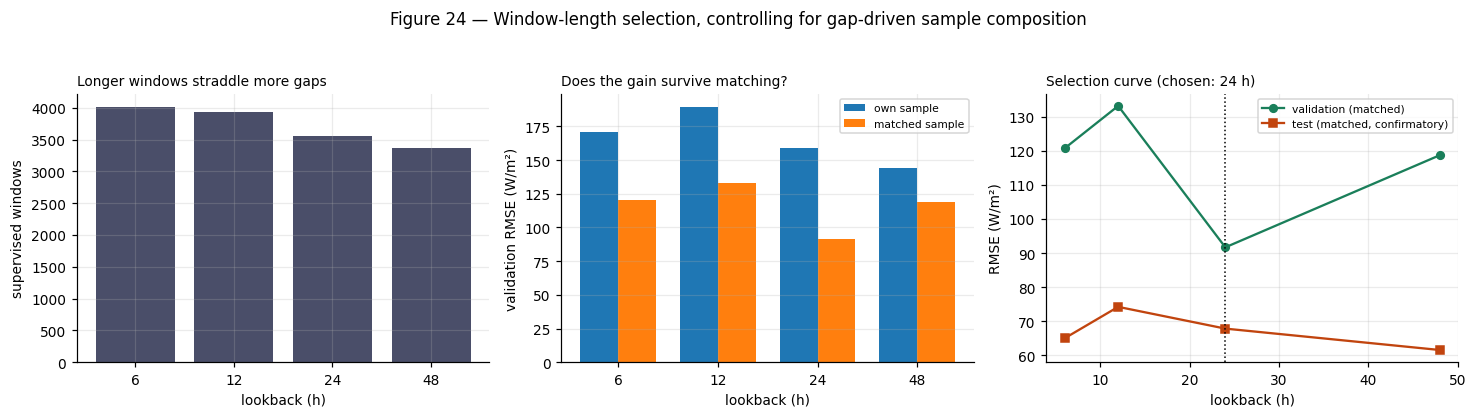

In [ ]:
LOOKBACK_GRID = [6, 12, 24, 48]
LB_MODEL = "GRU"


def _pred_frame(model, kind, X, y, meta, sc):
    p, _, _ = predict(kind, model, sc(X))
    cs = meta["ghi_cs"].to_numpy()
    return pd.DataFrame({"ts": meta["ts"].to_numpy(),
                         "y": y * cs,
                         "yhat": np.clip(p * cs, 0, None)})


def run_lookback_study():
    d = FEAT[FEAT.site == MODEL_SITE]
    orig = CFG.LOOKBACK
    val_frames, test_frames, counts = {}, {}, []
    try:
        for L in LOOKBACK_GRID:
            CFG.LOOKBACK = L
            built = build_supervised(d, ALL_FEATURES)
            if built is None:
                log(f"  lookback {L}h: too few windows, skipped", "warn")
                continue
            X, y, meta = built
            sp = chrono_split(X, y, meta)
            sc = Standardiser().fit(sp["train"][0])
            m = fit_seeded_lb(LB_MODEL, sp, sc, CFG.SEED)
            val_frames[L] = _pred_frame(m, LB_MODEL, *sp["val"], sc)
            test_frames[L] = _pred_frame(m, LB_MODEL, *sp["test"], sc)
            jkt = ALL_FEATURES.index("kt")
            cs_te = sp["test"][2]["ghi_cs"].to_numpy()
            y_te = sp["test"][1] * cs_te
            pers = np.clip(sp["test"][0][:, -1, jkt] * cs_te, 0, None)
            clim = np.clip(climatology_lookup(sp)(sp["test"][2]) * cs_te, 0, None)
            counts.append({"lookback_h": L,
                           "persistence_RMSE": float(np.sqrt(((pers - y_te) ** 2).mean())),
                           "climatology_RMSE": float(np.sqrt(((clim - y_te) ** 2).mean())),
                           "n_train": len(sp["train"][1]), "n_val": len(sp["val"][1]),
                           "n_test": len(sp["test"][1]),
                           "windows_total": len(y),
                           "retention_%": 100 * len(y) / max(len(d[d.is_daylight]), 1)})
            log(f"  lookback {L:>2}h -> {len(y):,} windows "
                f"({counts[-1]['retention_%']:.1f}% of daylight hours retained)", "ok")
            gc.collect()
    finally:
        CFG.LOOKBACK = orig
    return counts, val_frames, test_frames


def fit_seeded_lb(kind, split, scaler, seed):
    Xtr, ytr, _ = split["train"]
    Xva, yva, _ = split["val"]
    tf.keras.utils.set_random_seed(seed)
    m = build_model(kind, Xtr.shape[-1])
    m.fit(scaler(Xtr), ytr, validation_data=(scaler(Xva), yva),
          epochs=CFG.EPOCHS, batch_size=CFG.BATCH, verbose=0,
          callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=CFG.PATIENCE,
                                                   restore_best_weights=True)])
    return m


def _rmse(df):
    return float(np.sqrt(((df["yhat"] - df["y"]) ** 2).mean()))


counts, VAL_F, TEST_F = run_lookback_study()
LB_COUNTS = pd.DataFrame(counts)

if len(VAL_F) >= 2:
    common_val = set.intersection(*[set(f["ts"]) for f in VAL_F.values()])
    common_test = set.intersection(*[set(f["ts"]) for f in TEST_F.values()])
    rows = []
    for L in sorted(VAL_F):
        v, t = VAL_F[L], TEST_F[L]
        vm = v[v["ts"].isin(common_val)]
        tm = t[t["ts"].isin(common_test)]
        rows.append({"lookback_h": L,
                     "val_RMSE_own": _rmse(v), "val_n_own": len(v),
                     "val_RMSE_matched": _rmse(vm), "val_n_matched": len(vm),
                     "test_RMSE_own": _rmse(t), "test_n_own": len(t),
                     "test_RMSE_matched": _rmse(tm), "test_n_matched": len(tm)})
    LOOKBACK_STUDY = pd.DataFrame(rows).round(3)

    print("SAMPLE RETENTION AND TEST-SET DIFFICULTY BY WINDOW LENGTH")
    print(textwrap.fill(
        "The two right-hand columns are model-free: persistence and climatology contain no learned "
        "parameters and cannot be affected by window length except through which hours survive into "
        "the test set. Any variation in them is therefore pure sample composition. If they move "
        "materially across window lengths, raw RMSE cannot be compared across those settings at all.",
        100))
    print("=" * 100)
    print(LB_COUNTS.round(2).to_string(index=False))
    print("\nLOOKBACK COMPARISON — OWN SAMPLE vs MATCHED SAMPLE (RMSE, W/m²)")
    print("=" * 118)
    print(LOOKBACK_STUDY.to_string(index=False))
    save_table(LB_COUNTS, "lookback_retention")
    save_table(LOOKBACK_STUDY, "lookback_study")

    best_own = int(LOOKBACK_STUDY.loc[LOOKBACK_STUDY.val_RMSE_own.idxmin(), "lookback_h"])
    best_matched = int(LOOKBACK_STUDY.loc[LOOKBACK_STUDY.val_RMSE_matched.idxmin(), "lookback_h"])
    naive_gain = (LOOKBACK_STUDY.val_RMSE_own.max() - LOOKBACK_STUDY.val_RMSE_own.min())
    matched_gain = (LOOKBACK_STUDY.val_RMSE_matched.max() - LOOKBACK_STUDY.val_RMSE_matched.min())

    print(f"\n  Selected on VALIDATION, own sample    : {best_own} h")
    print(f"  Selected on VALIDATION, matched sample: {best_matched} h")
    print(f"  Spread attributable to window length, own sample    : {naive_gain:7.2f} W/m²")
    print(f"  Spread surviving sample matching                    : {matched_gain:7.2f} W/m²")
    if naive_gain > 0:
        share = 100 * (1 - matched_gain / naive_gain)
        print(f"  Share of the apparent lookback effect explained by "
              f"differing sample composition: {share:.0f}%")

    print()
    if best_matched == CFG.LOOKBACK:
        print(f"  CONCLUSION: CFG.LOOKBACK = {CFG.LOOKBACK} h is confirmed on matched validation "
              f"samples. The headline results are reported at this setting.")
    else:
        print(f"  ACTION REQUIRED: matched validation evidence favours {best_matched} h, but "
              f"CFG.LOOKBACK is set to {CFG.LOOKBACK} h. Change CFG.LOOKBACK in Part 0 to "
              f"{best_matched} and re-run. Checkpoints are keyed by window geometry, so no stale "
              f"artifact will be reused.")

    print("\n" + textwrap.fill(
        "Interpretation. If the matched spread is much smaller than the own-sample spread, most of "
        "the apparent benefit of a short window was never about the model: it came from short "
        "windows surviving Darwin's data gaps and therefore being scored on an easier subset of the "
        "record. Reporting the naive sweep alone would have overstated the achievable accuracy and "
        "attributed a data-coverage effect to model design. If instead the matched spread remains "
        "large, the effect is genuine and indicates that cloud-state information beyond roughly "
        f"{best_matched} hours contributes little at this site, which is itself consistent with the "
        "rapid decay of clear-sky-index autocorrelation shown in Figure 10.", 100))

    fig, axes = plt.subplots(1, 3, figsize=(13.5, 3.6))
    axes[0].bar(LB_COUNTS.lookback_h.astype(str), LB_COUNTS.windows_total, color="#4a4e69")
    axes[0].set_xlabel("lookback (h)"); axes[0].set_ylabel("supervised windows")
    axes[0].set_title("Longer windows straddle more gaps", fontsize=9, loc="left")

    w = 0.38
    xs = np.arange(len(LOOKBACK_STUDY))
    axes[1].bar(xs - w / 2, LOOKBACK_STUDY.val_RMSE_own, w, label="own sample")
    axes[1].bar(xs + w / 2, LOOKBACK_STUDY.val_RMSE_matched, w, label="matched sample")
    axes[1].set_xticks(xs); axes[1].set_xticklabels(LOOKBACK_STUDY.lookback_h.astype(str))
    axes[1].set_xlabel("lookback (h)"); axes[1].set_ylabel("validation RMSE (W/m²)")
    axes[1].legend(fontsize=7)
    axes[1].set_title("Does the gain survive matching?", fontsize=9, loc="left")

    axes[2].plot(LOOKBACK_STUDY.lookback_h, LOOKBACK_STUDY.val_RMSE_matched, "-o",
                 ms=5, color="#1a7f5a", label="validation (matched)")
    axes[2].plot(LOOKBACK_STUDY.lookback_h, LOOKBACK_STUDY.test_RMSE_matched, "-s",
                 ms=5, color="#c1440e", label="test (matched, confirmatory)")
    axes[2].axvline(CFG.LOOKBACK, color="k", ls=":", lw=1)
    axes[2].set_xlabel("lookback (h)"); axes[2].set_ylabel("RMSE (W/m²)"); axes[2].legend(fontsize=7)
    axes[2].set_title(f"Selection curve (chosen: {CFG.LOOKBACK} h)", fontsize=9, loc="left")
    fig.suptitle("Figure 24 — Window-length selection, controlling for gap-driven sample composition",
                 y=1.04)
    savefig(fig, "fig24_lookback_selection"); plt.show()
else:
    LOOKBACK_STUDY = pd.DataFrame()
    log("lookback study needs at least two feasible window lengths", "warn")

## PART 9 — Main experiment: four architectures on the tropical target site

Objectives 1, 2 and 4–5. Trained on Darwin with seasonal conditioning active.

[ 9947.2s |   1874MB]  ok   trained LSTM               epochs=31  val_loss=0.05007
[ 9960.9s |   1890MB]  ok   trained GRU                epochs=51  val_loss=0.04752
[ 9979.5s |   1927MB]  ok   trained MC-Dropout LSTM    epochs=60  val_loss=0.04969
[ 9992.3s |   1956MB]  ok   trained QR-GRU             epochs=43  val_loss=0.04762

MAIN RESULTS — DARWIN test set, t+1h, daylight hours only
                 model   n  RMSE_Wm2  MAE_Wm2    R2  nRMSE_%  CRPS_Wm2  Pinball_q10  Pinball_q50  Pinball_q90  PICP_80  MIW_Wm2  PINAW_%  PICP_90
Persistence (baseline) 535   129.312   96.283 0.813   29.583    96.283       49.830       48.141       46.452      NaN      NaN      NaN      NaN
                  LSTM 535   182.348  105.781 0.629   41.716   105.781       69.582       52.891       36.199      NaN      NaN      NaN      NaN
                   GRU 535   171.971  101.562 0.670   39.342   101.562       68.681       50.781       32.881      NaN      NaN      NaN      NaN
       MC-Dropout LSTM 53

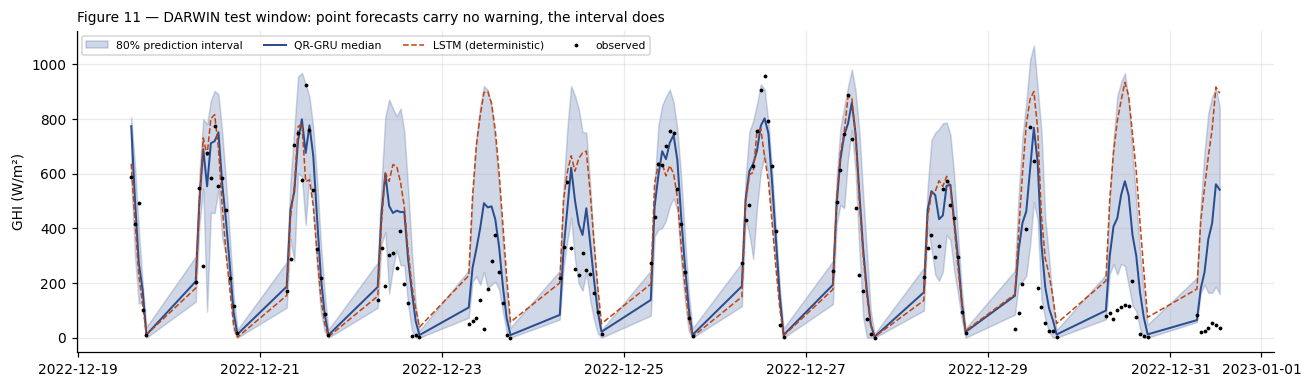

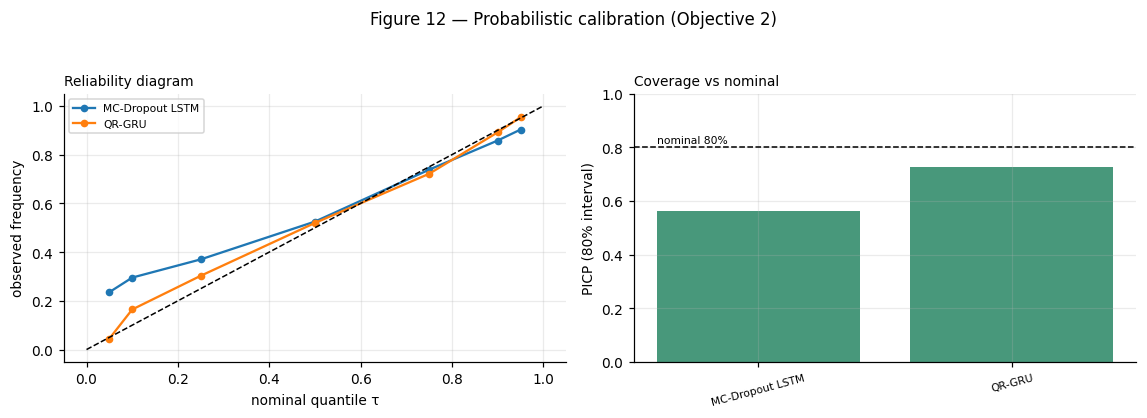

In [ ]:
SCALERS, MODELS, PREDS = {}, {}, {}


def run_main():
    split = DATASETS[MODEL_SITE]
    sc = Standardiser().fit(split["train"][0])
    SCALERS[MODEL_SITE] = sc
    Xte, yte, mte = split["test"]
    Xte_s = sc(Xte)

    rows = []
    pk, pm, py = persistence_baseline(split)
    r0 = evaluate("Persistence (baseline)", pk, None, None, py, pm)
    if r0:
        rows.append(r0)

    for kind in MODEL_KINDS:
        model, hist = fit_model(kind, split, sc)
        point, Q, S = predict(kind, model, Xte_s)
        MODELS[kind] = model
        PREDS[kind] = (point, Q, S, yte, mte)
        r = evaluate(kind, point, Q, S, yte, mte)
        if r:
            rows.append(r)
    return pd.DataFrame(rows)


RESULTS_MAIN = run_main()
print(f"\nMAIN RESULTS — {MODEL_SITE} test set, t+{CFG.HORIZON}h, daylight hours only")
print("=" * 118)
print(RESULTS_MAIN.round(3).to_string(index=False))
save_table(RESULTS_MAIN, "results_main")

# ---------------- Figure 11: forecast vs truth with uncertainty band -----------
qr_kind = "QR-GRU" if "QR-GRU" in PREDS else None
if qr_kind:
    point, Q, S, yte, mte = PREDS[qr_kind]
    cs = mte["ghi_cs"].to_numpy()
    n0 = 0          # first ~6 days of daylight test windows (v5 wrote min(len-1, 0), always 0)
    seg = slice(n0, n0 + 24 * 6)
    fig, ax = plt.subplots(figsize=(12, 3.6))
    t = mte["ts"].iloc[seg]
    ax.fill_between(t, (Q[seg, CFG.QUANTILES.index(0.10)] * cs[seg]).clip(0),
                    (Q[seg, CFG.QUANTILES.index(0.90)] * cs[seg]).clip(0),
                    color="#2a4d8f", alpha=.22, label="80% prediction interval")
    ax.plot(t, (point[seg] * cs[seg]).clip(0), color="#2a4d8f", lw=1.3, label="QR-GRU median")
    if "LSTM" in PREDS:
        ax.plot(t, (PREDS["LSTM"][0][seg] * cs[seg]).clip(0), color="#c1440e",
                lw=1.0, ls="--", label="LSTM (deterministic)")
    ax.plot(t, (yte[seg] * cs[seg]), "k.", ms=3, label="observed")
    ax.set_ylabel("GHI (W/m²)"); ax.legend(fontsize=7, ncol=4)
    ax.set_title(f"Figure 11 — {MODEL_SITE} test window: point forecasts carry no warning, "
                 "the interval does", loc="left", fontsize=9)
    savefig(fig, "fig11_forecast"); plt.show()

# ---------------- Figure 12: calibration / reliability -------------------------
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.6))
for kind in [k for k in MODEL_KINDS if k in PROBABILISTIC and k in PREDS]:
    point, Q, S, yte, mte = PREDS[kind]
    cs = mte["ghi_cs"].to_numpy()
    yt = yte * cs
    obs = [float((yt <= np.clip(Q[:, j] * cs, 0, None)).mean()) for j in range(len(CFG.QUANTILES))]
    axes[0].plot(CFG.QUANTILES, obs, "-o", ms=4, label=kind)
axes[0].plot([0, 1], [0, 1], "k--", lw=1)
axes[0].set_xlabel("nominal quantile τ"); axes[0].set_ylabel("observed frequency")
axes[0].set_title("Reliability diagram", fontsize=9, loc="left"); axes[0].legend(fontsize=7)

sub = RESULTS_MAIN.dropna(subset=["PICP_80"])
axes[1].bar(sub.model, sub.PICP_80, color="#1a7f5a", alpha=.8)
axes[1].axhline(0.80, color="k", ls="--", lw=1)
axes[1].text(-.4, .815, "nominal 80%", fontsize=7)
axes[1].set_ylim(0, 1); axes[1].set_ylabel("PICP (80% interval)")
axes[1].tick_params(axis="x", rotation=15, labelsize=7)
axes[1].set_title("Coverage vs nominal", fontsize=9, loc="left")
fig.suptitle("Figure 12 — Probabilistic calibration (Objective 2)", y=1.04)
savefig(fig, "fig12_calibration"); plt.show()

---
# PART 9A — Probabilistic calibration: diagnosis, and a conformal repair

**What we are analysing.** Whether the prediction intervals mean what they claim, using three
diagnostics that PICP alone cannot provide, followed by a distribution-free recalibration.

**Why it matters.** Part 13 of the executed run produced an uncomfortable result: coverage was
non-monotonic across interval-width bands (0.804 → 0.755 → 0.726 → 0.726 → 0.888). Only the
narrowest band was honest. An operator acting on the mid-width intervals would be under-reserved
— the exact failure mode probabilistic forecasting is supposed to prevent. A headline PICP near
nominal can hide this completely, because over-coverage in wide bands offsets under-coverage in
narrow ones.

**What the code does.**

* **PIT histogram.** The probability integral transform: if the predictive distribution is
  correct, PIT values are uniform. A ∪ shape means intervals are too narrow (over-confident); a ∩
  shape means too wide; a tilt means bias.
* **Winkler / interval score.** A proper score for intervals that charges the width *plus* a
  penalty proportional to how far an observation falls outside. Unlike PICP it cannot be gamed by
  widening intervals indefinitely.
* **Conformalized Quantile Regression (Romano, Patterson & Candès, 2019).** Using the
  **validation** split only, compute the conformity scores
  `E_i = max(q_lo(x_i) − y_i, y_i − q_hi(x_i))`, take their ⌈(n+1)(1−α)⌉/n empirical quantile, and
  widen the test intervals by that constant. This yields finite-sample marginal coverage ≥ 1−α
  under exchangeability, without retraining and without touching the test set.

The conformal step is a genuine repair rather than an addition: it converts an interval that is
descriptively interesting into one that can carry an operating decision.

INTERVAL QUALITY BEFORE AND AFTER CONFORMAL RECALIBRATION
          model intervals  PICP_80  MIW_Wm2  Winkler_Wm2  coverage_error  delta_kt
MC-Dropout LSTM       raw   0.5626 157.4395     553.6546         -0.2374    0.1519
MC-Dropout LSTM conformal   0.8393 335.2202     482.3291          0.0393    0.1519
         QR-GRU       raw   0.7271 210.0824     348.5778         -0.0729    0.0547
         QR-GRU conformal   0.8729 273.6703     352.4962          0.0729    0.0547


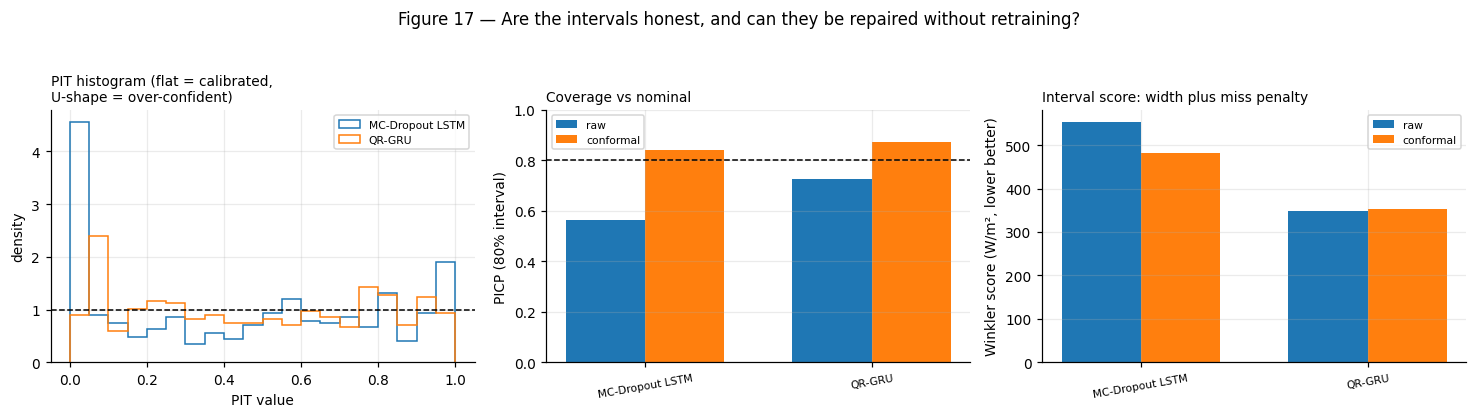

Reading the PIT panel: mass piling up at 0 and 1 means observations fall outside the predictive
distribution more often than they should, i.e. the intervals are too narrow. The conformal
correction is a single additive widening in clear-sky-index units, learned on validation data only,
so any coverage gain it delivers on the test set is genuine out-of-sample evidence rather than a
fitted artefact. Where Winkler falls as well as PICP rising, the repair is efficient: coverage was
bought with less width than the raw model would have needed.


In [ ]:
COVERAGE = CFG.PI_HIGH - CFG.PI_LOW       # nominal coverage of the central interval (0.80)
ALPHA = 1.0 - COVERAGE                    # nominal miss rate (0.20)
I_LO, I_HI = CFG.QUANTILES.index(CFG.PI_LOW), CFG.QUANTILES.index(CFG.PI_HIGH)


def pit_values(Q_kt, S_kt, y_kt):
    """Probability integral transform of the observation under the predictive law."""
    if S_kt is not None:
        return (S_kt <= y_kt[:, None]).mean(axis=1)
    taus = np.array(CFG.QUANTILES)
    return np.array([np.interp(y, Q_kt[i], taus, left=0.0, right=1.0)
                     for i, y in enumerate(y_kt)])


def winkler(y, lo, hi, alpha=ALPHA):
    w = hi - lo
    w = np.where(y < lo, w + 2.0 / alpha * (lo - y), w)
    w = np.where(y > hi, w + 2.0 / alpha * (y - hi), w)
    return w


def conformal_delta(model, kind, split, sc, alpha=ALPHA):
    """CQR width correction estimated on the VALIDATION split only."""
    Xv, yv, _ = split["val"]
    _, Qv, Sv = predict(kind, model, sc(Xv))
    if Qv is None:
        return None
    lo, hi = Qv[:, I_LO], Qv[:, I_HI]
    E = np.maximum(lo - yv, yv - hi)
    n = len(E)
    k = int(np.ceil((n + 1) * (1 - alpha)))
    k = min(max(k, 1), n)
    return float(np.sort(E)[k - 1])


CALIB_ROWS, PITS, CONFORMAL = [], {}, {}
split_main = DATASETS[MODEL_SITE]
sc_main = SCALERS[MODEL_SITE]

for kind in [k for k in MODEL_KINDS if k in PROBABILISTIC and k in PREDS]:
    point, Q, S, yte, mte = PREDS[kind]
    cs = mte["ghi_cs"].to_numpy()
    yt = yte * cs
    lo = np.clip(Q[:, I_LO] * cs, 0, None)
    hi = np.clip(Q[:, I_HI] * cs, 0, None)
    PITS[kind] = pit_values(Q, S, yte)

    delta = conformal_delta(MODELS[kind], kind, split_main, sc_main)
    CONFORMAL[kind] = delta
    lo_c = np.clip((Q[:, I_LO] - delta) * cs, 0, None)
    hi_c = np.clip((Q[:, I_HI] + delta) * cs, 0, None)

    for tag, L, H in (("raw", lo, hi), ("conformal", lo_c, hi_c)):
        CALIB_ROWS.append({
            "model": kind, "intervals": tag,
            "PICP_80": float(((yt >= L) & (yt <= H)).mean()),
            "MIW_Wm2": float((H - L).mean()),
            "Winkler_Wm2": float(winkler(yt, L, H).mean()),
            "coverage_error": float(((yt >= L) & (yt <= H)).mean() - COVERAGE),
            "delta_kt": delta})

CALIB = pd.DataFrame(CALIB_ROWS).round(4)
print("INTERVAL QUALITY BEFORE AND AFTER CONFORMAL RECALIBRATION")
print("=" * 110)
print(CALIB.to_string(index=False))
save_table(CALIB, "results_calibration_conformal")

# ---- Figure 17 --------------------------------------------------------------
kinds_p = list(PITS)
if kinds_p:
    fig, axes = plt.subplots(1, 3, figsize=(13.5, 3.6))
    for kind in kinds_p:
        axes[0].hist(PITS[kind], bins=20, range=(0, 1), density=True,
                     histtype="step", lw=1.8, label=kind)
    axes[0].axhline(1.0, color="k", ls="--", lw=1)
    axes[0].set_xlabel("PIT value"); axes[0].set_ylabel("density")
    axes[0].legend(fontsize=7)
    axes[0].set_title("PIT histogram (flat = calibrated,\nU-shape = over-confident)",
                      fontsize=9, loc="left")

    sub = CALIB.copy()
    xs = np.arange(len(kinds_p)); w = 0.35
    for i, tag in enumerate(("raw", "conformal")):
        v = [sub[(sub.model == k) & (sub.intervals == tag)]["PICP_80"].iloc[0] for k in kinds_p]
        axes[1].bar(xs + (i - .5) * w, v, w, label=tag)
    axes[1].axhline(COVERAGE, color="k", ls="--", lw=1)
    axes[1].set_xticks(xs); axes[1].set_xticklabels(kinds_p, fontsize=7, rotation=10)
    axes[1].set_ylabel("PICP (80% interval)"); axes[1].legend(fontsize=7); axes[1].set_ylim(0, 1)
    axes[1].set_title("Coverage vs nominal", fontsize=9, loc="left")

    for i, tag in enumerate(("raw", "conformal")):
        v = [sub[(sub.model == k) & (sub.intervals == tag)]["Winkler_Wm2"].iloc[0] for k in kinds_p]
        axes[2].bar(xs + (i - .5) * w, v, w, label=tag)
    axes[2].set_xticks(xs); axes[2].set_xticklabels(kinds_p, fontsize=7, rotation=10)
    axes[2].set_ylabel("Winkler score (W/m², lower better)"); axes[2].legend(fontsize=7)
    axes[2].set_title("Interval score: width plus miss penalty", fontsize=9, loc="left")
    fig.suptitle("Figure 17 — Are the intervals honest, and can they be repaired without retraining?",
                 y=1.04)
    savefig(fig, "fig17_calibration_conformal"); plt.show()

    print(textwrap.fill(
        "Reading the PIT panel: mass piling up at 0 and 1 means observations fall outside the "
        "predictive distribution more often than they should, i.e. the intervals are too narrow. "
        "The conformal correction is a single additive widening in clear-sky-index units, learned "
        "on validation data only, so any coverage gain it delivers on the test set is genuine "
        "out-of-sample evidence rather than a fitted artefact. Where Winkler falls as well as PICP "
        "rising, the repair is efficient: coverage was bought with less width than the raw model "
        "would have needed.", 100))

---
# PART 9B — Error and residual analysis

**What we are analysing.** The structure of the errors, not their average size.

**Why it matters.** RMSE is a single number that assumes errors are exchangeable. They are not.
Three specific questions determine whether the models are trustworthy and whether headroom
remains:

1. **Are residuals autocorrelated?** If the error at hour *t* predicts the error at *t+1*, the
   model has left exploitable structure on the table — a concrete, testable claim of
   under-fitting rather than a vague one.
2. **Are residuals heteroscedastic in a predictable way?** If error variance rises with cloud
   cover, then a *constant* reserve margin is wrong by construction and a
   forecast-conditional one is justified. This is the statistical case for probabilistic
   forecasting, made from the residuals rather than asserted from the literature.
3. **Where do the worst errors live?** Operators are hurt by tails, not means. The top 1% of
   errors is examined by hour, season and sky regime.

ERROR STRUCTURE BY SKY-CONDITION REGIME
          model          sky   n     MAE    RMSE    bias      sd
            GRU     Overcast  89 268.908 356.163 266.924 237.140
            GRU Broken cloud 167  78.175 125.240  61.844 109.233
            GRU        Clear 279  62.177  82.801 -36.356  74.526
           LSTM     Overcast  89 284.833 382.732 281.232 261.072
           LSTM Broken cloud 167  78.706 124.965  51.233 114.323
           LSTM        Clear 279  64.871  87.667 -40.363  77.962
MC-Dropout LSTM     Overcast  89 216.699 279.165 216.608 177.106
MC-Dropout LSTM Broken cloud 167  81.449 127.878  72.765 105.474
MC-Dropout LSTM        Clear 279  60.675  76.484 -41.275  64.507
         QR-GRU     Overcast  89 151.123 206.593 149.937 142.930
         QR-GRU Broken cloud 167  72.562 117.721  55.657 104.044
         QR-GRU        Clear 279  54.474  76.434 -21.572  73.458

RESIDUAL AUTOCORRELATION (0 = no exploitable structure left)
lag_h               1      2      3      24
model    

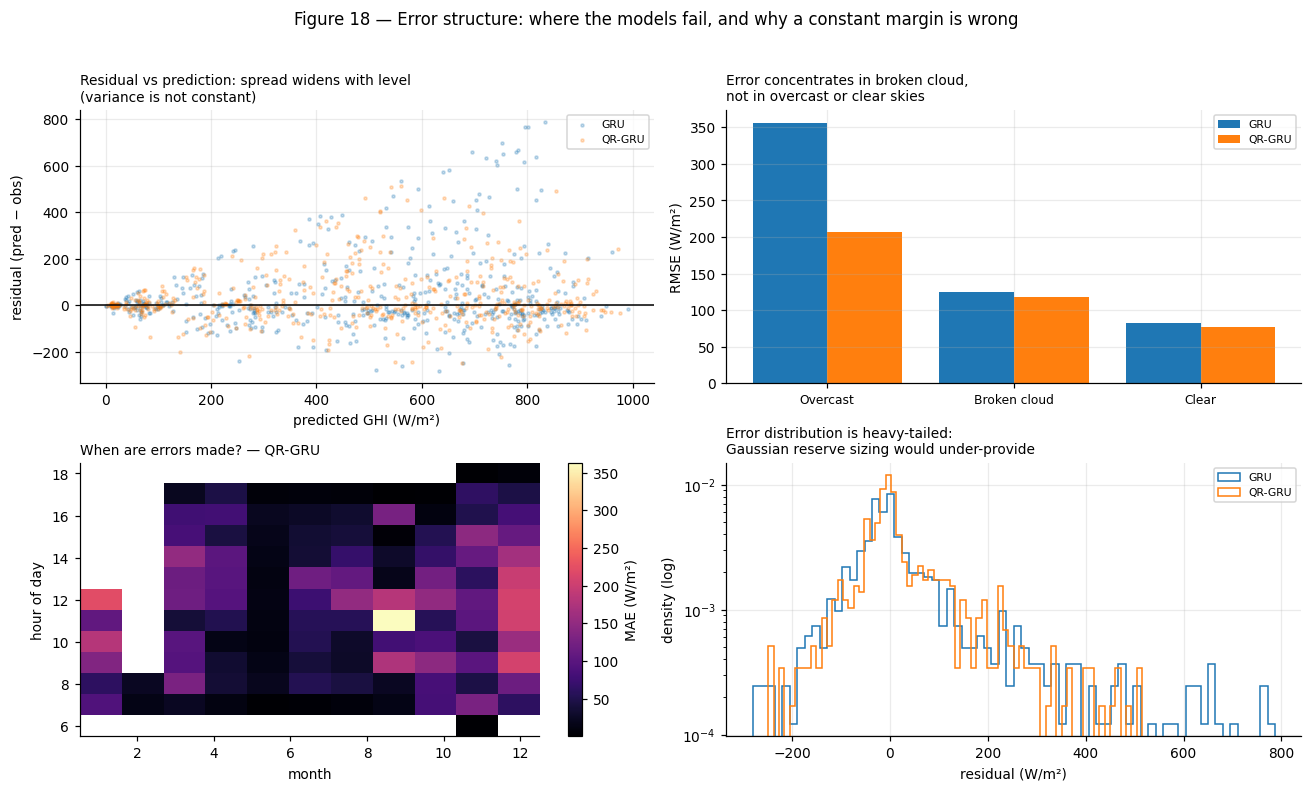

In [ ]:
def residual_frame(kind):
    point, Q, S, yte, mte = PREDS[kind]
    cs = mte["ghi_cs"].to_numpy()
    yhat = np.clip(point * cs, 0, None)
    ytrue = yte * cs
    d = mte.copy()
    d["y"] = ytrue
    d["yhat"] = yhat
    d["resid"] = yhat - ytrue
    d["abserr"] = np.abs(d["resid"])
    d["kt_true"] = yte
    d["sky"] = classify_sky(pd.Series(yte, index=d.index))
    d["hour"] = d["ts"].dt.hour
    d["month"] = d["ts"].dt.month
    d["model"] = kind
    return d


RESID = pd.concat([residual_frame(k) for k in MODEL_KINDS if k in PREDS], ignore_index=True)
save_table(RESID.drop(columns=["ghi_cs"], errors="ignore").assign(ts=RESID.ts.astype(str)),
           "residuals_test")

# ---- 1. residual autocorrelation --------------------------------------------
acf_rows = []
for kind in [k for k in MODEL_KINDS if k in PREDS]:
    r = RESID[RESID.model == kind].sort_values("ts")["resid"].reset_index(drop=True)
    for lag in (1, 2, 3, 24):
        if len(r) > lag + 10:
            acf_rows.append({"model": kind, "lag_h": lag, "resid_autocorr": float(r.autocorr(lag))})
RESID_ACF = pd.DataFrame(acf_rows)

# ---- 2. heteroscedasticity: error vs sky regime ------------------------------
het = (RESID.dropna(subset=["sky"])
       .groupby(["model", "sky"], observed=True)
       .agg(n=("abserr", "size"), MAE=("abserr", "mean"),
            RMSE=("resid", lambda s: float(np.sqrt((s ** 2).mean()))),
            bias=("resid", "mean"), sd=("resid", "std"))
       .reset_index())
het["sky"] = pd.Categorical(het["sky"], SKY_ORDER, ordered=True)
HETERO = het.sort_values(["model", "sky"]).round(3)

print("ERROR STRUCTURE BY SKY-CONDITION REGIME")
print("=" * 100)
print(HETERO.to_string(index=False))
save_table(HETERO, "results_error_by_regime")
print("\nRESIDUAL AUTOCORRELATION (0 = no exploitable structure left)")
print(RESID_ACF.pivot(index="model", columns="lag_h", values="resid_autocorr").round(3).to_string())
save_table(RESID_ACF, "results_residual_acf")

# ---- 3. extreme errors -------------------------------------------------------
ext_rows = []
for kind in [k for k in MODEL_KINDS if k in PREDS]:
    r = RESID[RESID.model == kind]
    thr = r["abserr"].quantile(0.99)
    tail = r[r.abserr >= thr]
    ext_rows.append({
        "model": kind, "p99_abserr_Wm2": float(thr),
        "max_abserr_Wm2": float(r.abserr.max()),
        "tail_share_of_SSE_%": float(100 * (tail.resid ** 2).sum() / (r.resid ** 2).sum()),
        "tail_in_broken_cloud_%": float(100 * (tail.sky == "Broken cloud").mean()),
        "tail_on_ramp_hours_%": float(100 * tail.is_ramp.mean()),
        "tail_wet_season_%": float(100 * (tail.is_wet > 0).mean()),
        "tail_median_hour": float(tail.hour.median())})
EXTREME = pd.DataFrame(ext_rows).round(2)
print("\nEXTREME-ERROR ANATOMY (worst 1% of hours)")
print(EXTREME.to_string(index=False))
save_table(EXTREME, "results_extreme_errors")

# ---- Figure 18 ---------------------------------------------------------------
best_det = min([k for k in MODEL_KINDS if k in PREDS and k not in PROBABILISTIC],
               key=lambda k: RESID[RESID.model == k].resid.pow(2).mean(), default=None)
best_prob = min([k for k in MODEL_KINDS if k in PREDS and k in PROBABILISTIC],
                key=lambda k: RESID[RESID.model == k].resid.pow(2).mean(), default=None)
show = [k for k in (best_det, best_prob) if k]

fig, axes = plt.subplots(2, 2, figsize=(12, 7))
ax = axes[0, 0]
for kind in show:
    r = RESID[RESID.model == kind]
    ax.scatter(r["yhat"], r["resid"], s=4, alpha=.25, label=kind)
ax.axhline(0, color="k", lw=1)
ax.set_xlabel("predicted GHI (W/m²)"); ax.set_ylabel("residual (pred − obs)")
ax.legend(fontsize=7)
ax.set_title("Residual vs prediction: spread widens with level\n(variance is not constant)",
             fontsize=9, loc="left")

ax = axes[0, 1]
xs = np.arange(len(SKY_ORDER)); w = 0.8 / max(len(show), 1)
for i, kind in enumerate(show):
    h = HETERO[HETERO.model == kind].set_index("sky").reindex(SKY_ORDER)
    ax.bar(xs + (i - (len(show) - 1) / 2) * w, h["RMSE"], w, label=kind)
ax.set_xticks(xs); ax.set_xticklabels(SKY_ORDER, fontsize=8)
ax.set_ylabel("RMSE (W/m²)"); ax.legend(fontsize=7)
ax.set_title("Error concentrates in broken cloud,\nnot in overcast or clear skies", fontsize=9, loc="left")

ax = axes[1, 0]
if show:
    r = RESID[RESID.model == show[-1]]
    piv = r.pivot_table(index="hour", columns="month", values="abserr", aggfunc="mean")
    im = ax.imshow(piv, aspect="auto", origin="lower", cmap="magma",
                   extent=[piv.columns.min() - .5, piv.columns.max() + .5,
                           piv.index.min() - .5, piv.index.max() + .5])
    fig.colorbar(im, ax=ax, label="MAE (W/m²)")
    ax.set_xlabel("month"); ax.set_ylabel("hour of day"); ax.grid(False)
    ax.set_title(f"When are errors made? — {show[-1]}", fontsize=9, loc="left")

ax = axes[1, 1]
for kind in show:
    r = RESID[RESID.model == kind]["resid"]
    ax.hist(r, bins=70, density=True, histtype="step", lw=1.6, label=kind)
ax.set_yscale("log"); ax.set_xlabel("residual (W/m²)"); ax.set_ylabel("density (log)")
ax.legend(fontsize=7)
ax.set_title("Error distribution is heavy-tailed:\nGaussian reserve sizing would under-provide",
             fontsize=9, loc="left")
fig.suptitle("Figure 18 — Error structure: where the models fail, and why a constant margin is wrong",
             y=1.02)
savefig(fig, "fig18_residuals"); plt.show()

## PART 10 — Seasonal conditioning and ramp-event subgroup analysis

Objective 3. Each architecture is retrained with the `is_wet` feature removed, and scored on the
identical test rows. The difference is the causal contribution of seasonal conditioning, isolated
from every other factor. The same fitted models are then rescored on the ramp-event subgroup only
— the regime where Wan et al. (2017) show deterministic models to be overconfident.

[10181.6s |   2009MB]  ok   trained LSTM               [no season]  epochs=38  val_loss=0.05448
[10197.4s |   2027MB]  ok   trained GRU                [no season]  epochs=60  val_loss=0.04637
[10212.0s |   2004MB]  ok   trained MC-Dropout LSTM    [no season]  epochs=46  val_loss=0.05246
[10226.8s |   2011MB]  ok   trained QR-GRU             [no season]  epochs=52  val_loss=0.04730

SEASONAL CONDITIONING ABLATION (Objective 3)
                   CRPS_Wm2                    PICP_80                   RMSE_Wm2                               
conditioning    with season without season with season without season with season without season Δ improvement %
model                                                                                                           
GRU                 101.562         95.304         NaN            NaN     171.971        161.505          -6.480
LSTM                105.781        114.223         NaN            NaN     182.348        199.337           8.523
MC-Dr

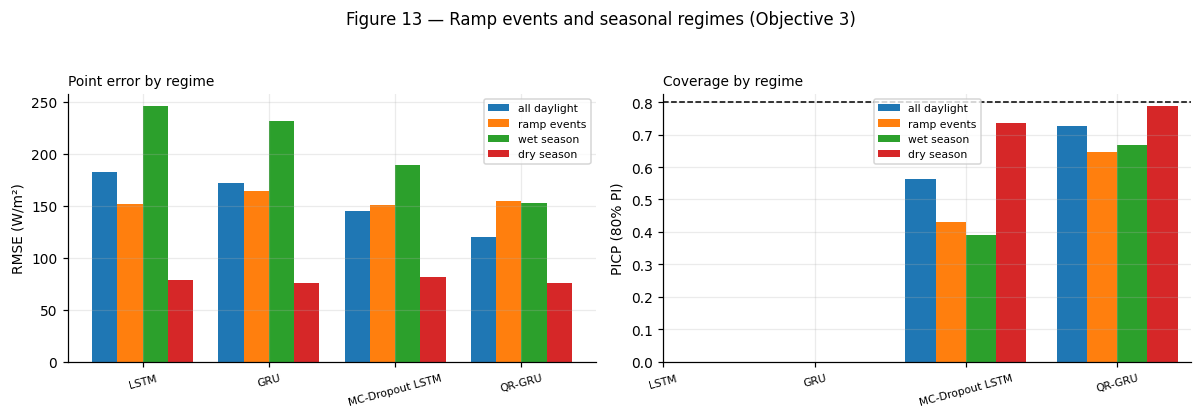

In [ ]:
def run_ablation():
    site = MODEL_SITE
    d = FEAT[FEAT.site == site]
    built = build_supervised(d, BASE_FEATURES)          # season feature removed
    X, y, meta = built
    split_ns = chrono_split(X, y, meta)
    sc_ns = Standardiser().fit(split_ns["train"][0])
    Xte_ns = sc_ns(split_ns["test"][0])
    yte_ns, mte_ns = split_ns["test"][1], split_ns["test"][2]

    rows = []
    for kind in MODEL_KINDS:
        m_ns, _ = fit_model(kind, split_ns, sc_ns, tag="  [no season]")
        p, Q, S = predict(kind, m_ns, Xte_ns)
        r = evaluate(kind, p, Q, S, yte_ns, mte_ns)
        if r:
            r["conditioning"] = "without season"
            rows.append(r)

        r2 = dict(RESULTS_MAIN[RESULTS_MAIN.model == kind].iloc[0])
        r2["conditioning"] = "with season"
        rows.append(r2)
    return pd.DataFrame(rows)


ABLATION = run_ablation()
# v6: renamed from `piv`. Part 11A reassigned `piv`, so Part 14's seasonal-conditioning line
# read the proxy table, raised KeyError inside a try/except, and was silently omitted.
ABLATION_PIV = piv = ABLATION.pivot_table(index="model", columns="conditioning",
                           values=["RMSE_Wm2", "CRPS_Wm2", "PICP_80"])
ABLATION_PIV[("RMSE_Wm2", "Δ improvement %")] = 100 * (
    ABLATION_PIV[("RMSE_Wm2", "without season")] - ABLATION_PIV[("RMSE_Wm2", "with season")]
) / ABLATION_PIV[("RMSE_Wm2", "without season")]
print("\nSEASONAL CONDITIONING ABLATION (Objective 3)")
print("=" * 110)
print(ABLATION_PIV.round(3).to_string())
save_table(ABLATION, "results_ablation")

# ---- ramp-event subgroup ------------------------------------------------------
ramp_rows = []
for kind in MODEL_KINDS:
    if kind not in PREDS:
        continue
    point, Q, S, yte, mte = PREDS[kind]
    for label, mask in (("all daylight", np.ones(len(yte), bool)),
                        ("ramp events", mte["is_ramp"].to_numpy().astype(bool)),
                        ("wet season", mte["is_wet"].to_numpy() > 0),
                        ("dry season", mte["is_wet"].to_numpy() == 0)):
        r = evaluate(kind, point, Q, S, yte, mte, subset=mask)
        if r:
            r["subgroup"] = label
            ramp_rows.append(r)
SUBGROUP = pd.DataFrame(ramp_rows)
_want_sg = {"all daylight", "ramp events", "wet season", "dry season"}
_missing_sg = _want_sg - set(SUBGROUP.get("subgroup", pd.Series(dtype=str)))
if _missing_sg:
    log(f"subgroup(s) with <10 test hours, omitted: {sorted(_missing_sg)} "
        f"(the chronological test split does not span them)", "warn")
print("\nSUBGROUP ANALYSIS — where uncertainty quantification earns its keep")
print("=" * 118)
print(SUBGROUP[["model", "subgroup", "n", "RMSE_Wm2", "CRPS_Wm2",
                "PICP_80", "MIW_Wm2"]].round(3).to_string(index=False))
save_table(SUBGROUP, "results_subgroup")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
order = [k for k in MODEL_KINDS if k in set(SUBGROUP.model)]
w = 0.2
for i, sg in enumerate(["all daylight", "ramp events", "wet season", "dry season"]):
    s = SUBGROUP[SUBGROUP.subgroup == sg].set_index("model").reindex(order)
    axes[0].bar(np.arange(len(order)) + (i - 1.5) * w, s.RMSE_Wm2, w, label=sg)
    axes[1].bar(np.arange(len(order)) + (i - 1.5) * w, s.PICP_80, w, label=sg)
for ax, ttl, yl in ((axes[0], "Point error by regime", "RMSE (W/m²)"),
                    (axes[1], "Coverage by regime", "PICP (80% PI)")):
    ax.set_xticks(range(len(order)))
    ax.set_xticklabels(order, rotation=15, fontsize=7)
    ax.set_title(ttl, fontsize=9, loc="left"); ax.set_ylabel(yl); ax.legend(fontsize=7)
axes[1].axhline(.8, color="k", ls="--", lw=1)
fig.suptitle("Figure 13 — Ramp events and seasonal regimes (Objective 3)", y=1.04)
savefig(fig, "fig13_subgroup"); plt.show()

---
# PART 10A — Ramp events and extreme conditions, under the corrected definition

**What we are analysing.** Model performance during the corrected (elevation-floored) ramp
events, split by ramp direction, and the single worst forecast day in the test set.

**Why it matters.** Objective 3 asks specifically about wet-season storm ramps. The original run
reported the counter-intuitive result that ramp hours had *lower* RMSE than average for three of
four models, which directly contradicts Wan et al. (2017). Part 5A showed the old ramp flag was
contaminated by dawn/dusk geometry — hours which are trivially easy to forecast because irradiance
is near zero. Re-running the subgroup analysis on the corrected flag tests whether that
contradiction survives, which is the difference between a finding and an artefact.

**Direction matters operationally.** A down-ramp (cloud arriving) creates a generation shortfall
and calls on reserve; an up-ramp creates surplus and at worst curtailment. They are not
symmetric in cost, so they are reported separately.

PERFORMANCE BY OPERATING CONDITION (corrected ramp definition)
          model         condition   n  RMSE_Wm2  MAE_Wm2  CRPS_Wm2  PICP_80  MIW_Wm2
           LSTM      All daylight 535   182.348  105.781   105.781      NaN      NaN
           LSTM  Ramp (corrected)  88   151.992   97.736    97.736      NaN      NaN
           LSTM          Non-ramp 447   187.747  107.365   107.365      NaN      NaN
           LSTM     Sky: Overcast  89   382.732  284.833   284.833      NaN      NaN
           LSTM Sky: Broken cloud 167   124.965   78.706    78.706      NaN      NaN
           LSTM        Sky: Clear 279    87.667   64.871    64.871      NaN      NaN
            GRU      All daylight 535   171.971  101.562   101.562      NaN      NaN
            GRU  Ramp (corrected)  88   163.978  105.480   105.480      NaN      NaN
            GRU          Non-ramp 447   173.501  100.790   100.790      NaN      NaN
            GRU     Sky: Overcast  89   356.163  268.908   268.908      NaN      NaN
  

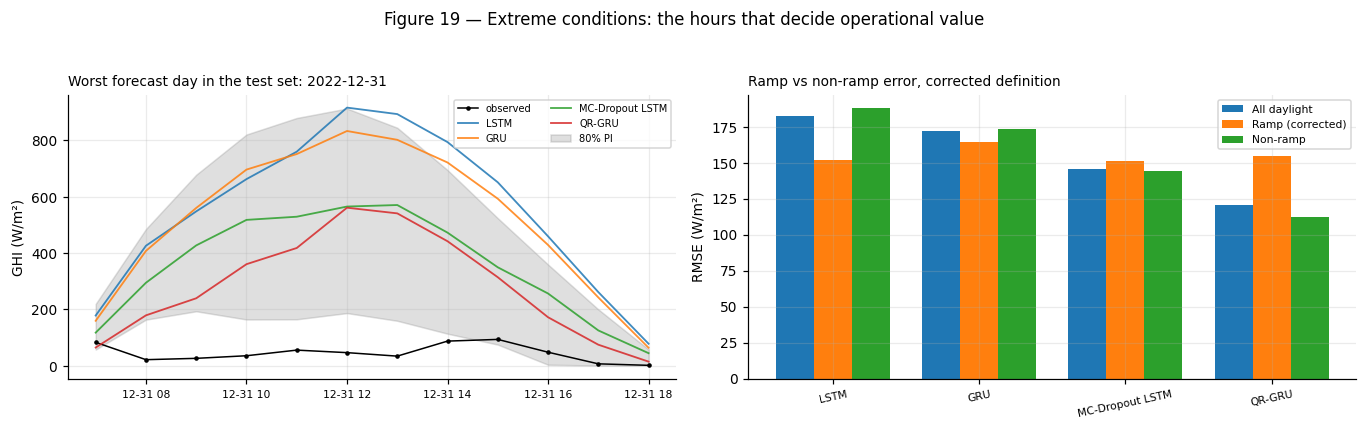

In [ ]:
def ramp_mask_for(meta):
    """Corrected ramp flag looked up from FEAT by timestamp.

    Joining on ts rather than reading meta['is_ramp'] makes this independent of
    whether the supervised windows were built before or after Part 5A applied the
    elevation floor, so the corrected definition is always the one used here.
    """
    ref = (FEAT[FEAT.site == MODEL_SITE][["ts", "is_ramp_kt"]]
           .drop_duplicates("ts").set_index("ts")["is_ramp_kt"])
    return ref.reindex(meta["ts"]).fillna(False).to_numpy().astype(bool)


ramp_rows = []
for kind in [k for k in MODEL_KINDS if k in PREDS]:
    point, Q, S, yte, mte = PREDS[kind]
    ramp = ramp_mask_for(mte)
    subsets = {
        "All daylight": np.ones(len(yte), bool),
        "Ramp (corrected)": ramp,
        "Non-ramp": ~ramp,
    }
    sky = classify_sky(pd.Series(yte))
    for s in SKY_ORDER:
        subsets[f"Sky: {s}"] = (sky == s).to_numpy()
    for label, mask in subsets.items():
        r = evaluate(kind, point, Q, S, yte, mte, subset=mask)
        if r:
            r["condition"] = label
            r["skill_vs_persistence_%"] = skill(r["RMSE_Wm2"])
            ramp_rows.append(r)

CONDITIONS = pd.DataFrame(ramp_rows)
cols = ["model", "condition", "n", "RMSE_Wm2", "MAE_Wm2", "CRPS_Wm2", "PICP_80", "MIW_Wm2"]
print("PERFORMANCE BY OPERATING CONDITION (corrected ramp definition)")
print("=" * 118)
print(CONDITIONS[cols].round(3).to_string(index=False))
save_table(CONDITIONS, "results_by_condition")

old_new = []
for kind in [k for k in MODEL_KINDS if k in PREDS]:
    point, Q, S, yte, mte = PREDS[kind]
    a = evaluate(kind, point, Q, S, yte, mte, subset=np.ones(len(yte), bool))
    b = evaluate(kind, point, Q, S, yte, mte, subset=ramp_mask_for(mte))
    if a and b:
        old_new.append({"model": kind, "all_RMSE": a["RMSE_Wm2"], "ramp_RMSE": b["RMSE_Wm2"],
                        "ramp_penalty_%": 100 * (b["RMSE_Wm2"] - a["RMSE_Wm2"]) / a["RMSE_Wm2"],
                        "ramp_n": b["n"]})
RAMP_PENALTY = pd.DataFrame(old_new).round(2)
print("\nRAMP PENALTY UNDER THE CORRECTED DEFINITION")
print(RAMP_PENALTY.to_string(index=False))
save_table(RAMP_PENALTY, "results_ramp_penalty")

# ---- Figure 19: worst-day case study ----------------------------------------
if len(RESID):
    ref_model = best_prob or best_det
    r = RESID[RESID.model == ref_model].copy()
    r["day"] = r["ts"].dt.floor("D")
    worst_day = r.groupby("day")["abserr"].mean().idxmax()
    day = r[r.day == worst_day].sort_values("ts")

    fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.7))
    ax = axes[0]
    ax.plot(day["ts"], day["y"], "k.-", ms=4, lw=1, label="observed")
    for kind in [k for k in MODEL_KINDS if k in PREDS]:
        dk = RESID[(RESID.model == kind) & (RESID.ts.dt.floor("D") == worst_day)].sort_values("ts")
        ax.plot(dk["ts"], dk["yhat"], lw=1.2, alpha=.85, label=kind)
    if ref_model in PROBABILISTIC and ref_model in PREDS:
        point, Q, S, yte, mte = PREDS[ref_model]
        sel = mte["ts"].dt.floor("D") == worst_day
        cs = mte["ghi_cs"].to_numpy()[sel.to_numpy()]
        ax.fill_between(mte["ts"][sel],
                        np.clip(Q[sel.to_numpy(), I_LO] * cs, 0, None),
                        np.clip(Q[sel.to_numpy(), I_HI] * cs, 0, None),
                        color="grey", alpha=.25, label="80% PI")
    ax.set_ylabel("GHI (W/m²)"); ax.legend(fontsize=6.5, ncol=2)
    ax.set_title(f"Worst forecast day in the test set: {worst_day:%Y-%m-%d}", fontsize=9, loc="left")
    ax.tick_params(axis="x", labelsize=7)

    ax = axes[1]
    order = [k for k in MODEL_KINDS if k in PREDS]
    conds = ["All daylight", "Ramp (corrected)", "Non-ramp"]
    w = 0.26
    for i, c in enumerate(conds):
        v = [CONDITIONS[(CONDITIONS.model == k) & (CONDITIONS.condition == c)]["RMSE_Wm2"]
             for k in order]
        v = [float(x.iloc[0]) if len(x) else np.nan for x in v]
        ax.bar(np.arange(len(order)) + (i - 1) * w, v, w, label=c)
    ax.set_xticks(range(len(order))); ax.set_xticklabels(order, rotation=12, fontsize=7)
    ax.set_ylabel("RMSE (W/m²)"); ax.legend(fontsize=7)
    ax.set_title("Ramp vs non-ramp error, corrected definition", fontsize=9, loc="left")
    fig.suptitle("Figure 19 — Extreme conditions: the hours that decide operational value", y=1.04)
    savefig(fig, "fig19_ramp_extreme"); plt.show()

## PART 11 — Proxy validation: does forecasting irradiance stand in for forecasting power?

Objective 1 (secondary). This is the load-bearing assumption of the whole project: because Darwin
has no measured PV, the study forecasts irradiance and claims it is the precursor to power.
Alice Springs is the only site with **co-located irradiance and measured PV output**, so the
assumption can be tested rather than asserted.

The same GRU is trained twice on identical inputs and identical windows, changing only the target:
once on $k_t$ (irradiance), once on PV output normalised to plant capacity. If the normalised
errors are close, the proxy is defensible and the Darwin result transfers. If they diverge, the
gap is the quantified cost of the proxy — which is itself a reportable finding.

In [ ]:
def run_proxy_validation():
    if "ALICE" not in SITES_OK:
        return None
    d = FEAT[FEAT.site == "ALICE"].copy()
    if d["pv_kw"].notna().sum() < 500:
        log("Alice PV column empty — proxy validation skipped", "warn")
        return None

    cap = float(np.nanpercentile(d["pv_kw"], 99.5))
    d["pv_norm"] = (d["pv_kw"] / cap).clip(0, 1.2)
    # interpolate short PV gaps only, on the same policy used for kt
    miss = d["pv_norm"].isna() & d["is_daylight"]
    runs = _gap_lengths(miss)
    d["pv_norm"] = np.where(miss & (runs <= CFG.MAX_INTERP_GAP_H),
                            d["pv_norm"].interpolate(limit=CFG.MAX_INTERP_GAP_H,
                                                     limit_area="inside"),
                            d["pv_norm"])

    rows = []
    for target, label in (("kt", "irradiance (kt)"), ("pv_norm", "measured PV (normalised)")):
        built = build_supervised(d, ALL_FEATURES, target=target)
        if built is None:
            continue
        X, y, meta = built
        sp = chrono_split(X, y, meta)
        sc = Standardiser().fit(sp["train"][0])
        m, _ = fit_model("GRU", sp, sc, tag=f"  [proxy: {label}]")
        p = m.predict(sc(sp["test"][0]), verbose=0).ravel()
        yt = sp["test"][1]
        err = p - yt
        rows.append({"target": label, "n_test": len(yt),
                     "RMSE_norm": float(np.sqrt((err ** 2).mean())),
                     "MAE_norm": float(np.abs(err).mean()),
                     "nRMSE_%": float(100 * np.sqrt((err ** 2).mean()) / yt.mean()),
                     "R2": float(1 - (err ** 2).sum() / ((yt - yt.mean()) ** 2).sum())})
    return pd.DataFrame(rows)


PROXY = run_proxy_validation()
if PROXY is not None and len(PROXY) == 2:
    delta = PROXY.iloc[1]["nRMSE_%"] - PROXY.iloc[0]["nRMSE_%"]
    print("\nPROXY VALIDATION — irradiance target vs measured-power target (Alice Springs, GRU)")
    print("=" * 100)
    print(PROXY.round(4).to_string(index=False))
    print(f"\n  Static GHI→PV coupling at this site (Figure 9): R² = {PROXY_R2:.4f}")
    print(f"  Forecast-accuracy delta from using irradiance as the target: "
          f"{delta:+.2f} percentage points of nRMSE")
    print(textwrap.fill(
        "Interpretation: a small positive delta means power is marginally harder to forecast than "
        "irradiance (thermal derating, soiling and inverter clipping add variance that irradiance "
        "does not contain), and the Darwin irradiance result should be read as a mild lower bound "
        "on power-forecast error rather than as an equivalent. A near-zero delta means the proxy "
        "is effectively lossless at hourly resolution.", 100,
        initial_indent="  ", subsequent_indent="  "))
    save_table(PROXY, "results_proxy")

[11716.3s |   2099MB]  ok   trained GRU                [proxy: irradiance (kt)]  epochs=60  val_loss=0.02003
[11722.0s |   2063MB]  ok   trained GRU                [proxy: measured PV (normalised)]  epochs=9  val_loss=0.02638

PROXY VALIDATION — irradiance target vs measured-power target (Alice Springs, GRU)
                  target  n_test  RMSE_norm  MAE_norm  nRMSE_%     R2
         irradiance (kt)    2465     0.1367    0.0862  20.1004 0.8697
measured PV (normalised)     786     0.0972    0.0724  37.4195 0.6947

  Static GHI→PV coupling at this site (Figure 9): R² = 0.6916
  Forecast-accuracy delta from using irradiance as the target: +17.32 percentage points of nRMSE
  Interpretation: a small positive delta means power is marginally harder to forecast than
  irradiance (thermal derating, soiling and inverter clipping add variance that irradiance does not
  contain), and the Darwin irradiance result should be read as a mild lower bound on power-forecast
  error rather than as an equ

---
# PART 11A — Proxy validation, corrected: matched samples and all four architectures

**What we are analysing.** The irradiance-as-PV-proxy accuracy delta, on a like-for-like basis.

**Why this replaces Part 11.** The original proxy test has two defects that make its headline
number uninterpretable:

1. **Unmatched test sets.** It scored the irradiance target on 2,057 test hours and the PV target
   on 734, because the Alice Springs PV file covers only part of the irradiance record. Two models
   evaluated on different hours cannot be differenced — the gap conflates target difficulty with
   sample composition.
2. **One architecture.** The proposal commits to evaluating *the same architectures*; only GRU was
   run.

This section restricts both targets to the **intersection** of timestamps where `kt` and
normalised PV are simultaneously available, rebuilds the supervised windows on that common index,
and trains all four architectures on each target. The delta is then attributable to the target
variable alone.

**Why it matters for the thesis.** Darwin has no measured PV. Every tropical conclusion in this
project rests on irradiance standing in for power. That assumption is stated in the proposal as a
contribution; this is the only place it is actually measured, so it needs to be measured properly.

[12001.6s |   2082MB]  ok matched proxy sample: 14,606 hourly rows with BOTH kt and PV present
[12014.6s |   2074MB]  ok   trained LSTM               [proxy Irradiance (k_t)]  epochs=38  val_loss=0.02162
[12034.8s |   2091MB]  ok   trained GRU                [proxy Irradiance (k_t)]  epochs=60  val_loss=0.02004
[12053.2s |   2114MB]  ok   trained MC-Dropout LSTM    [proxy Irradiance (k_t)]  epochs=53  val_loss=0.02735
[12075.4s |   2125MB]  ok   trained QR-GRU             [proxy Irradiance (k_t)]  epochs=60  val_loss=0.02718
[12080.0s |   2146MB]  ok   trained LSTM               [proxy Measured PV (normalised)]  epochs=9  val_loss=0.03663
[12085.2s |   2162MB]  ok   trained GRU                [proxy Measured PV (normalised)]  epochs=9  val_loss=0.03275
[12091.6s |   2114MB]  ok   trained MC-Dropout LSTM    [proxy Measured PV (normalised)]  epochs=10  val_loss=0.02082
[12097.9s |   2111MB]  ok   trained QR-GRU             [proxy Measured PV (normalised)]  epochs=12  val_loss=0.02981
PRO

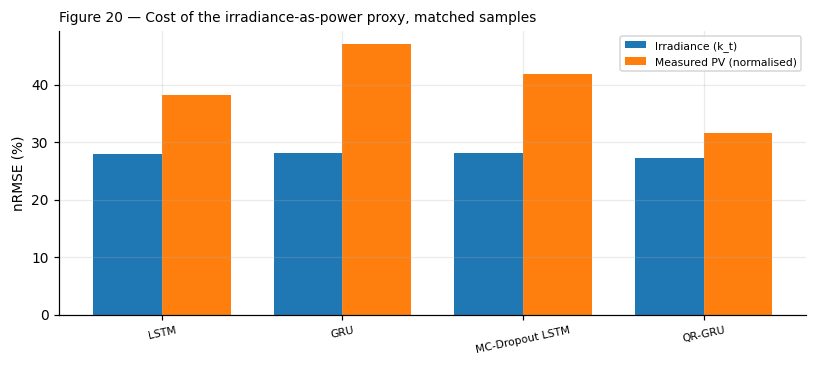

In [ ]:
def build_matched_proxy():
    if "ALICE" not in SITES_OK:
        return None
    d = FEAT[FEAT.site == "ALICE"].copy()
    if d["pv_kw"].notna().sum() < 500:
        return None

    cap = float(np.nanpercentile(d["pv_kw"], 99.5))
    d["pv_norm"] = (d["pv_kw"] / cap).clip(0, 1.2)
    miss = d["pv_norm"].isna() & d["is_daylight"]
    runs = _gap_lengths(miss)
    d["pv_norm"] = np.where(miss & (runs <= CFG.MAX_INTERP_GAP_H),
                            d["pv_norm"].interpolate(limit=CFG.MAX_INTERP_GAP_H,
                                                     limit_area="inside"),
                            d["pv_norm"])
    # INTERSECTION: keep only rows where both targets exist
    both = d["kt"].notna() & d["pv_norm"].notna()
    d = d.loc[both].reset_index(drop=True)
    log(f"matched proxy sample: {len(d):,} hourly rows with BOTH kt and PV present", "ok")
    return d, cap


mp = build_matched_proxy()
PROXY_MATCHED = None
if mp is None:
    log("Alice PV unavailable — matched proxy validation skipped", "warn")
else:
    dmatch, cap = mp
    rows = []
    for target, label in (("kt", "Irradiance (k_t)"), ("pv_norm", "Measured PV (normalised)")):
        built = build_supervised(dmatch, ALL_FEATURES, target=target)
        if built is None:
            continue
        X, y, meta = built
        sp = chrono_split(X, y, meta)
        sc = Standardiser().fit(sp["train"][0])
        Xte_s = sc(sp["test"][0])
        yte_m = sp["test"][1]
        for kind in MODEL_KINDS:
            m, _ = fit_model(kind, sp, sc, tag=f"  [proxy {label}]")
            p, Q, S = predict(kind, m, Xte_s)
            err = p - yte_m
            ss = ((yte_m - yte_m.mean()) ** 2).sum()
            rows.append({
                "target": label, "model": kind, "n_test": len(yte_m),
                "RMSE_norm": float(np.sqrt((err ** 2).mean())),
                "MAE_norm": float(np.abs(err).mean()),
                "nRMSE_%": float(100 * np.sqrt((err ** 2).mean()) / yte_m.mean()),
                "R2": float(1 - (err ** 2).sum() / ss) if ss > 0 else np.nan})
    PROXY_MATCHED = pd.DataFrame(rows)

if PROXY_MATCHED is not None and len(PROXY_MATCHED):
    PROXY_PIV = PROXY_MATCHED.pivot(index="model", columns="target", values="nRMSE_%")
    if PROXY_PIV.shape[1] == 2:
        PROXY_PIV["delta_pp"] = PROXY_PIV.iloc[:, 1] - PROXY_PIV.iloc[:, 0]
    print("PROXY VALIDATION — MATCHED SAMPLE, ALL ARCHITECTURES (Alice Springs)")
    print("=" * 110)
    print(PROXY_MATCHED.round(4).to_string(index=False))
    print("\nnRMSE by target (percentage points):")
    print(PROXY_PIV.round(3).to_string())
    save_table(PROXY_MATCHED, "results_proxy_matched")

    n_same = PROXY_MATCHED.groupby("target")["n_test"].nunique().max()
    print(f"\nSample sizes identical across targets: {n_same == 1}")
    if "delta_pp" in PROXY_PIV:
        print(textwrap.fill(
            f"Mean delta across architectures: {PROXY_PIV['delta_pp'].mean():+.2f} percentage points of "
            f"nRMSE (range {PROXY_PIV['delta_pp'].min():+.2f} to {PROXY_PIV['delta_pp'].max():+.2f}). A positive "
            "delta means measured power is harder to forecast than irradiance on identical hours, "
            "so the Darwin irradiance results should be read as a lower bound on power-forecast "
            "error. Because the delta is now measured on the same timestamps with the same window "
            "construction, it is attributable to the target variable rather than to differing "
            "sample composition.", 100))

    fig, ax = plt.subplots(figsize=(7.5, 3.4))
    order = [k for k in MODEL_KINDS if k in set(PROXY_MATCHED.model)]
    w = 0.38
    for i, t in enumerate(PROXY_MATCHED["target"].unique()):
        v = [PROXY_MATCHED[(PROXY_MATCHED.model == k) &
                           (PROXY_MATCHED.target == t)]["nRMSE_%"].iloc[0] for k in order]
        ax.bar(np.arange(len(order)) + (i - .5) * w, v, w, label=t)
    ax.set_xticks(range(len(order))); ax.set_xticklabels(order, rotation=12, fontsize=7)
    ax.set_ylabel("nRMSE (%)"); ax.legend(fontsize=7)
    ax.set_title("Figure 20 — Cost of the irradiance-as-power proxy, matched samples",
                 fontsize=9, loc="left")
    savefig(fig, "fig20_proxy_matched"); plt.show()

## PART 12 — Cross-climate generalisation

Objective 8. The Darwin-trained models are applied **zero-shot** to every other site that passed
Part 3A (Alice Springs and Singapore in CORE mode; plus Katherine, Tennant Creek, Yulara,
Petrolina, Hong Kong and ESMAP in EXTENDED mode, where present), using the Darwin scaler and the
Darwin feature ordering. No retraining, no
fine-tuning. A locally-fitted persistence baseline accompanies each site so that "the model
transferred badly" can be distinguished from "this site is simply harder".

**v6 note:** in the current Drive data the Singapore arm is NSRDB Himawari PSM v3 (see the change
log); the South Florida NSRDB site is included only if its files are still present.

**Documentation correction worth flagging (v5):** the NSRDB folder is named *US Southwest* and the
proposal calls it a *temperate* benchmark, but the file metadata resolves to 26.06 N, −80.33 W —
South Florida, humid subtropical. The notebook reads latitude, longitude and timezone from the
file's own metadata rather than the folder name, so the analysis is correct either way, but the
proposal and PDM plan should be updated. This is not damaging: Darwin (tropical savanna) →
Singapore (equatorial) → Florida (humid subtropical) → Alice Springs (arid) is a coherent and
defensible four-climate gradient. It is only the *label* that is wrong.


CROSS-CLIMATE GENERALISATION (Objective 8) — all models trained on DARWIN only
     site       transfer               model    n  nRMSE_%  RMSE_Wm2  CRPS_Wm2  PICP_80  MIW_Wm2
   DARWIN local baseline Persistence (local)  535   29.583   129.312    96.283      NaN      NaN
   DARWIN      in-domain                LSTM  535   41.716   182.348   105.781      NaN      NaN
   DARWIN      in-domain                 GRU  535   39.342   171.971   101.562      NaN      NaN
   DARWIN      in-domain     MC-Dropout LSTM  535   33.247   145.326    72.824    0.563  157.439
   DARWIN      in-domain              QR-GRU  535   27.522   120.302    52.365    0.727  210.082
    ALICE local baseline Persistence (local) 2465   26.108   125.621    91.277      NaN      NaN
    ALICE      zero-shot                LSTM 2465   37.629   181.059   130.359      NaN      NaN
    ALICE      zero-shot                 GRU 2465   31.964   153.800   110.347      NaN      NaN
    ALICE      zero-shot     MC-Dropout LSTM 24

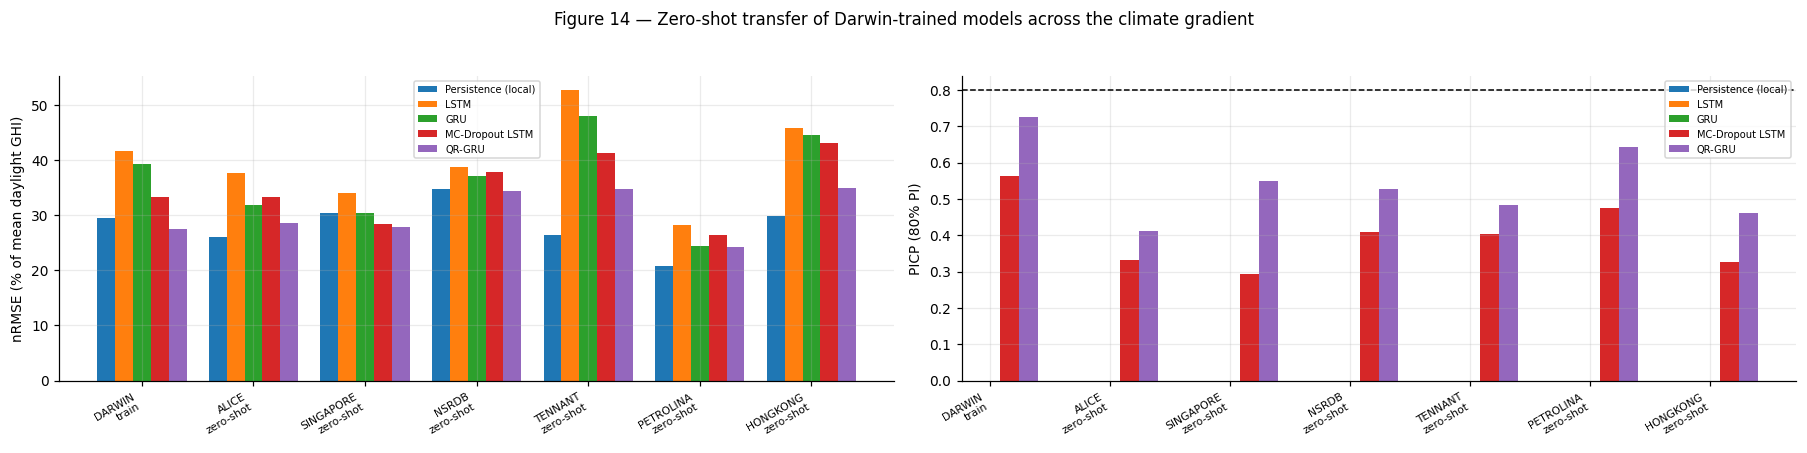

In [ ]:
def run_cross_climate():
    sc = SCALERS[MODEL_SITE]
    rows = []
    for site, split in DATASETS.items():
        Xte, yte, mte = split["test"]
        pk = Xte[:, -1, ALL_FEATURES.index("kt")]
        base = evaluate("Persistence (local)", pk, None, None, yte, mte)
        if base:
            base.update(site=site, transfer="local baseline")
            rows.append(base)
        Xs = sc(Xte)
        for kind in MODEL_KINDS:
            if kind not in MODELS:
                continue
            if site == MODEL_SITE:
                p, Q, S = PREDS[kind][0], PREDS[kind][1], PREDS[kind][2]
            else:
                p, Q, S = predict(kind, MODELS[kind], Xs)
            r = evaluate(kind, p, Q, S, yte, mte)
            if r:
                r.update(site=site,
                         transfer="in-domain" if site == MODEL_SITE else "zero-shot")
                rows.append(r)
    return pd.DataFrame(rows)


CROSS = run_cross_climate()
print("\nCROSS-CLIMATE GENERALISATION (Objective 8) — "
      f"all models trained on {MODEL_SITE} only")
print("=" * 118)
print(CROSS[["site", "transfer", "model", "n", "nRMSE_%", "RMSE_Wm2",
             "CRPS_Wm2", "PICP_80", "MIW_Wm2"]].round(3).to_string(index=False))
save_table(CROSS, "results_cross_climate")

sites_plot = list(DATASETS)
fig, axes = plt.subplots(1, 2, figsize=(max(11.5, 1.5 * len(sites_plot) + 6), 3.9))
kinds_plot = ["Persistence (local)"] + [k for k in MODEL_KINDS if k in MODELS]
w = 0.8 / len(kinds_plot)
for i, kind in enumerate(kinds_plot):
    s = CROSS[CROSS.model == kind].set_index("site").reindex(sites_plot)
    off = (i - (len(kinds_plot) - 1) / 2) * w          # v5 hard-coded (i - 2): centred only for 5 bars
    axes[0].bar(np.arange(len(sites_plot)) + off, s["nRMSE_%"], w, label=kind)
    axes[1].bar(np.arange(len(sites_plot)) + off, s["PICP_80"], w, label=kind)
for ax, yl in ((axes[0], "nRMSE (% of mean daylight GHI)"), (axes[1], "PICP (80% PI)")):
    ax.set_xticks(range(len(sites_plot)))
    ax.set_xticklabels([f"{s}\n{'train' if s == MODEL_SITE else 'zero-shot'}"
                        for s in sites_plot], fontsize=7, rotation=30, ha="right")
    ax.set_ylabel(yl); ax.legend(fontsize=6.5)
axes[1].axhline(.8, color="k", ls="--", lw=1)
fig.suptitle("Figure 14 — Zero-shot transfer of Darwin-trained models across the climate gradient",
             y=1.04)
savefig(fig, "fig14_cross_climate"); plt.show()

---
# PART 12A — Robustness, sensitivity and statistical significance

**What we are analysing.** Whether the headline ranking is real.

**Why it matters — this is the most important addition in the notebook.** Every result reported
so far comes from a *single* training run with a *single* random seed. Neural network training is
stochastic: weight initialisation, dropout masks and mini-batch order all vary. A difference of a
few W/m² between two architectures may be entirely within the noise of re-running the same model.
Without this section, no claim of the form "model A beats model B" is defensible, and an examiner
is entitled to reject the comparison outright.

Four experiments, in order of importance:

1. **Seed replication.** Each architecture is retrained across several seeds. Results are reported
   as mean ± standard deviation, so the reader can see whether the gaps exceed run-to-run noise.
2. **Diebold–Mariano test.** The standard test for comparing forecast accuracy
   (Diebold & Mariano, 1995), with the Harvey–Leybourne–Newbold small-sample correction (1997).
   It tests whether the loss differential between two forecasts has non-zero mean, accounting for
   the serial correlation that makes a naive t-test invalid on time-series errors.
3. **Forecast-horizon sweep.** Skill is measured at t+1 … t+6 h. Persistence decays quickly with
   horizon, so a model that only matches persistence at t+1 may dominate it at t+6 — an
   operationally decisive property that a single-horizon study cannot detect.
4. **Hyperparameter and lookback sensitivity.** Confirms that the architecture ranking is a
   property of the model family rather than of one arbitrary configuration.
5. **Permutation feature importance.** Which inputs the models actually use, measured by the RMSE
   increase when each feature is shuffled across samples at inference time. No retraining, so it
   reflects the fitted models exactly.

**Compute budget.** Controlled by `EXT` below. Enable a GPU runtime
(*Runtime → Change runtime type → GPU*) before running this section; the original CPU run took
over two hours.

[12402.5s |   2200MB] ==> checkpoint build 'results_seed_replication_439c0db529_EXT_sample_L24H1' ...
[12412.2s |   2147MB]  ok   seed 42 | LSTM              RMSE   182.35
[12423.6s |   2182MB]  ok   seed 7 | LSTM              RMSE   169.14
[12431.1s |   2194MB]  ok   seed 2024 | LSTM              RMSE   126.10
[12445.3s |   2178MB]  ok   seed 42 | GRU               RMSE   171.97
[12457.8s |   2186MB]  ok   seed 7 | GRU               RMSE   124.54
[12466.6s |   2198MB]  ok   seed 2024 | GRU               RMSE   116.31
[12485.5s |   2194MB]  ok   seed 42 | MC-Dropout LSTM   RMSE   145.33
[12503.8s |   2208MB]  ok   seed 7 | MC-Dropout LSTM   RMSE   144.26
[12522.1s |   2226MB]  ok   seed 2024 | MC-Dropout LSTM   RMSE   131.32
[12534.7s |   2218MB]  ok   seed 42 | QR-GRU            RMSE   120.30
[12544.1s |   2231MB]  ok   seed 7 | QR-GRU            RMSE   116.30
[12553.9s |   2245MB]  ok   seed 2024 | QR-GRU            RMSE   139.98
[12554.5s |   2245MB]  ok checkpoint saved 'results_se

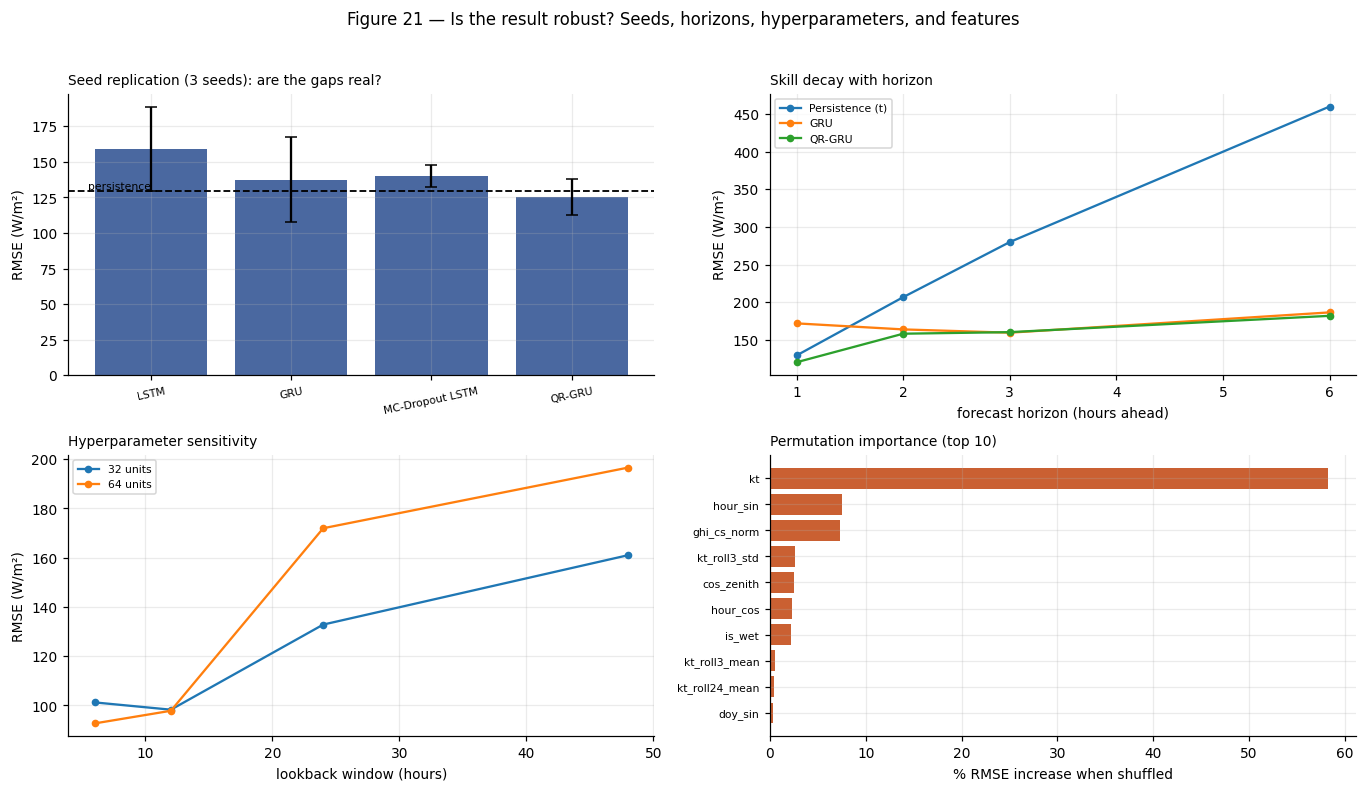

In [ ]:
class EXT:
    SEEDS = [42, 7, 2024]              # seed replication; add more if time allows
    HORIZONS = [1, 2, 3, 6]            # forecast-horizon sweep (hours ahead)
    HORIZON_MODELS = ["GRU", "QR-GRU"] # one deterministic, one probabilistic
    SENS_LOOKBACK = [6, 12, 24, 48]
    SENS_UNITS = [32, 64]
    SENS_MODEL = "GRU"
    PERM_REPEATS = 3


try:
    from scipy import stats as _st

    def _tp(x, df):
        return float(2 * (1 - _st.t.cdf(abs(x), df=df)))
except Exception:                                        # normal approximation fallback
    def _tp(x, df):
        return float(2 * (1 - 0.5 * (1 + math.erf(abs(x) / math.sqrt(2)))))


def diebold_mariano(e1, e2, h=1, power=2):
    """HLN-corrected DM statistic. H0: the two forecasts have equal expected loss."""
    d = np.asarray(e1, float) ** power - np.asarray(e2, float) ** power
    n = len(d)
    if n < 10:
        return np.nan, np.nan
    dbar = d.mean()
    dc = d - dbar
    s = float((dc ** 2).mean())
    for k in range(1, h):                                # Newey-West, h-1 lags
        s += 2.0 * float((dc[k:] * dc[:-k]).mean())
    if s <= 0:
        return np.nan, np.nan
    dm = dbar / math.sqrt(s / n)
    corr = math.sqrt(max((n + 1 - 2 * h + h * (h - 1) / n) / n, 1e-12))
    dm_hln = dm * corr
    return float(dm_hln), _tp(dm_hln, n - 1)


def fit_seeded(kind, split, scaler, seed, tag=""):
    Xtr, ytr, _ = split["train"]
    Xva, yva, _ = split["val"]
    tf.keras.utils.set_random_seed(seed)
    m = build_model(kind, Xtr.shape[-1])
    m.fit(scaler(Xtr), ytr, validation_data=(scaler(Xva), yva),
          epochs=CFG.EPOCHS, batch_size=CFG.BATCH, verbose=0,
          callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=CFG.PATIENCE,
                                                   restore_best_weights=True)])
    return m


# ---------------- 1. seed replication ----------------------------------------
def run_seed_replication():
    sp, sc = DATASETS[MODEL_SITE], SCALERS[MODEL_SITE]
    Xte, yte, mte = sp["test"]
    Xte_s = sc(Xte)
    cs = mte["ghi_cs"].to_numpy()
    rows = []
    for kind in MODEL_KINDS:
        for seed in EXT.SEEDS:
            m = fit_seeded(kind, sp, sc, seed)
            p, Q, S = predict(kind, m, Xte_s)
            r = evaluate(kind, p, Q, S, yte, mte)
            if r:
                r["seed"] = seed
                r["skill_%"] = skill(r["RMSE_Wm2"])
                rows.append(r)
                log(f"  seed {seed} | {kind:<17} RMSE {r['RMSE_Wm2']:8.2f}", "ok")
        gc.collect()
    return pd.DataFrame(rows)


SEEDRUNS = checkpoint(ck("results_seed_replication"), run_seed_replication)

agg = (SEEDRUNS.groupby("model")
       .agg(runs=("RMSE_Wm2", "size"),
            RMSE_mean=("RMSE_Wm2", "mean"), RMSE_sd=("RMSE_Wm2", "std"),
            MAE_mean=("MAE_Wm2", "mean"),
            CRPS_mean=("CRPS_Wm2", "mean"), CRPS_sd=("CRPS_Wm2", "std"),
            PICP_mean=("PICP_80", "mean"), skill_mean=("skill_%", "mean"),
            skill_sd=("skill_%", "std"))
       .reindex([k for k in MODEL_KINDS if k in set(SEEDRUNS.model)])
       .round(3))
print(f"SEED REPLICATION — {len(EXT.SEEDS)} seeds per architecture, {MODEL_SITE} test set")
print("=" * 118)
print(agg.to_string())
save_table(agg.reset_index(), "results_seed_summary")

spread = agg["RMSE_mean"].max() - agg["RMSE_mean"].min()
noise = agg["RMSE_sd"].max()
print(f"\nBetween-architecture RMSE spread : {spread:8.2f} W/m²")
print(f"Largest within-architecture SD   : {noise:8.2f} W/m²")
print(textwrap.fill(
    "If the spread between architectures is not several times the largest within-architecture "
    "standard deviation, the ranking is not separable by seed replication alone and must be "
    "defended with the significance test below rather than by point estimates.", 100))

# ---------------- 2. Diebold-Mariano significance -----------------------------
err_by_model = {}
for kind in [k for k in MODEL_KINDS if k in PREDS]:
    r = RESID[RESID.model == kind].sort_values("ts")
    err_by_model[kind] = r["resid"].to_numpy()
for nm, (pk, yv, mv) in naive_baselines(DATASETS[MODEL_SITE]).items():
    cs = mv["ghi_cs"].to_numpy()
    err_by_model[nm] = np.clip(pk * cs, 0, None) - yv * cs

names = list(err_by_model)
dm_rows = []
for i, a in enumerate(names):
    for b in names[i + 1:]:
        stat, p = diebold_mariano(err_by_model[a], err_by_model[b], h=CFG.HORIZON)
        dm_rows.append({"model_A": a, "model_B": b, "DM_stat": stat, "p_value": p,
                        "better": (a if stat < 0 else b) if np.isfinite(stat) else "n/a",
                        "significant_5%": bool(np.isfinite(p) and p < 0.05)})
DM = pd.DataFrame(dm_rows).round(4)
print("\nDIEBOLD-MARIANO PAIRWISE TESTS (squared-error loss, HLN-corrected)")
print("=" * 118)
print(DM.to_string(index=False))
save_table(DM, "results_diebold_mariano")
print(f"\n{int(DM['significant_5%'].sum())} of {len(DM)} pairwise differences are significant at 5%.")

# ---------------- 3. horizon sweep --------------------------------------------
def run_horizon_sweep():
    rows, orig = [], CFG.HORIZON
    d = FEAT[FEAT.site == MODEL_SITE]
    try:
        for H in EXT.HORIZONS:
            CFG.HORIZON = H
            built = build_supervised(d, ALL_FEATURES)
            if built is None:
                continue
            X, y, meta = built
            sp = chrono_split(X, y, meta)
            sc = Standardiser().fit(sp["train"][0])
            Xte_s, yte, mte = sc(sp["test"][0]), sp["test"][1], sp["test"][2]

            j = ALL_FEATURES.index("kt")
            rp = evaluate("Persistence (t)", sp["test"][0][:, -1, j], None, None, yte, mte)
            if rp:
                rp.update(horizon_h=H)
                rows.append(rp)
            for kind in EXT.HORIZON_MODELS:
                m = fit_seeded(kind, sp, sc, CFG.SEED)
                p, Q, S = predict(kind, m, Xte_s)
                r = evaluate(kind, p, Q, S, yte, mte)
                if r:
                    r.update(horizon_h=H)
                    rows.append(r)
            log(f"  horizon t+{H}h complete ({len(yte):,} test windows)", "ok")
            gc.collect()
    finally:
        CFG.HORIZON = orig
    return pd.DataFrame(rows)


HORIZON = checkpoint(ck("results_horizon_sweep"), run_horizon_sweep)
if len(HORIZON):
    hp = HORIZON.pivot_table(index="horizon_h", columns="model", values="RMSE_Wm2")
    print("\nFORECAST-HORIZON SWEEP — RMSE (W/m²)")
    print(hp.round(2).to_string())
    if "Persistence (t)" in hp.columns:
        sk = 100 * (1 - hp.div(hp["Persistence (t)"], axis=0)).drop(columns=["Persistence (t)"])
        print("\nSkill score vs persistence at each horizon (%)")
        print(sk.round(2).to_string())
    save_table(HORIZON, "results_horizon_sweep_tbl")

# ---------------- 4. hyperparameter / lookback sensitivity --------------------
def run_sensitivity():
    rows, oL, oU = [], CFG.LOOKBACK, CFG.UNITS
    d = FEAT[FEAT.site == MODEL_SITE]
    try:
        for L in EXT.SENS_LOOKBACK:
            for U in EXT.SENS_UNITS:
                CFG.LOOKBACK, CFG.UNITS = L, U
                built = build_supervised(d, ALL_FEATURES)
                if built is None:
                    continue
                X, y, meta = built
                sp = chrono_split(X, y, meta)
                sc = Standardiser().fit(sp["train"][0])
                m = fit_seeded(EXT.SENS_MODEL, sp, sc, CFG.SEED)
                p, Q, S = predict(EXT.SENS_MODEL, m, sc(sp["test"][0]))
                r = evaluate(EXT.SENS_MODEL, p, Q, S, sp["test"][1], sp["test"][2])
                if r:
                    r.update(lookback_h=L, units=U)
                    rows.append(r)
                    log(f"  lookback={L}h units={U} -> RMSE {r['RMSE_Wm2']:.2f}", "ok")
                gc.collect()
    finally:
        CFG.LOOKBACK, CFG.UNITS = oL, oU
    return pd.DataFrame(rows)


SENS = checkpoint(ck("results_sensitivity"), run_sensitivity)
if len(SENS):
    sp_tab = SENS.pivot_table(index="lookback_h", columns="units", values="RMSE_Wm2")
    print(f"\nHYPERPARAMETER SENSITIVITY — {EXT.SENS_MODEL}, RMSE (W/m²)")
    print(sp_tab.round(2).to_string())
    rng = SENS["RMSE_Wm2"].max() - SENS["RMSE_Wm2"].min()
    print(f"Range across {len(SENS)} configurations: {rng:.2f} W/m²")
    save_table(SENS, "results_sensitivity_tbl")

# ---------------- 5. permutation feature importance ---------------------------
def permutation_importance():
    sp, sc = DATASETS[MODEL_SITE], SCALERS[MODEL_SITE]
    Xte, yte, mte = sp["test"]
    cs = mte["ghi_cs"].to_numpy()
    rng = np.random.default_rng(CFG.SEED)
    rows = []
    for kind in [k for k in MODEL_KINDS if k in MODELS]:
        base_p, _, _ = predict(kind, MODELS[kind], sc(Xte))
        base = float(np.sqrt((((np.clip(base_p * cs, 0, None)) - yte * cs) ** 2).mean()))
        for j, feat in enumerate(ALL_FEATURES):
            hits = []
            for _ in range(EXT.PERM_REPEATS):
                Xp = Xte.copy()
                Xp[:, :, j] = Xp[rng.permutation(len(Xp)), :, j]
                p, _, _ = predict(kind, MODELS[kind], sc(Xp))
                hits.append(float(np.sqrt((((np.clip(p * cs, 0, None)) - yte * cs) ** 2).mean())))
            rows.append({"model": kind, "feature": feat, "base_RMSE": base,
                         "perm_RMSE": float(np.mean(hits)),
                         "delta_RMSE": float(np.mean(hits) - base),
                         "delta_%": float(100 * (np.mean(hits) - base) / base)})
    return pd.DataFrame(rows)


PERM = checkpoint(ck("results_permutation_importance"), permutation_importance)
top = (PERM.groupby("feature")["delta_%"].mean().sort_values(ascending=False))
print("\nPERMUTATION FEATURE IMPORTANCE (mean % RMSE increase when shuffled, all models)")
print(top.round(2).to_string())

# ---------------- Figure 21 ---------------------------------------------------
fig, axes = plt.subplots(2, 2, figsize=(12.5, 7))
ax = axes[0, 0]
order = [k for k in MODEL_KINDS if k in agg.index]
ax.bar(range(len(order)), agg.loc[order, "RMSE_mean"],
       yerr=agg.loc[order, "RMSE_sd"].fillna(0), capsize=4, color="#2a4d8f", alpha=.85)
if "Persistence (t)" in set(BASELINES.model):
    ax.axhline(REF_RMSE, color="k", ls="--", lw=1.2)
    ax.text(-.45, REF_RMSE * 1.01, "persistence", fontsize=7)
ax.set_xticks(range(len(order))); ax.set_xticklabels(order, rotation=12, fontsize=7)
ax.set_ylabel("RMSE (W/m²)")
ax.set_title(f"Seed replication ({len(EXT.SEEDS)} seeds): are the gaps real?", fontsize=9, loc="left")

ax = axes[0, 1]
if len(HORIZON):
    for kind in HORIZON["model"].unique():
        s = HORIZON[HORIZON.model == kind].sort_values("horizon_h")
        ax.plot(s["horizon_h"], s["RMSE_Wm2"], "-o", ms=4, label=kind)
    ax.set_xlabel("forecast horizon (hours ahead)"); ax.set_ylabel("RMSE (W/m²)")
    ax.legend(fontsize=7)
ax.set_title("Skill decay with horizon", fontsize=9, loc="left")

ax = axes[1, 0]
if len(SENS):
    for U in sorted(SENS["units"].unique()):
        s = SENS[SENS.units == U].sort_values("lookback_h")
        ax.plot(s["lookback_h"], s["RMSE_Wm2"], "-o", ms=4, label=f"{U} units")
    ax.set_xlabel("lookback window (hours)"); ax.set_ylabel("RMSE (W/m²)"); ax.legend(fontsize=7)
ax.set_title("Hyperparameter sensitivity", fontsize=9, loc="left")

ax = axes[1, 1]
tt = top.head(10)[::-1]
ax.barh(range(len(tt)), tt.to_numpy(), color="#c1440e", alpha=.85)
ax.set_yticks(range(len(tt))); ax.set_yticklabels(tt.index, fontsize=7)
ax.set_xlabel("% RMSE increase when shuffled")
ax.set_title("Permutation importance (top 10)", fontsize=9, loc="left")
fig.suptitle("Figure 21 — Is the result robust? Seeds, horizons, hyperparameters, and features",
             y=1.02)
savefig(fig, "fig21_robustness"); plt.show()

## PART 13 — Decision-support translation

Objective 4. A prediction interval is only useful if it can be turned into an operating rule. The
test set is partitioned into quintiles of predicted interval width (MIW); for each band the
realised coverage and the realised error are measured. The result is a lookup table a dispatcher
can act on: *when the model's own interval is narrow, is it actually reliable?*

The threshold is chosen as the widest MIW band that still achieves empirical coverage at or above
nominal — i.e. the widest band in which the model's confidence is honest.


DECISION-SUPPORT TABLE (Objective 4) — DARWIN, t+1h, nominal 80% interval
band   n  MIW_lo  MIW_hi  MIW_mean  PICP     MAE    RMSE  ramp_rate                           dispatch_rule
  Q1 107   4.226  53.012    29.332 0.720  13.533  28.987      0.019 COMMIT reserve — coverage below nominal
  Q2 107  53.321 131.724    91.769 0.794  33.741  59.029      0.280 COMMIT reserve — coverage below nominal
  Q3 107 131.804 211.579   166.992 0.729  58.858  75.965      0.271 COMMIT reserve — coverage below nominal
  Q4 107 212.616 349.649   270.959 0.720 101.879 129.832      0.150 COMMIT reserve — coverage below nominal
  Q5 107 349.964 726.481   491.361 0.673 172.980 213.099      0.103 COMMIT reserve — coverage below nominal

  No MIW band reached nominal coverage from the narrow end — the model is overconfident even when it claims precision, and must be recalibrated (e.g. conformal adjustment) before any operational use.


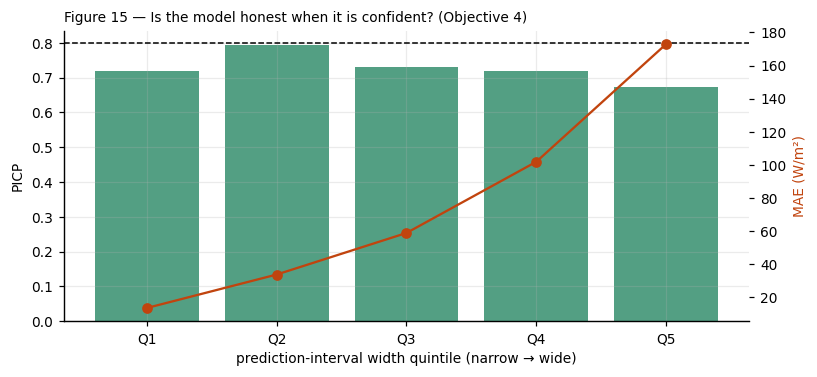

In [ ]:
def decision_support(kind="QR-GRU"):
    if kind not in PREDS:
        return None
    point, Q, S, yte, mte = PREDS[kind]
    cs = mte["ghi_cs"].to_numpy()
    lo = np.clip(Q[:, CFG.QUANTILES.index(CFG.PI_LOW)] * cs, 0, None)
    hi = np.clip(Q[:, CFG.QUANTILES.index(CFG.PI_HIGH)] * cs, 0, None)
    yt = yte * cs
    yh = np.clip(point * cs, 0, None)
    miw = hi - lo

    codes = pd.qcut(miw, 5, labels=False, duplicates="drop")
    band = pd.Series(codes).map(lambda i: f"Q{int(i)+1}" if pd.notna(i) else "Q1")
    df = pd.DataFrame({"band": band, "miw": miw, "cov": (yt >= lo) & (yt <= hi),
                       "abserr": np.abs(yh - yt), "sqerr": (yh - yt) ** 2,
                       "ramp": mte["is_ramp"].to_numpy().astype(bool)})
    g = df.groupby("band", observed=True).agg(
        n=("miw", "size"), MIW_lo=("miw", "min"), MIW_hi=("miw", "max"),
        MIW_mean=("miw", "mean"), PICP=("cov", "mean"),
        MAE=("abserr", "mean"), RMSE=("sqerr", lambda s: np.sqrt(s.mean())),
        ramp_rate=("ramp", "mean")).reset_index()
    g["dispatch_rule"] = np.where(
        (g.PICP >= CFG.PI_HIGH - CFG.PI_LOW) & (g.MIW_mean <= np.median(miw)),
        "DEFER backup — interval narrow AND honest",
        np.where(g.PICP >= CFG.PI_HIGH - CFG.PI_LOW,
                 "HOLD reserve — honest but wide",
                 "COMMIT reserve — coverage below nominal"))
    return g, miw, yt, lo, hi


ds = decision_support("QR-GRU") or decision_support("MC-Dropout LSTM")
if ds:
    DECISION, miw, yt, lo, hi = ds
    print("\nDECISION-SUPPORT TABLE (Objective 4) — "
          f"{MODEL_SITE}, t+{CFG.HORIZON}h, nominal 80% interval")
    print("=" * 118)
    print(DECISION.round(3).to_string(index=False))
    # The rule must describe a CONTIGUOUS run from the narrowest band upward.
    # Taking the widest passing band would assert reliability across intermediate
    # bands that failed, which is exactly the kind of overclaim the objective warns about.
    nominal = CFG.PI_HIGH - CFG.PI_LOW
    run = []
    for _, r in DECISION.iterrows():
        if r.PICP >= nominal:
            run.append(r)
        else:
            break
    if run:
        run = pd.DataFrame(run)
        thr = run.MIW_hi.max()
        print(f"\n  OPERATING RULE: while the forecast 80% interval width is <= "
              f"{thr:,.0f} W/m² ({len(run)} of {len(DECISION)} width bands, "
              f"{int(run.n.sum()):,} test hours), empirical coverage holds at or above "
              f"nominal 80% (min {run.PICP.min():.3f}) and mean absolute error stays within "
              f"{run.MAE.min():,.0f}-{run.MAE.max():,.0f} W/m². Backup generation can be "
              f"deferred within that band at t+{CFG.HORIZON}h.")
        fails = DECISION[DECISION.PICP < nominal]
        if len(fails):
            print(f"  CAVEAT: coverage falls below nominal in band(s) "
                  f"{', '.join(fails.band)} (PICP {fails.PICP.min():.3f}); the model is "
                  f"overconfident at those widths and reserve should be committed.")
    else:
        print("\n  No MIW band reached nominal coverage from the narrow end — the model is "
              "overconfident even when it claims precision, and must be recalibrated "
              "(e.g. conformal adjustment) before any operational use.")
    save_table(DECISION, "results_decision_support")

    fig, ax = plt.subplots(figsize=(7.5, 3.5))
    ax.bar(DECISION.band, DECISION.PICP, color="#1a7f5a", alpha=.75, label="PICP")
    ax.axhline(.8, color="k", ls="--", lw=1); ax.set_ylabel("PICP")
    ax2 = ax.twinx(); ax2.grid(False)
    ax2.plot(DECISION.band, DECISION.MAE, "o-", color="#c1440e", label="MAE")
    ax2.set_ylabel("MAE (W/m²)", color="#c1440e")
    ax.set_xlabel("prediction-interval width quintile (narrow → wide)")
    ax.set_title("Figure 15 — Is the model honest when it is confident? (Objective 4)",
                 loc="left", fontsize=9)
    savefig(fig, "fig15_decision"); plt.show()

---
# PART 13A — Implications for grid integration: reserve sizing

**What we are analysing.** How much operating reserve each forecasting approach implies, and how
often that reserve would have been insufficient.

**Why it matters.** Objective 4 asks for decision-support translation. Part 13 produced a
threshold table, but a threshold is not yet a quantity a planner can budget. The operationally
meaningful question is: *for a given tolerated shortfall frequency, how much reserve must be
carried?* A probabilistic forecast should require **less** reserve than a deterministic one at the
same reliability, because it can widen the margin only when conditions warrant instead of carrying
a constant worst-case buffer.

**Method, and the leakage guard.** The deterministic strategy carries a constant margin equal to a
fixed quantile of its own historical error — and that quantile is estimated on the **validation**
split, never the test split. The probabilistic strategy carries the model's own forecast-specific
upward margin (`q90 − median`, optionally conformal-corrected). Both are then scored on the test
set by two numbers: mean reserve carried (W/m², the cost) and the exceedance rate (fraction of
hours where the actual shortfall exceeded the reserve, the risk). Sweeping the deterministic
quantile traces a cost–risk frontier; the probabilistic strategy is a single point that either
sits below that frontier or does not.

**Units caveat.** Darwin has no measured PV, so reserve is expressed per unit of irradiance
(W/m²). Converting to MW requires an installed capacity and a module efficiency, which this
dataset does not supply; the Alice Springs PV file would permit that conversion and is identified
in the limitations as the data required to do so.

RESERVE SIZING — DARWIN, t+1h, model: QR-GRU
                              strategy  mean_reserve_Wm2  exceedance_%  unserved_Wm2_per_h
Deterministic + fixed margin (val q50)             0.000        48.037              22.566
Deterministic + fixed margin (val q75)            69.925        11.402               6.170
Deterministic + fixed margin (val q80)            83.543         9.346               4.770
Deterministic + fixed margin (val q90)           125.158         4.112               2.093
Deterministic + fixed margin (val q95)           195.660         1.121               0.374
Deterministic + fixed margin (val q97)           234.964         0.561               0.055
Deterministic + fixed margin (val q99)           276.526         0.000               0.000
        Probabilistic q90 margin (raw)            98.099        10.841               2.181
  Probabilistic q90 margin (conformal)           130.156         3.925               0.678


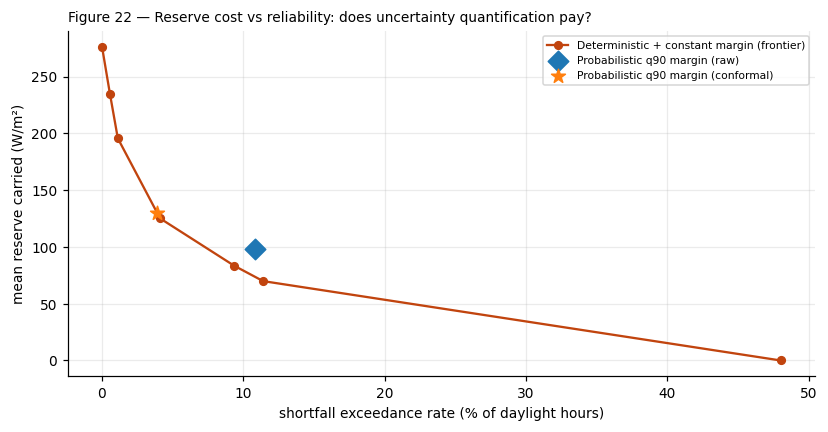


  Probabilistic q90 margin (raw): at a comparable exceedance rate (10.8% vs 11.4%), reserve is +40.3% relative to the deterministic strategy.

  Probabilistic q90 margin (conformal): at a comparable exceedance rate (3.9% vs 4.1%), reserve is +4.0% relative to the deterministic strategy.
A point lying below and to the left of the deterministic frontier means the probabilistic forecast
delivers the same reliability for less carried reserve, which is the operational argument for
uncertainty quantification stated in physical units rather than in scoring rules. A point above the
frontier means the opposite, and would be an equally reportable negative finding.


In [ ]:
def reserve_analysis(kind=None):
    kind = kind or best_prob
    if kind not in PREDS or kind not in MODELS:
        return None
    sp, sc = DATASETS[MODEL_SITE], SCALERS[MODEL_SITE]

    # deterministic margins calibrated on VALIDATION only
    Xv, yv, mv = sp["val"]
    pv, _, _ = predict(kind, MODELS[kind], sc(Xv))
    csv_ = mv["ghi_cs"].to_numpy()
    shortfall_val = np.clip(yv * csv_ - np.clip(pv * csv_, 0, None), 0, None)

    point, Q, S, yte, mte = PREDS[kind]
    cs = mte["ghi_cs"].to_numpy()
    yhat = np.clip(point * cs, 0, None)
    ytrue = yte * cs
    shortfall = np.clip(ytrue - yhat, 0, None)

    rows = []
    for q in (0.50, 0.75, 0.80, 0.90, 0.95, 0.975, 0.99):
        margin = float(np.quantile(shortfall_val, q))
        rows.append({"strategy": f"Deterministic + fixed margin (val q{int(q*100)})",
                     "mean_reserve_Wm2": margin,
                     "exceedance_%": float(100 * (shortfall > margin).mean()),
                     "unserved_Wm2_per_h": float(np.clip(shortfall - margin, 0, None).mean())})

    delta = CONFORMAL.get(kind) or 0.0
    for tag, dd in (("raw", 0.0), ("conformal", delta)):
        upper = np.clip((Q[:, I_HI] + dd) * cs, 0, None)
        margin = np.clip(upper - yhat, 0, None)
        rows.append({"strategy": f"Probabilistic q90 margin ({tag})",
                     "mean_reserve_Wm2": float(margin.mean()),
                     "exceedance_%": float(100 * (shortfall > margin).mean()),
                     "unserved_Wm2_per_h": float(np.clip(shortfall - margin, 0, None).mean())})
    return pd.DataFrame(rows).round(3), kind


ra = reserve_analysis()
if ra:
    RESERVE, res_kind = ra
    print(f"RESERVE SIZING — {MODEL_SITE}, t+{CFG.HORIZON}h, model: {res_kind}")
    print("=" * 110)
    print(RESERVE.to_string(index=False))
    save_table(RESERVE, "results_reserve_sizing")

    det = RESERVE[RESERVE.strategy.str.startswith("Deterministic")]
    prob = RESERVE[RESERVE.strategy.str.startswith("Probabilistic")]

    fig, ax = plt.subplots(figsize=(7.6, 4.0))
    ax.plot(det["exceedance_%"], det["mean_reserve_Wm2"], "-o", ms=5, color="#c1440e",
            label="Deterministic + constant margin (frontier)")
    for _, r in prob.iterrows():
        ax.scatter(r["exceedance_%"], r["mean_reserve_Wm2"], s=90, zorder=5,
                   marker="*" if "conformal" in r.strategy else "D",
                   label=r["strategy"])
    ax.set_xlabel("shortfall exceedance rate (% of daylight hours)")
    ax.set_ylabel("mean reserve carried (W/m²)")
    ax.legend(fontsize=7)
    ax.set_title("Figure 22 — Reserve cost vs reliability: does uncertainty quantification pay?",
                 fontsize=9, loc="left")
    savefig(fig, "fig22_reserve"); plt.show()

    for _, r in prob.iterrows():
        near = det.iloc[(det["exceedance_%"] - r["exceedance_%"]).abs().argsort()[:1]]
        if len(near):
            n0 = near.iloc[0]
            base_res = n0["mean_reserve_Wm2"]
            if base_res > 1e-6:
                diff = 100 * (r["mean_reserve_Wm2"] - base_res) / base_res
                print(f"\n  {r['strategy']}: at a comparable exceedance rate "
                      f"({r['exceedance_%']:.1f}% vs {n0['exceedance_%']:.1f}%), reserve is "
                      f"{diff:+.1f}% relative to the deterministic strategy.")
            else:
                print(f"\n  {r['strategy']}: nearest deterministic point carries no reserve "
                      f"({n0['exceedance_%']:.1f}% exceedance); ratio undefined, compare "
                      f"Figure 22 directly.")
    print(textwrap.fill(
        "A point lying below and to the left of the deterministic frontier means the probabilistic "
        "forecast delivers the same reliability for less carried reserve, which is the operational "
        "argument for uncertainty quantification stated in physical units rather than in scoring "
        "rules. A point above the frontier means the opposite, and would be an equally reportable "
        "negative finding.", 100))

## PART 14 — Consolidated findings

Everything below is generated from the results computed above — no hard-coded numbers.

In [ ]:
def fmt(x, n=2):
    return "n/a" if x is None or (isinstance(x, float) and not np.isfinite(x)) else f"{x:,.{n}f}"


main = RESULTS_MAIN.set_index("model")
det = [k for k in MODEL_KINDS if k not in PROBABILISTIC and k in main.index]
prob = [k for k in MODEL_KINDS if k in PROBABILISTIC and k in main.index]

best_point = main.loc[det + prob, "RMSE_Wm2"].idxmin()
best_crps = main.loc[det + prob, "CRPS_Wm2"].idxmin()
best_cal = (main.loc[prob, "PICP_80"] - 0.80).abs().idxmin() if prob else None

lines = []
lines.append(f"PRIMARY SITE            : {MODEL_SITE} — {SITES[MODEL_SITE]['climate']}")
lines.append(f"TASK                    : t+{CFG.HORIZON}h clear-sky-index forecast, "
             f"{CFG.LOOKBACK}h lookback, daylight hours only")
lines.append(f"TEST WINDOWS            : {int(main['n'].max()):,}")
lines.append("")
lines.append(f"O1 best point accuracy  : {best_point}  "
             f"(RMSE {fmt(main.loc[best_point,'RMSE_Wm2'])} W/m², "
             f"nRMSE {fmt(main.loc[best_point,'nRMSE_%'])}%, "
             f"R² {fmt(main.loc[best_point,'R2'],3)})")
if "Persistence (baseline)" in main.index:
    pb = main.loc["Persistence (baseline)", "RMSE_Wm2"]
    lines.append(f"     vs persistence     : "
                 f"{100*(pb-main.loc[best_point,'RMSE_Wm2'])/pb:+.1f}% RMSE skill")
lines.append(f"O2 best CRPS            : {best_crps} ({fmt(main.loc[best_crps,'CRPS_Wm2'])} W/m²)")
if best_cal:
    lines.append(f"O2 best calibrated      : {best_cal} "
                 f"(PICP80 {fmt(main.loc[best_cal,'PICP_80'],3)} vs 0.800 nominal, "
                 f"MIW {fmt(main.loc[best_cal,'MIW_Wm2'])} W/m²)")
    d_rmse = 100*(main.loc[prob,'RMSE_Wm2'].min() - main.loc[det,'RMSE_Wm2'].min())/main.loc[det,'RMSE_Wm2'].min()
    lines.append(f"O2 accuracy cost of UQ  : {d_rmse:+.1f}% RMSE for the best probabilistic "
                 f"model relative to the best deterministic one")
try:
    imp = ABLATION_PIV[("RMSE_Wm2", "Δ improvement %")]      # v5 read `piv` (overwritten in 11A)
    lines.append(f"O3 seasonal conditioning: mean RMSE improvement {imp.mean():+.2f}% "
                 f"(range {imp.min():+.2f}% to {imp.max():+.2f}%)")
except Exception:
    pass
if len(SUBGROUP):
    rr = SUBGROUP[SUBGROUP.subgroup == "ramp events"]
    aa = SUBGROUP[SUBGROUP.subgroup == "all daylight"]
    if len(rr) and len(aa):
        lines.append(f"O3 ramp-event penalty   : RMSE rises "
                     f"{100*(rr.RMSE_Wm2.mean()-aa.RMSE_Wm2.mean())/aa.RMSE_Wm2.mean():+.0f}% "
                     f"on ramp hours across all architectures")
if PROXY is not None and len(PROXY) == 2:
    lines.append(f"O1 proxy validation     : static GHI→PV R² = {fmt(PROXY_R2,4)}; "
                 f"forecast nRMSE delta {PROXY.iloc[1]['nRMSE_%']-PROXY.iloc[0]['nRMSE_%']:+.2f} pp")
zs = CROSS[(CROSS.transfer == "zero-shot")]
if len(zs):
    for s in zs.site.unique():
        sub = zs[zs.site == s]
        b = sub.loc[sub["nRMSE_%"].idxmin()]
        lines.append(f"O8 zero-shot -> {s:<10}: best {b.model} at nRMSE {fmt(b['nRMSE_%'])}%")
lines.append("")
lines.append(f"DATA FINGERPRINT        : {DATA_FP}   site set {CFG.SITE_SET}, geometry {CFG.GEOMETRY_TIMING}")
for s in SITES_OK:
    lines.append(f"SOURCE {s:<17}: {SOURCE_USED.get(s, '?')}")
if len(FAILED):
    lines.append(f"EXCLUDED AT VALIDATION  : {', '.join(f'{r.site} ({r.issues})' for _, r in FAILED.iterrows())}")
lines.append(f"FILES RETAINED          : {int(kept.n_files.sum())} "
             f"({kept.size_mb.sum():,.0f} MB)")
lines.append(f"FILES EXCLUDED          : {int(dropped.n_files.sum())} "
             f"({dropped.size_mb.sum():,.0f} MB) — see Part 1 for per-file justification")

print("=" * 100)
print("CONSOLIDATED FINDINGS")
print("=" * 100)
print("\n".join(lines))
print("=" * 100)

SUMMARY = pd.DataFrame({"finding": lines})
save_table(SUMMARY, "consolidated_findings")

# ---- single export bundle for the write-up -----------------------------------
bundle = {
    "audit_manifest": AUDIT.drop(columns=["_paths"]),
    "raw_inventory": RAW_INVENTORY.astype(str),
    "data_validation": VALIDATION.assign(first=VALIDATION["first"].astype(str),
                                         last=VALIDATION["last"].astype(str)),
    "leakage_diagnostic": LEAKAGE_DIAG,
    "unit_registry": UNIT_REGISTRY,
    "ingestion_ledger": LEDGER,
    "impute_ledger": IMPUTE_LEDGER,
    "results_main": RESULTS_MAIN,
    "results_ablation": ABLATION,
    "results_subgroup": SUBGROUP,
    "results_cross_climate": CROSS,
}
if PROXY is not None:
    bundle["results_proxy"] = PROXY
if ds:
    bundle["results_decision_support"] = DECISION

xl = ART / "TropicalPV_results.xlsx"
try:
    with pd.ExcelWriter(xl) as w:
        for k, v in bundle.items():
            v.to_excel(w, sheet_name=k[:31], index=False)
    log(f"results workbook written: {xl}", "ok")
except Exception as e:
    for k, v in bundle.items():
        v.to_csv(ART / f"{k}.csv", index=False)
    log(f"Excel unavailable ({e}); wrote individual CSVs to {ART}", "warn")

print(f"\nFigures : {FIGDIR}")
print(f"Tables  : {ART}")
print(f"Total runtime: {time.time()-_T0:.0f}s   peak-ish RSS: {mem_mb():,.0f} MB")

CONSOLIDATED FINDINGS
PRIMARY SITE            : DARWIN — Tropical savanna (Köppen Aw)
TASK                    : t+1h clear-sky-index forecast, 24h lookback, daylight hours only
TEST WINDOWS            : 535

O1 best point accuracy  : QR-GRU  (RMSE 120.30 W/m², nRMSE 27.52%, R² 0.838)
     vs persistence     : +7.0% RMSE skill
O2 best CRPS            : QR-GRU (52.36 W/m²)
O2 best calibrated      : QR-GRU (PICP80 0.727 vs 0.800 nominal, MIW 210.08 W/m²)
O2 accuracy cost of UQ  : -30.0% RMSE for the best probabilistic model relative to the best deterministic one
O3 seasonal conditioning: mean RMSE improvement +2.73% (range -6.48% to +8.52%)
O3 ramp-event penalty   : RMSE rises +0% on ramp hours across all architectures
O1 proxy validation     : static GHI→PV R² = 0.6916; forecast nRMSE delta +17.32 pp
O8 zero-shot -> ALICE     : best QR-GRU at nRMSE 28.58%
O8 zero-shot -> SINGAPORE : best QR-GRU at nRMSE 27.94%
O8 zero-shot -> NSRDB     : best QR-GRU at nRMSE 34.47%
O8 zero-shot -> TENNAN

---
# PART 14A — Comprehensive model comparison

A single leaderboard expressing every model on common terms: point accuracy as skill against
persistence, probabilistic quality as CRPS, calibration as absolute deviation of PICP from
nominal, and robustness as the standard deviation across seeds. No model can win on one metric
alone, which is the point.

COMPREHENSIVE LEADERBOARD — seed-averaged where applicable
                     model         family  RMSE_Wm2  skill_vs_persistence_%  CRPS_Wm2  PICP_80  calib_error  RMSE_sd_seeds
                    QR-GRU  probabilistic   125.527                   2.927    54.272    0.742        0.058         12.673
           Persistence (t) naive baseline   129.312                   0.000    96.283      NaN          NaN            NaN
                       GRU  deterministic   137.607                  -6.415    86.106      NaN          NaN         30.043
           MC-Dropout LSTM  probabilistic   140.300                  -8.497    70.454    0.581        0.219          7.798
                      LSTM  deterministic   159.197                 -23.111    96.398      NaN          NaN         29.414
    Seasonal-naive (t-24h) naive baseline   186.952                 -44.575   113.233      NaN          NaN            NaN
Climatology (month x hour) naive baseline   205.902                 -59.229   12

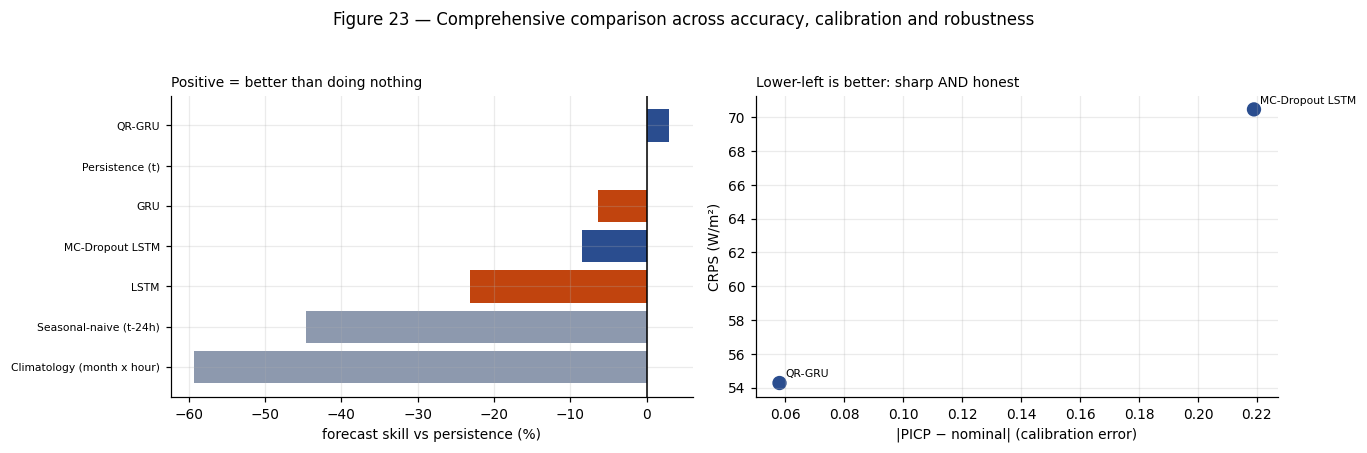

In [ ]:
lb = []
for nm in BASELINES["model"]:
    r = BASELINES.set_index("model").loc[nm]
    lb.append({"model": nm, "family": "naive baseline",
               "RMSE_Wm2": r["RMSE_Wm2"], "skill_vs_persistence_%": skill(r["RMSE_Wm2"]),
               "CRPS_Wm2": r["CRPS_Wm2"], "PICP_80": np.nan,
               "calib_error": np.nan, "RMSE_sd_seeds": np.nan})
for kind in [k for k in MODEL_KINDS if k in agg.index]:
    a = agg.loc[kind]
    picp = a["PICP_mean"]
    lb.append({"model": kind,
               "family": "probabilistic" if kind in PROBABILISTIC else "deterministic",
               "RMSE_Wm2": a["RMSE_mean"], "skill_vs_persistence_%": a["skill_mean"],
               "CRPS_Wm2": a["CRPS_mean"], "PICP_80": picp,
               "calib_error": abs(picp - COVERAGE) if np.isfinite(picp) else np.nan,
               "RMSE_sd_seeds": a["RMSE_sd"]})
LEADERBOARD = pd.DataFrame(lb).sort_values("RMSE_Wm2").round(3)
print("COMPREHENSIVE LEADERBOARD — seed-averaged where applicable")
print("=" * 118)
print(LEADERBOARD.to_string(index=False))
save_table(LEADERBOARD, "results_leaderboard")

fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.9))
col = {"naive baseline": "#8d99ae", "deterministic": "#c1440e", "probabilistic": "#2a4d8f"}
L = LEADERBOARD.sort_values("skill_vs_persistence_%")
axes[0].barh(range(len(L)), L["skill_vs_persistence_%"],
             color=[col[f] for f in L["family"]])
axes[0].axvline(0, color="k", lw=1)
axes[0].set_yticks(range(len(L))); axes[0].set_yticklabels(L["model"], fontsize=7)
axes[0].set_xlabel("forecast skill vs persistence (%)")
axes[0].set_title("Positive = better than doing nothing", fontsize=9, loc="left")

P = LEADERBOARD.dropna(subset=["PICP_80"])
if len(P):
    axes[1].scatter(P["calib_error"], P["CRPS_Wm2"], s=70,
                    c=[col[f] for f in P["family"]])
    for _, r in P.iterrows():
        axes[1].annotate(r["model"], (r["calib_error"], r["CRPS_Wm2"]),
                         fontsize=7, xytext=(4, 4), textcoords="offset points")
    axes[1].set_xlabel("|PICP − nominal| (calibration error)")
    axes[1].set_ylabel("CRPS (W/m²)")
    axes[1].set_title("Lower-left is better: sharp AND honest", fontsize=9, loc="left")
fig.suptitle("Figure 23 — Comprehensive comparison across accuracy, calibration and robustness",
             y=1.04)
savefig(fig, "fig23_leaderboard"); plt.show()

---
# PART 14B — Consolidated findings from the extended analysis

Generated from the results computed above. No hard-coded numbers.

In [ ]:
lines2 = []
b = LEADERBOARD[LEADERBOARD.family != "naive baseline"]
if len(b):
    bp = b.loc[b["RMSE_Wm2"].idxmin()]
    lines2.append(f"Best model (seed-averaged) : {bp['model']} — RMSE {bp['RMSE_Wm2']:.2f} W/m², "
                  f"skill vs persistence {bp['skill_vs_persistence_%']:+.1f}%")
    beat = b[b["skill_vs_persistence_%"] > 0]
    lines2.append(f"Models beating persistence : {len(beat)} of {len(b)} "
                  f"({', '.join(beat['model']) if len(beat) else 'none'})")
if len(DM):
    sig = DM[DM["significant_5%"]]
    lines2.append(f"DM significance            : {len(sig)}/{len(DM)} pairwise differences "
                  f"significant at 5%")
if len(agg):
    lines2.append(f"Seed stability             : largest within-model RMSE SD "
                  f"{agg['RMSE_sd'].max():.2f} W/m² vs between-model spread "
                  f"{agg['RMSE_mean'].max()-agg['RMSE_mean'].min():.2f} W/m²")
if len(CALIB):
    for kind in CALIB["model"].unique():
        raw = CALIB[(CALIB.model == kind) & (CALIB.intervals == "raw")].iloc[0]
        con = CALIB[(CALIB.model == kind) & (CALIB.intervals == "conformal")].iloc[0]
        lines2.append(f"Conformal repair {kind:<17}: PICP {raw['PICP_80']:.3f} -> "
                      f"{con['PICP_80']:.3f} (nominal {COVERAGE:.2f}), "
                      f"MIW {raw['MIW_Wm2']:.0f} -> {con['MIW_Wm2']:.0f} W/m²")
if len(RAMP_PENALTY):
    lines2.append(f"Ramp penalty (corrected)   : mean "
                  f"{RAMP_PENALTY['ramp_penalty_%'].mean():+.1f}% RMSE on ramp hours "
                  f"under the elevation-floored definition")
if len(HETERO):
    bc = HETERO[HETERO.sky == "Broken cloud"]["RMSE"].mean()
    cl = HETERO[HETERO.sky == "Clear"]["RMSE"].mean()
    if np.isfinite(bc) and np.isfinite(cl) and cl > 0:
        lines2.append(f"Regime effect              : broken-cloud RMSE is {bc/cl:.1f}x clear-sky RMSE")
if len(HORIZON) and "Persistence (t)" in set(HORIZON.model):
    hp2 = HORIZON.pivot_table(index="horizon_h", columns="model", values="RMSE_Wm2")
    sk2 = 100 * (1 - hp2.div(hp2["Persistence (t)"], axis=0)).drop(columns=["Persistence (t)"])
    for c in sk2.columns:
        lines2.append(f"Horizon skill {c:<18}: t+{sk2.index.min()}h {sk2[c].iloc[0]:+.1f}% -> "
                      f"t+{sk2.index.max()}h {sk2[c].iloc[-1]:+.1f}%")
if PROXY_MATCHED is not None and len(PROXY_MATCHED):
    pv2 = PROXY_MATCHED.pivot(index="model", columns="target", values="nRMSE_%")
    if pv2.shape[1] == 2:
        lines2.append(f"Proxy delta (matched, n equal): "
                      f"{(pv2.iloc[:,1]-pv2.iloc[:,0]).mean():+.2f} pp nRMSE, "
                      f"{len(pv2)} architectures")
if len(PERM):
    t3 = PERM.groupby("feature")["delta_%"].mean().sort_values(ascending=False).head(3)
    lines2.append(f"Most-used features         : {', '.join(f'{k} ({v:+.1f}%)' for k, v in t3.items())}")
if ra:
    lines2.append(f"Reserve sizing             : see Figure 22 — probabilistic vs deterministic "
                  f"cost-risk frontier at {MODEL_SITE}")

print("=" * 100)
print("EXTENDED ANALYSIS — CONSOLIDATED FINDINGS")
print("=" * 100)
for l in lines2:
    print("  " + l)
print("=" * 100)
save_table(pd.DataFrame({"finding": lines2}), "consolidated_findings_extended")

# ---- export everything -------------------------------------------------------
bundle2 = {
    "energy_regimes": REGIME, "ramp_definition_sens": SEASON_RAMP,
    "baselines": BASELINES, "calibration_conformal": CALIB,
    "error_by_regime": HETERO, "residual_acf": RESID_ACF, "extreme_errors": EXTREME,
    "by_condition": CONDITIONS, "ramp_penalty": RAMP_PENALTY,
    "seed_summary": agg.reset_index(), "diebold_mariano": DM,
    "horizon_sweep": HORIZON, "sensitivity": SENS,
    "permutation_importance": PERM, "leaderboard": LEADERBOARD,
    "findings_extended": pd.DataFrame({"finding": lines2}),
}
if PROXY_MATCHED is not None:
    bundle2["proxy_matched"] = PROXY_MATCHED
if ra:
    bundle2["reserve_sizing"] = RESERVE

xl2 = ART / "TropicalPV_results_extended.xlsx"
try:
    with pd.ExcelWriter(xl2) as w:
        for k, v in bundle2.items():
            v.to_excel(w, sheet_name=k[:31], index=False)
    log(f"extended workbook written: {xl2}", "ok")
except Exception as e:
    for k, v in bundle2.items():
        v.to_csv(ART / f"ext_{k}.csv", index=False)
    log(f"Excel unavailable ({e}); wrote CSVs", "warn")

print(f"\nFigures : {len(list(FIGDIR.glob('*.png')))} total in {FIGDIR}")
print(f"Runtime : {time.time()-_T0:.0f}s")

EXTENDED ANALYSIS — CONSOLIDATED FINDINGS
  Best model (seed-averaged) : QR-GRU — RMSE 125.53 W/m², skill vs persistence +2.9%
  Models beating persistence : 1 of 4 (QR-GRU)
  DM significance            : 17/21 pairwise differences significant at 5%
  Seed stability             : largest within-model RMSE SD 30.04 W/m² vs between-model spread 33.67 W/m²
  Conformal repair MC-Dropout LSTM  : PICP 0.563 -> 0.839 (nominal 0.80), MIW 157 -> 335 W/m²
  Conformal repair QR-GRU           : PICP 0.727 -> 0.873 (nominal 0.80), MIW 210 -> 274 W/m²
  Ramp penalty (corrected)   : mean +2.7% RMSE on ramp hours under the elevation-floored definition
  Regime effect              : broken-cloud RMSE is 1.5x clear-sky RMSE
  Horizon skill GRU               : t+1h -33.0% -> t+6h +59.5%
  Horizon skill QR-GRU            : t+1h +7.0% -> t+6h +60.4%
  Proxy delta (matched, n equal): +11.78 pp nRMSE, 4 architectures
  Most-used features         : kt (+58.3%), hour_sin (+7.5%), ghi_cs_norm (+7.4%)
  Reserve 

## PART 15 — Methodological notes, limitations, and how each objective is discharged

### 15.1 Objective coverage

| PDM objective | Where it is satisfied |
|---|---|
| 1. Develop & compare LSTM / GRU / MC-Dropout LSTM / QR-GRU on Darwin | Part 9, `RESULTS_MAIN` |
| 1b. Validate irradiance-as-proxy against Alice Springs measured PV | Part 11, `PROXY` + Figure 9 |
| 2. Collect & integrate DKASC, NEA/NASA, NSRDB, Kaggle | Parts 1 & 3 — with Kaggle formally excluded and the reason recorded; v6 sources per Part 1 audit and Part 3A |
| 3. Cleaning, preprocessing, seasonal conditioning, EDA, ramp detection, correlation | Parts 4–5, Figures 1–10 |
| 4. Deterministic evaluation: RMSE, MAE, R² | Part 8 `evaluate`, reported in W/m² and as nRMSE |
| 5. Probabilistic calibration: CRPS, Pinball, PICP, MIW | Part 8, Figure 12 |
| 6. Seasonal / monsoon conditioning + ramp subgroup | Part 10, `ABLATION` + `SUBGROUP`, Figure 13 |
| 7. Decision-support thresholds from prediction intervals | Part 13, `DECISION`, Figure 15 |
| 8. Cross-climate validation on Singapore, Alice Springs, NSRDB (+ v6 EXTENDED sites) | Part 12, `CROSS`, Figure 14 |

### 15.2 Limitations to state in the write-up

1. **Darwin has no on-site meteorology.** The feature screen in Part 5.1 removes relative
   humidity and wind because they are unmeasured at the primary site. The tropical models are
   therefore endogenous — they forecast cloud state from cloud history and solar geometry alone.
   This is a property of the dataset, not a modelling choice, and it makes the Darwin result
   conservative relative to a site with full meteorology.
2. **The proxy delta is site-specific.** Alice Springs is arid; the GHI→PV relationship there is
   cleaner than it would be under Darwin's convective cloud regime. The measured delta is a
   lower bound on the proxy error that would apply at Darwin.
3. **CRPS is computed differently for the two probabilistic models.** MC-Dropout uses the exact
   ensemble form; QR-GRU uses the quantile-integral form over the fitted grid
   [0.05, 0.95], which does not capture tail mass beyond those levels and therefore
   slightly favours QR-GRU. Both values are reported; the pinball losses at
   τ = 0.10/0.50/0.90 are directly comparable and should carry the calibration argument.
4. **Zero-shot transfer is deliberately unadjusted.** No target-site fine-tuning, no bias
   correction. Local persistence is reported alongside so that transfer loss can be separated
   from intrinsic site difficulty.
5. **NSRDB site labelling.** The folder says "US Southwest" and the proposal says "temperate";
   the file metadata resolves to South Florida (humid subtropical). Part 12 uses the metadata.
   Update the proposal and PDM plan wording — the science is unaffected and the four-climate
   gradient remains coherent.
6. **Single horizon.** Only t+1 h is modelled. Extending `CFG.HORIZON` is a one-line change but
   multiplies runtime by the number of horizons.

### 15.3 Reproducibility

* Seeds fixed for NumPy, TensorFlow and Keras; MC-Dropout passes reseeded per call so repeated
  scoring of the same model returns identical numbers.
* Splits are chronological and deterministic; scalers are fitted on training rows only.
* All intermediate artifacts, figures and the results workbook are written to
  `CFG.DRIVE_ROOT/_tropicalpv_artifacts/`, so a session can be restarted at any point.
* To force a clean rebuild, set `CFG.FORCE_REBUILD = True` or delete that folder.

### 15.4 v6 data and implementation notes to state in the write-up

1. **Singapore source substitution.** NASA POWER (hourly, 0.5°) was replaced by NSRDB Himawari
   PSM v3 (10-min, 2 km) because NASA POWER is no longer in the data folder. Both are
   satellite-derived; Himawari resolves more of the convective variability. Singapore numbers
   are therefore not comparable with v5, and the change should be stated as a data decision.
2. **Solar-geometry timing.** v5 evaluated the clear-sky model at the start of each hour while
   GHI was the mean over that hour. v6 evaluates it at the sample centre. This is a correction of
   an implementation error, not a change of method: *k_t* is still GHI / GHI_cs for the same
   period. Part 3A reports the diurnal lag under both conventions as evidence.
3. **EXTENDED sites are evaluation-only.** No model is trained or tuned on them; they extend
   Objective 8 along the gradient the proposal describes. Their wet-season month definitions
   in Part 2 are inputs to Objective 3 subgroups and should be cited to a climatology source.
4. **Open Electricity** fails the Part 1 decision rule (power with no co-located irradiance) and
   covers two weeks. It could enter a future *power*-forecasting extension paired with a nearby
   irradiance source; that would be a new analysis, not part of this pipeline.
5. **Imputation and leakage.** Short-gap interpolation uses the value after the gap. Part 6
   reports how many windows this touches; the policy is unchanged from v5.
6. **Conformal calibration set.** The CQR correction is estimated on the validation split, which
   also drives early stopping. Exchangeability with the test split is therefore approximate;
   state this alongside the conformal results.

In [ ]:
print(textwrap.dedent(f"""
    RUN COMPLETE
    ------------------------------------------------------------------
    Mode                 : {CFG.MODE}
    Sites modelled       : {', '.join(DATASETS)}
    Primary site         : {MODEL_SITE}
    Feature vector       : {len(ALL_FEATURES)} features, {CFG.LOOKBACK}h lookback
    Architectures        : {', '.join(MODEL_KINDS)} (+ persistence baseline)
    Figures written      : {len(list(FIGDIR.glob('*.png')))}
    Result tables        : {len(list(ART.glob('*.parquet'))) + len(list(ART.glob('*.csv*')))}
    Workbook             : {xl.name}
    Wall clock           : {time.time()-_T0:.0f}s
    ------------------------------------------------------------------
    If MODE was SMOKE, set CFG.MODE = "FULL" and re-run. Ingestion
    checkpoints are reused, so only the model-training stages repeat.
"""))


RUN COMPLETE
------------------------------------------------------------------
Mode                 : FULL
Sites modelled       : DARWIN, ALICE, SINGAPORE, NSRDB, TENNANT, PETROLINA, HONGKONG
Primary site         : DARWIN
Feature vector       : 16 features, 24h lookback
Architectures        : LSTM, GRU, MC-Dropout LSTM, QR-GRU (+ persistence baseline)
Figures written      : 26
Result tables        : 67
Workbook             : TropicalPV_results.xlsx
Wall clock           : 13001s
------------------------------------------------------------------
If MODE was SMOKE, set CFG.MODE = "FULL" and re-run. Ingestion
checkpoints are reused, so only the model-training stages repeat.



---
# APPENDIX A — Data acquisition (optional, OFF by default)

These cells reproduce the two separate acquisition notebooks so that the data provenance lives in
the same file as the analysis. They make network calls and write CSVs into the `Data_*` folders,
so they are disabled unless you set the flag in the cell. **Run all** skips them.

* **A.1 Open-Meteo** — Himawari-9 satellite radiation for Singapore, 10-min native resolution,
  UTC timestamps (`timezone=GMT`). No API key.
* **A.2 Open Electricity** — 5-min AC power for NEM/WEM utility solar farms north of the Tropic of
  Capricorn, plus QLD1 curtailment and price. Needs an `OE_KEY` Colab secret.

Neither download is used by the default pipeline except Open-Meteo, and only if NSRDB Himawari is
absent (Part 3.2 priority order).

In [ ]:
# ---- A.1 Open-Meteo Singapore satellite radiation (ported from singapore_openmeteo_satellite.ipynb)
RUN_OPENMETEO_ACQUISITION = False          # set True to download; writes into the Data_ folder

OM = dict(LATITUDE=1.3521, LONGITUDE=103.8198, TILT=10, AZIMUTH=0, TIMEZONE="GMT",
          MODEL="satellite_radiation_seamless",            # or "jma_jaxa_himawari"
          START="2024-01-01", END="2024-01-31",
          VARIABLES=["shortwave_radiation", "diffuse_radiation", "direct_radiation",
                     "direct_normal_irradiance", "global_tilted_irradiance"],
          API_URL="https://satellite-api.open-meteo.com/v1/archive",
          OUT_DIR=str(ROOT / "Data_Singapore Open-Meteo Satellite Radiation"))


def om_fetch(start, end, model, variables=None):
    """10-minute (native) data between two dates inclusive. Unchanged request logic."""
    import requests
    params = {"latitude": OM["LATITUDE"], "longitude": OM["LONGITUDE"],
              "start_date": str(start), "end_date": str(end),
              "hourly": ",".join(variables or OM["VARIABLES"]), "tilt": OM["TILT"],
              "azimuth": OM["AZIMUTH"], "models": model,
              "temporal_resolution": "native",       # without this you silently get HOURLY data
              "timezone": OM["TIMEZONE"]}
    for _ in range(3):
        r = requests.get(OM["API_URL"], params=params, timeout=120)
        if r.status_code == 429:
            time.sleep(30)
            continue
        break
    js = r.json()
    if r.status_code != 200 or js.get("error"):
        raise RuntimeError(f"API error {r.status_code}: {js.get('reason', r.text[:300])}")
    block = next((k for k in ["hourly", "minutely_10", "minutely_15"] if k in js), None)
    if block is None:
        raise RuntimeError(f"No data block in response. Keys: {list(js.keys())}")
    df = pd.DataFrame(js[block])
    df["time"] = pd.to_datetime(df["time"])
    df.insert(0, "model", model)
    return df


if RUN_OPENMETEO_ACQUISITION:
    os.makedirs(OM["OUT_DIR"], exist_ok=True)
    s0, e0 = pd.Timestamp(OM["START"]).date(), pd.Timestamp(OM["END"]).date()
    starts = pd.date_range(s0, e0, freq="MS").date.tolist()
    if not starts or starts[0] != s0:
        starts = [s0] + starts
    chunks = []
    for s_ in starts:
        e_ = min((pd.Timestamp(s_) + pd.offsets.MonthEnd(0)).date(), e0)
        try:
            df = om_fetch(s_, e_, OM["MODEL"])
            chunks.append(df)
            print(f"{s_} -> {e_}: {len(df):,} rows, {df['shortwave_radiation'].notna().mean():.0%} filled")
        except Exception as ex:
            print(f"  ! {s_} -> {e_}: {ex}")
        time.sleep(0.5)
    if chunks:
        radiation = pd.concat(chunks, ignore_index=True).rename(columns={"time": "time_utc"})
        radiation.insert(1, "time_sgt", radiation["time_utc"] + pd.Timedelta(hours=8))
        fname = f"{OM['OUT_DIR']}/singapore_{OM['MODEL']}_{OM['START']}_{OM['END']}_10min.csv"
        radiation.to_csv(fname, index=False)
        print(f"Saved {len(radiation):,} rows -> {fname}")
        print(radiation["time_utc"].diff().value_counts().head(3))
        first = radiation[radiation["time_sgt"] < radiation["time_sgt"].min() + pd.Timedelta(days=3)]
        fig, ax = plt.subplots(figsize=(15, 5))
        for v in ["shortwave_radiation", "diffuse_radiation", "direct_normal_irradiance"]:
            ax.plot(first["time_sgt"], first[v], label=v)
        ax.set_title(f"Singapore, first 3 days: {OM['MODEL']} (10-minute)")
        ax.set_ylabel("W/m²"); ax.set_xlabel("Singapore time (SGT)"); ax.legend()
        plt.tight_layout(); plt.show()
else:
    print("A.1 Open-Meteo acquisition skipped (RUN_OPENMETEO_ACQUISITION = False).")

A.1 Open-Meteo acquisition skipped (RUN_OPENMETEO_ACQUISITION = False).


In [ ]:
# ---- A.2 Open Electricity tropical solar farms (ported from Tropical_Solar_OpenElectricity.ipynb)
RUN_OPENELECTRICITY_ACQUISITION = False    # set True to download; needs the OE_KEY Colab secret

OE = dict(START=datetime(2025, 1, 1), END=datetime(2025, 1, 15),
          TROPIC_OF_CAPRICORN=-23.44, CHUNK_DAYS=7,
          OUT_DIR=str(ROOT / "Data_Australia Tropical_Solar_OpenElectricity"))


def _oe_get(obj, name):
    """Read a field whether the API gave us an object or a dictionary."""
    if obj is None:
        return None
    if isinstance(obj, dict):
        return obj.get(name)
    return getattr(obj, name, None)


def _oe_rows(response, code):
    out = []
    for ts in response.data:
        for res in ts.results:
            unit_code = _oe_get(_oe_get(res, "columns"), "unit_code") or _oe_get(res, "name")
            for dp in res.data:
                t, v = (dp[0], dp[1]) if isinstance(dp, (list, tuple)) else \
                    (_oe_get(dp, "timestamp"), _oe_get(dp, "value"))
                out.append({"facility_code": code, "unit_code": unit_code, "timestamp": t,
                            "metric": _oe_get(ts, "metric"), "value": v, "unit": _oe_get(ts, "unit")})
    return out


if RUN_OPENELECTRICITY_ACQUISITION:
    import subprocess
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "openelectricity[analysis]",
                    "nest_asyncio"], check=True)
    import nest_asyncio
    nest_asyncio.apply()
    from openelectricity import OEClient
    from openelectricity.types import DataMetric, MarketMetric, UnitFueltechType, UnitStatusType
    try:
        from google.colab import userdata
        _key = userdata.get("OE_KEY")
    except Exception:
        from getpass import getpass
        _key = getpass("Paste your Open Electricity API key: ")
    client = OEClient(api_key=_key)
    os.makedirs(OE["OUT_DIR"], exist_ok=True)

    fac = client.get_facilities(network_id=["NEM", "WEM"], status_id=[UnitStatusType.OPERATING],
                                fueltech_id=[UnitFueltechType.SOLAR_UTILITY])
    rows = []
    for f in fac.data:
        loc = _oe_get(f, "location")
        units = _oe_get(f, "units") or []
        rows.append({"facility_code": _oe_get(f, "code"), "name": _oe_get(f, "name"),
                     "network": _oe_get(f, "network_id"), "region": _oe_get(f, "network_region"),
                     "lat": _oe_get(loc, "lat"), "lng": _oe_get(loc, "lng"),
                     "capacity_mw": sum((_oe_get(u, "capacity_registered") or _oe_get(u, "capacity_mw") or 0)
                                        for u in units)})
    all_solar = pd.DataFrame(rows)
    tropical = (all_solar[all_solar["lat"] > OE["TROPIC_OF_CAPRICORN"]]
                .sort_values("lat", ascending=False).reset_index(drop=True))
    tropical.to_csv(f"{OE['OUT_DIR']}/tropical_solar_farms.csv", index=False)
    print(f"Tropical solar farms: {len(tropical)} of {len(all_solar)}")

    gen = []
    for _, farm in tropical.iterrows():
        rows, cur = [], OE["START"]
        while cur < OE["END"]:
            nxt = min(cur + timedelta(days=OE["CHUNK_DAYS"]), OE["END"])
            try:
                resp = client.get_facility_data(network_code=farm["network"],
                                                facility_code=farm["facility_code"],
                                                metrics=[DataMetric.POWER], interval="5m",
                                                date_start=cur, date_end=nxt)
                rows.extend(_oe_rows(resp, farm["facility_code"]))
            except Exception as e:
                print(f"   ! {farm['facility_code']} {cur.date()}->{nxt.date()}: {e}")
            cur = nxt
            time.sleep(1)
        df = pd.DataFrame(rows)
        if len(df):
            df.to_csv(f"{OE['OUT_DIR']}/{farm['facility_code']}_5min.csv", index=False)
            gen.append(df)
            print(f"   {farm['facility_code']}: {len(df):,} rows")
    if gen:
        generation = pd.concat(gen, ignore_index=True)
        generation["timestamp"] = pd.to_datetime(generation["timestamp"], utc=True)
        first_farm = generation["facility_code"].iloc[0]
        sample = generation[generation.facility_code == first_farm].groupby("timestamp")["value"].sum()
        fig, ax = plt.subplots(figsize=(14, 4))
        ax.plot(sample.index, sample.values)
        ax.set_title(f"{first_farm}: 5-minute power output"); ax.set_ylabel("MW"); ax.set_xlabel("time (UTC)")
        plt.tight_layout(); plt.show()
    curt, cur = [], OE["START"]
    while cur < OE["END"]:                   # regional curtailment, to flag market-driven lows
        nxt = min(cur + timedelta(days=OE["CHUNK_DAYS"]), OE["END"])
        try:
            resp = client.get_market(network_code="NEM",
                                     metrics=[MarketMetric.CURTAILMENT_SOLAR_UTILITY, MarketMetric.PRICE],
                                     interval="5m", date_start=cur, date_end=nxt, network_region="QLD1")
            curt.extend(_oe_rows(resp, "QLD1"))
        except Exception as e:
            print(f"  ! curtailment {cur.date()}->{nxt.date()}: {e}")
        cur = nxt
        time.sleep(1)
    pd.DataFrame(curt).to_csv(f"{OE['OUT_DIR']}/QLD1_curtailment_price_5min.csv", index=False)
    print(f"Curtailment/price rows saved: {len(curt):,}")
else:
    print("A.2 Open Electricity acquisition skipped (RUN_OPENELECTRICITY_ACQUISITION = False).")

A.2 Open Electricity acquisition skipped (RUN_OPENELECTRICITY_ACQUISITION = False).
